## **Project Overview**



This project addresses a 9-class food image classification problem (pizza, hamburger,
french fries, sushi, sashimi, hot dog, and three salad types) on a small, highly
imbalanced dataset (15 to 299 images per class). The notebook is organized as an
end-to-end pipeline; each stage and its key design choices are summarized below.

**1. Data Loading.** The dataset (982 RGB food images) is downloaded from a public
MathWorks example repository and persisted to Google Drive, so the pipeline survives
Colab session resets without re-downloading.

**2. Exploratory Data Analysis.** Before any modeling, we inspect class frequencies,
image dimensions, aspect ratios, and color channels. This reveals severe class
imbalance and highly heterogeneous image sizes (from 59×64 to over 3700×4300 px),
which motivates a fixed input resolution (224×224) and the need for explicit
imbalance handling later on.

**3. Data Cleaning.** Cleaning is done in layers, combining manual curation with
automated checks: (a) manual removal of 35 problematic images and relabeling of 4
mislabeled ones, as a human quality-control pass on the raw labels; (b) exact-duplicate
removal via MD5 hashing (46 byte-identical duplicates deleted); (c) near-duplicate
detection via perceptual hashing and Union-Find clustering (29 groups of visually
near-identical images), which are *not* deleted but flagged for the split step below.
We also deliberately keep the three salad subclasses separate rather than merging
them, trading larger class sizes for finer-grained labels. Net effect: 982 → 897
images.

**4. Train / Validation / Test Split.** The split (70/15/15) is both class-stratified
and group-aware: near-duplicate groups identified during cleaning are kept entirely
within a single split, so that a visually near-identical image never appears in both
training and test data — preventing an optimistic, leaked estimate of performance.
The resulting indices (633 / 131 / 133 images) are saved to `split_index.csv` for
full reproducibility across runs.

**5. Preprocessing and Augmentation.** Images are resized to 224×224 and augmented
with a conservative, food-appropriate scheme: horizontal flip, small rotation/zoom
(±10%), brightness/contrast jitter (±15%), but *no* hue/saturation changes, since
color is itself a discriminative cue for food. Each backbone receives its own
normalization (EfficientNetV2S: [0,1]; ResNet50: BGR + channel-mean centering;
MobileNetV3: [-1,1]), matching what each pretrained network expects. Class imbalance
is corrected with balanced class weights (capped at 5× so the rarest class does not
destabilize training), applied consistently across every neural model trained in the
project.

**6. Models.** Three modeling strategies are compared under identical conditions:

- *6.1 — CNN from scratch (baseline):* a small custom convolutional network trained
  directly on the raw images, used to measure how far a model with no prior visual
  knowledge can get on so little data, and to motivate the need for transfer learning.

- *6.2 — Transfer learning:* three ImageNet-pretrained backbones (EfficientNetV2S,
  ResNet50, MobileNetV3Large), each trained in two phases — first with the backbone
  frozen and only a new classification head trained (Feature Extraction, FE, higher
  learning rate), then with the last N layers unfrozen and trained at a much lower
  learning rate (Fine-Tuning, FT), to adapt task-specific layers without erasing the
  pretrained representations. Empirically, FT did *not* improve — and in one case
  slightly worsened — validation performance compared to FE alone (EfficientNetV2S:
  95.4% → 94.7%; ResNet50 and MobileNetV3Large: unchanged). This is consistent with
  two factors: the training set is small (633 images) relative to the number of
  parameters unfrozen during fine-tuning, which increases overfitting risk even at a
  very low learning rate; and several target classes (pizza, hot dog, hamburger) are
  already present in ImageNet itself, so the frozen backbone starts close to
  task-relevant features, leaving little room for fine-tuning to add value without
  also adding noise.

- *6.3 — Deep features + classical ML:* 1280-dimensional embeddings are extracted
  from the frozen EfficientNetV2S backbone and first examined with PCA and t-SNE.
  PCA is used to check how compressible this representation is (how few principal
  components are needed to explain most of the variance) and to obtain an initial
  2D view of class separability on standardized features; t-SNE is then applied on
  top of a 50-component PCA pre-reduction (for speed and noise reduction) to get a
  sharper, non-linear 2D visualization of the same embedding. Both confirm that the
  frozen backbone already produces well-separated, class-structured features before
  any classifier is trained on top of them — which explains why simple downstream
  classifiers (SVM, Random Forest, XGBoost, trained here with hyperparameter search)
  can reach 90%+ accuracy, and why visually similar classes (e.g., sushi vs. sashimi)
  also appear close together in this projection, anticipating later confusion-matrix
  errors.

**7. Model Comparison.** All candidates are compared exclusively on the validation
set (the test set stays untouched) across accuracy, macro/weighted F1, top-3 accuracy,
training time, inference time, and parameter count. The final model is selected by
**macro F1**, not accuracy, since accuracy alone would be dominated by the majority
classes given the dataset's imbalance.

**8. Test Set Evaluation.** The selected model is evaluated once, and only once, on
the held-out test set, with a validation-vs-test comparison used as a final check
against overfitting introduced by the model-selection process itself.

**9. Explainability and Deployment.** Grad-CAM (gradient-based, architecture-specific)
and LIME (perturbation-based, model-agnostic) are both applied to correct and
incorrect predictions, offering two complementary views of the model's reasoning.
Finally, a standalone Gradio application wraps the chosen model with live Grad-CAM
overlays, turning the analysis into an interactive, demonstrable prototype.

## **Introduction and Research Question**

The central research question is: can transfer learning from ImageNet-pretrained
networks effectively compensate for a small, imbalanced training set, and which
adaptation strategy works best under these constraints? Concretely, the project
investigates:

  - whether transfer learning (frozen feature extraction and/or fine-tuning)
    clearly outperforms a CNN trained from scratch on the same limited data;
  - whether fine-tuning a pretrained backbone adds value over simply training a
    lightweight head on frozen features, or whether it instead increases the
    risk of overfitting given how few examples are available per class;
  - how end-to-end deep learning compares to a hybrid pipeline where deep
    features are extracted once and fed into classical machine learning
    classifiers (SVM, Random Forest, XGBoost);
  - how all of the above interact with class imbalance, which is handled via
    class weighting throughout.

Deep convolutional networks typically need large, balanced datasets to learn
robust visual representations from scratch. In many real-world settings,
however, labeled data is scarce, costly to collect, and naturally imbalanced —
a niche food category, for example, may only have a handful of labeled photos
available. This project **focuses on** such a constrained setting as its
core challenge: a dataset of fewer than 1,000 images, unevenly distributed
across 9 classes (from 15 to 299 images per class), so that the limiting factor
is the data itself rather than model capacity.

By using a small and imbalanced dataset instead of a large benchmark, the project tries to simulate a realistic situation where data is limited. The goal is to understand when transfer learning is useful and which strategy works best.



## **1. Loading data**

In [1]:
import os, random, zipfile, hashlib, shutil, pickle
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.image as mpimg
from PIL import Image
from collections import Counter, defaultdict
import tensorflow as tf
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

url = "https://ssd.mathworks.com/supportfiles/nnet/data/ExampleFoodImageDataset.zip"
response = requests.get(url, stream=True)
with open("ExampleFoodImageDataset.zip", "wb") as f:
    for chunk in response.iter_content(chunk_size=8192):
        if chunk:
            f.write(chunk)
with zipfile.ZipFile("ExampleFoodImageDataset.zip", "r") as z:
    z.extractall("ExampleFoodImageDataset")

dataset_path = "ExampleFoodImageDataset"
print("✓ Dataset downloaded and extracted")

✓ Dataset downloaded and extracted


In [2]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/FDL_project_Cesaratto_Porro/FDL_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"✓ Save dir: {SAVE_DIR}")

Mounted at /content/drive
✓ Save dir: /content/drive/MyDrive/FDL_project_Cesaratto_Porro/FDL_checkpoints


## **2. EDA — Exploratory Data Analysis**

The first step in a data science project is the Exploratory Data Analysis (EDA).
EDA is essential for several reasons:
  1. Before creating any kind of model, it is fundamental to know what we are
     working with (number of classes, image dimensions, number of images per
     class...). Without this, we cannot design a correct pipeline.
  2. EDA helps identify the presence (or absence) of problems in our data,
     such as class imbalance or corrupted samples.
  3. EDA is necessary to guide the data cleaning step.

Basically, without a proper EDA it is difficult to build a reliable model.

### 2.1 Dataset structure

The first step is to analyze the structure of the dataset to see how many
classes there are, how many images are in each class, and what the overall
balance of the dataset is.

The dataset is composed of 9 classes and a total of 978 images, with an average
of approximately 109 images per class. However, the distribution is far from
uniform: it ranges from a maximum of 299 images (pizza) to a minimum of 15
(caprese_salad), with an imbalance ratio of nearly 20x.

Three categories can be identified:
  - Overrepresented classes: pizza (299), hamburger (238), french_fries (181),
    all well above average.
  - Classes close to the average: sushi (124).
  - Underrepresented classes: sashimi (40), hot_dog (31), and especially the
    three salads caesar_salad (26), greek_salad (24), and caprese_salad (15).

In [3]:
classes = sorted([d for d in os.listdir(dataset_path)
                  if os.path.isdir(os.path.join(dataset_path, d))])
class_counts = {}
for cls in classes:
    imgs = [f for f in os.listdir(os.path.join(dataset_path, cls))
            if f.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp"))]
    class_counts[cls] = len(imgs)
df = pd.DataFrame(list(class_counts.items()), columns=["Class","Count"]).sort_values("Count", ascending=False)
total = df["Count"].sum()
print(f"Classes: {len(classes)}  |  Total images: {total}")
print(f"Min: {df['Count'].min()}  |  Max: {df['Count'].max()}  |  Mean: {df['Count'].mean():.1f}\n")
print(df.to_string(index=False))

Classes: 9  |  Total images: 978
Min: 15  |  Max: 299  |  Mean: 108.7

        Class  Count
        pizza    299
    hamburger    238
 french_fries    181
        sushi    124
      sashimi     40
      hot_dog     31
 caesar_salad     26
  greek_salad     24
caprese_salad     15


### 2.2 Visual samples by class

The second step was to visualize a few random samples from each class in order to get a first qualitative overview of the dataset. This helped us check the general content of the images, their visual quality, and whether the classes were reasonably coherent.

Since some labeling issues had already been identified during the manual inspection of the dataset, this visualization was also useful as an initial confirmation of the problem. For example, some images were placed in the wrong class folder, such as sashimi images labeled as sushi or french fries images included in the hamburger class.

These cases were not handled directly in this section. They were analyzed more systematically during the data cleaning phase, where wrong or ambiguous images were either removed or moved to the correct class folder.


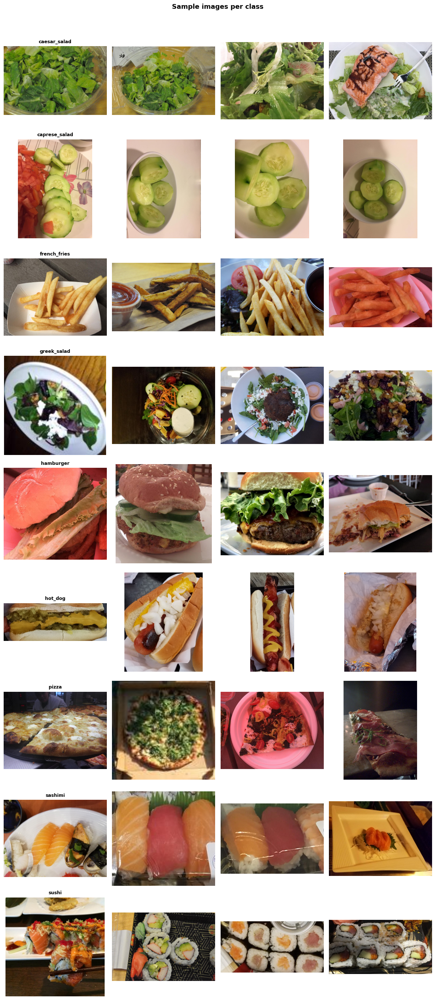

In [4]:
def show_samples(dataset_path, classes, n_per_class=4):
    fig, axes = plt.subplots(len(classes), n_per_class,
                             figsize=(n_per_class*3, len(classes)*3))
    for row, cls in enumerate(classes):
        cls_path = os.path.join(dataset_path, cls)
        imgs = [f for f in os.listdir(cls_path) if f.lower().endswith((".jpg",".jpeg",".png"))]
        samples = random.sample(imgs, min(n_per_class, len(imgs)))
        for col in range(n_per_class):
            ax = axes[row, col] if len(classes) > 1 else axes[col]
            if col < len(samples):
                ax.imshow(mpimg.imread(os.path.join(cls_path, samples[col])))
                ax.set_title(cls if col == 0 else "", fontsize=9, fontweight="bold")
            ax.axis("off")
    plt.suptitle("Sample images per class", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout(); plt.show()

show_samples(dataset_path, classes, n_per_class=4)

### 2.3 Image properties

The next step was to analyze the dimensional properties of the images in the
dataset, including width, height, aspect ratio, and color channels. This step
is crucial because most CNN architectures require inputs of fixed dimensions:
knowing the actual distribution of sizes allows us to choose a reasonable
resize value (one that does not distort the images excessively) and to verify
that there are no corrupted files or incompatible channel formats.

The images vary widely in size: width ranges from 59 to 3,783 px and height
from 64 to 4,320 px, with averages of 820 and 660 respectively. The fact that
the median and mean are fairly close (1008 vs. 820 for width, 712 vs. 660 for
height) indicates that most images fall within a moderate range, with a few
very large outliers raising the mean (visible in the scatter plot as the
isolated points in the upper right).

The aspect ratio is interesting: the average value is 1.30 and the most
frequent value (the peak of the histogram) falls around 1.3–1.5, so the images
are predominantly wider than tall. The 1:1 line in the scatter plot shows that
most data points lie slightly below the diagonal, confirming this trend. The
range extends from 0.36 (very vertical) to 3.93 (very horizontal), indicating
that some images have extreme shapes compared to the average.

Regarding color channels, all 978 images are in RGB format without exception —
a positive result since it eliminates the need to handle channel conversions
before preprocessing. Furthermore, no corrupted files were found, so the
dataset is clean in terms of file integrity.

--- Dimensions ---
Width  — min:59, max:3783, mean:820, median:1008
Height — min:64, max:4320, mean:660, median:712
Aspect ratio — min:0.36, max:3.93, mean:1.30, median:1.33

--- Color channels ---
  RGB: 978

✓ No corrupted files


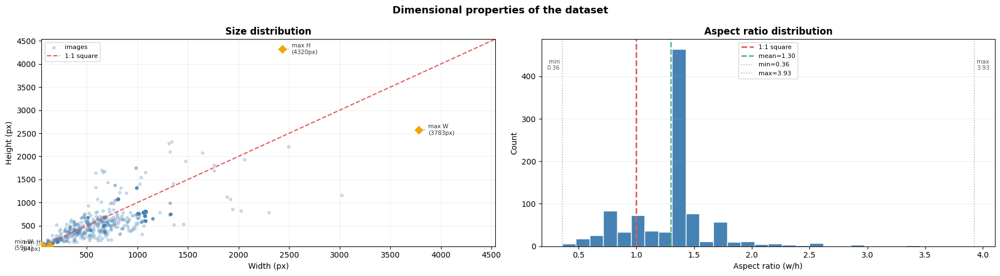

In [5]:
sizes, channels, broken = [], [], []
for cls in classes:
    cls_path = os.path.join(dataset_path, cls)
    for fname in os.listdir(cls_path):
        if not fname.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")): continue
        fpath = os.path.join(cls_path, fname)
        try:
            with Image.open(fpath) as img:
                sizes.append(img.size); channels.append(img.mode)
        except Exception as e:
            broken.append((fpath, str(e)))
widths, heights = zip(*sizes)
ratios = [w/h for w,h in sizes]
mode_counts = Counter(channels)
w_arr = np.array(widths)
h_arr = np.array(heights)
r_arr = np.array(ratios)

# ── Stats ───────────────────────────────────────────────────────────────
print("--- Dimensions ---")
print(f"Width  — min:{w_arr.min()}, max:{w_arr.max()}, mean:{w_arr.mean():.0f}, median:{np.median(w_arr):.0f}")
print(f"Height — min:{h_arr.min()}, max:{h_arr.max()}, mean:{h_arr.mean():.0f}, median:{np.median(h_arr):.0f}")
print(f"Aspect ratio — min:{r_arr.min():.2f}, max:{r_arr.max():.2f}, mean:{r_arr.mean():.2f}, median:{np.median(r_arr):.2f}")
print("\n--- Color channels ---")
for mode, count in mode_counts.items(): print(f"  {mode}: {count}")
non_rgb = sum(1 for m in channels if m != "RGB")
if non_rgb: print(f"  ⚠ {non_rgb} non-RGB images")
print(f"\n{'⚠ '+str(len(broken))+' corrupted files' if broken else '✓ No corrupted files'}")

# ── Plots ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# ── Scatter width vs height ──────────────────────────────────────
ax = axes[0]
ax.scatter(widths, heights, alpha=0.25, s=12, color="steelblue", label="images")

# 1:1 Aspect ratio (square image)
all_vals = list(widths) + list(heights)
lim_min, lim_max = min(all_vals) * 0.9, max(all_vals) * 1.05
ax.plot([lim_min, lim_max], [lim_min, lim_max],
        color="#e05c5c", linewidth=1.5, linestyle="--", label="1:1 square")

# min/max
idx_wmin = w_arr.argmin(); idx_wmax = w_arr.argmax()
idx_hmin = h_arr.argmin(); idx_hmax = h_arr.argmax()
for idx, label, ha in [
    (idx_wmin, f"min W\n({w_arr[idx_wmin]}px)", "right"),
    (idx_wmax, f"max W\n({w_arr[idx_wmax]}px)", "left"),
    (idx_hmin, f"min H\n({h_arr[idx_hmin]}px)", "right"),
    (idx_hmax, f"max H\n({h_arr[idx_hmax]}px)", "left"),
]:
    ax.annotate(label,
                xy=(widths[idx], heights[idx]),
                xytext=(12 if ha == "left" else -12, 0),
                textcoords="offset points",
                ha=ha, va="center", fontsize=7.5, color="#333333",
                arrowprops=dict(arrowstyle="-", color="#aaaaaa", lw=0.8))
    ax.scatter([widths[idx]], [heights[idx]], s=50, color="#f0a500", zorder=5, marker="D")

ax.set_xlim(lim_min, lim_max); ax.set_ylim(lim_min, lim_max)
ax.set_xlabel("Width (px)"); ax.set_ylabel("Height (px)")
ax.set_title("Size distribution", fontweight="bold")
ax.legend(fontsize=8); ax.grid(alpha=0.2)

# ── Histogram aspect ratio ──────────────────────────────────────
ax = axes[1]
n, _, _ = ax.hist(r_arr, bins=30, color="steelblue", edgecolor="white")
ax.axvline(1.0,          color="#e05c5c", linewidth=2,   linestyle="--", label="1:1 square")
ax.axvline(r_arr.mean(), color="#4caf7d", linewidth=1.8, linestyle="--",
           label=f"mean={r_arr.mean():.2f}")
ax.axvline(r_arr.min(),  color="#aaaaaa", linewidth=1.2, linestyle=":",
           label=f"min={r_arr.min():.2f}")
ax.axvline(r_arr.max(),  color="#aaaaaa", linewidth=1.2, linestyle=":",
           label=f"max={r_arr.max():.2f}")
ax.text(r_arr.min() - 0.02, n.max() * 0.95, f"min\n{r_arr.min():.2f}",
        ha="right", va="top", fontsize=7.5, color="#555555")
ax.text(r_arr.max() + 0.02, n.max() * 0.95, f"max\n{r_arr.max():.2f}",
        ha="left",  va="top", fontsize=7.5, color="#555555")
ax.set_xlabel("Aspect ratio (w/h)"); ax.set_ylabel("Count")
ax.set_title("Aspect ratio distribution", fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.2)

plt.suptitle("Dimensional properties of the dataset", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

### 2.4 Class distribution (PRE-cleaning)

The resulting imbalance ratio is 19.93x, classified as "Strong imbalance".
Pizza alone occupies 30.6% of the dataset, while the three salad categories
combined represent less than 7%. Only sushi (+14.1%) falls within an acceptable
range relative to the average; all other 8 classes exceed the ±30% threshold,
with 4 classes overrepresented (pizza, hamburger, french_fries, and marginally
sushi) and 5 strongly underrepresented (sashimi, hot_dog, and the three salads).

This level of imbalance has practical implications for subsequent stages:
accuracy alone would be a rather meaningless metric. Furthermore, strategies
such as class weights or data augmentation should be considered during training.


pizza                299
hamburger            238
french_fries         181
sushi                124
sashimi              40
hot_dog              31
caesar_salad         26
greek_salad          24
caprese_salad        15


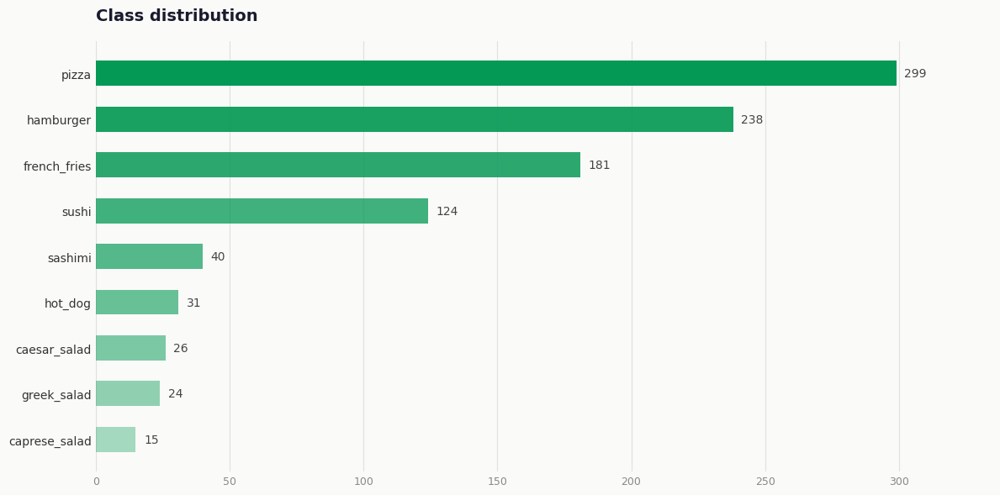

In [57]:
sorted_counts = dict(sorted(class_counts.items(), key=lambda x: x[1], reverse=True))

for cls, count in sorted_counts.items():
    print(f"{cls:<20} {count}")

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#FAFAF8')
ax.set_facecolor('#FAFAF8')

classes = list(sorted_counts.keys())
counts = list(sorted_counts.values())
n = len(classes)

# Palette verde
base_color = "#049955"
alphas = np.linspace(1.0, 0.35, n)
colors = [(4/255, 153/255, 85/255, a) for a in alphas]

bars = ax.barh(classes, counts, color=colors, height=0.55, zorder=3)

# Value labels at the end of the bar
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_width() + max(counts) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}",
        va='center', ha='left',
        fontsize=10, color='#444444',
        fontfamily='DejaVu Sans'
    )

# Thin vertical grid
ax.xaxis.grid(True, color='#E0E0DC', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

# Remove borders
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis='y', length=0, labelsize=10, colors='#333333')
ax.tick_params(axis='x', length=0, labelsize=9, colors='#888888')
ax.set_xlim(0, max(counts) * 1.12)
ax.invert_yaxis()

ax.set_title("Class distribution", fontsize=14, fontweight='bold',
             color='#1A1A2E', pad=18, loc='left')

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=180, bbox_inches='tight', facecolor='#FAFAF8')
plt.show()

## **3. Data cleaning**

### 3.1 Helper functions

Data cleaning has been a fundamental step in this work for several reasons.
During the EDA we discovered the presence of some wrongly classified images.
After a further manual analysis, additional problems emerged: images that needed
to be deleted and the presence of duplicates.

Before starting the cleaning phase, two helper functions are defined:
  1. find_file(folder, name): searches for a file in a folder by its filename.
     Useful for deleting or moving specific files.
  2. file_hash(path): computes the MD5 hash of a file reading it in 64 KB
     blocks. Two files with identical hashes are exact duplicates. Used in the
     next section to find duplicate images in the dataset.


In [7]:
def find_file(folder, name):
    if not os.path.exists(folder): return None
    for f in os.listdir(folder):
        if os.path.splitext(f)[0] == name: return os.path.join(folder, f)
    return None

def file_hash(path, block=65536):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while chunk := f.read(block): h.update(chunk)
    return h.hexdigest()

### 3.2 Eliminations

The first cleaning step consisted of manually deleting images that, upon visual
inspection, were considered too ambiguous or clearly incorrect. These were
images that even we, as human observers, could not confidently assign to the
correct category.

The code iterates over a predefined list of 35 images to delete (to_delete),
uses the find_file() helper to locate each file regardless of its extension,
and removes it with os.remove(). At the end, a summary is printed showing how
many files were successfully deleted and which ones, if any, were not found.


In [8]:
to_delete = [
    ("french_fries","french_fries_28"), ("french_fries","french_fries_19"),
    ("french_fries","cropfries54"),     ("french_fries","cropfries46"),
    ("french_fries","cropfries40"),
    ("sashimi","sashimi_105"),
    ("pizza","pizza_313"), ("pizza","pizza_269"), ("pizza","pizza_227"),
    ("hamburger","hamburger_688"), ("hamburger","hamburger_687"), ("hamburger","hamburger_686"),
    ("hamburger","hamburger_685"), ("hamburger","hamburger_684"), ("hamburger","hamburger_683"),
    ("hamburger","hamburger_670"), ("hamburger","hamburger_669"), ("hamburger","hamburger_668"),
    ("hamburger","hamburger_667"), ("hamburger","hamburger_666"), ("hamburger","hamburger_665"),
    ("hamburger","hamburger_662"), ("hamburger","hamburger_632"), ("hamburger","hamburger_631"),
    ("hamburger","hamburger_601"), ("hamburger","hamburger_573"), ("hamburger","hamburger_532"),
    ("hamburger","hamburger_531"), ("hamburger","hamburger_523"), ("hamburger","hamburger_522"),
    ("hamburger","hamburger_521"), ("hamburger","hamburger_520"),
    ("hamburger","cropburger4"),   ("hamburger","cropburger3"),   ("hamburger","cropburger22"),
]
deleted, not_deleted = 0, []
for cls, name in to_delete:
    p = find_file(os.path.join(dataset_path, cls), name)
    if p: os.remove(p); deleted += 1
    else: not_deleted.append((cls, name))
print(f"Deleted: {deleted}/{len(to_delete)}")
if not_deleted:
    print("⚠ Not found:")
    for cls, name in not_deleted: print(f"  {cls}/{name}")

Deleted: 35/35


### 3.3 Reclassifications

The second step concerned the reclassification of misclassified images. During
manual inspection we identified images placed in the wrong category: two sushi
images that were actually sashimi (sushi_6 and sushi_128), and one image of
french fries mistakenly placed in the hamburger folder (french_fries_647).
Instead of deleting them — since they were valid images, just wrongly placed —
we moved them to the correct class folder.

The code iterates over the to_move list and uses find_file() to locate each
file, then moves it to the correct destination folder using shutil.move().


In [9]:
to_move = [
    ("sushi",     "sushi_6",          "sashimi"),
    ("sushi",     "sushi_128",        "sashimi"),
    ("sashimi",     "crop__sashimi27",   "sushi"),
    ("hamburger", "french_fries_647", "french_fries"),
]
moved, not_moved = 0, []
for src_cls, name, dst_cls in to_move:
    p = find_file(os.path.join(dataset_path, src_cls), name)
    if p:
        dst = os.path.join(dataset_path, dst_cls)
        os.makedirs(dst, exist_ok=True)
        shutil.move(p, os.path.join(dst, os.path.basename(p)))
        moved += 1
    else: not_moved.append((src_cls, name))
print(f"Moved: {moved}/{len(to_move)}")
if not_moved:
    print("⚠ Not found:")
    for cls, name in not_moved: print(f"  {cls}/{name}")

Moved: 4/4


### 3.4 Duplicate detection

The third step consisted of detecting and removing exact duplicate images. After
cleaning the obvious misclassifications, we needed to ensure that no identical
images appeared multiple times — either within the same class or across
different classes — as duplicates introduce a form of data leakage and bias
model training.

The code computes the MD5 hash of every image using the file_hash() helper and
stores each hash in a dictionary (hash_map). If the same hash is encountered
more than once, the file is flagged as a duplicate. This approach guarantees
that two images are identical at the byte level, regardless of filename.

The detection revealed 46 exact duplicates, all within the same class
(intra-class duplicates). The affected classes were:
  - hamburger: 20 duplicates (the most affected class)
  - french_fries: 13 duplicates
  - pizza: 7 duplicates
  - sushi: 4 duplicates
  - caesar_salad: 3 duplicates

These duplicates were subsequently removed, keeping only one copy of each
image. This step is particularly important because duplicate images in the
training set would cause the model to see the same image multiple times,
artificially inflating its performance and reducing its ability to generalize.


In [10]:
classes_current = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
hash_map = {}; duplicates = []
for cls in classes_current:
    cls_path = os.path.join(dataset_path, cls)
    for fname in os.listdir(cls_path):
        if not fname.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")): continue
        fpath = os.path.join(cls_path, fname)
        h = file_hash(fpath)
        if h in hash_map: duplicates.append((fpath, hash_map[h]))
        else: hash_map[h] = fpath
if duplicates:
    print(f"⚠ {len(duplicates)} duplicates found:")
    for dup, original in duplicates: print(f"  {dup}  ==  {original}")
else:
    print("✓ No duplicates found")

⚠ 46 duplicates found:
  ExampleFoodImageDataset/caesar_salad/smaller_salad (103).jpg  ==  ExampleFoodImageDataset/caesar_salad/smaller_salad (100).jpg
  ExampleFoodImageDataset/caesar_salad/smaller_salad (101).jpg  ==  ExampleFoodImageDataset/caesar_salad/smaller_salad (104).jpg
  ExampleFoodImageDataset/caesar_salad/smaller_salad (105).jpg  ==  ExampleFoodImageDataset/caesar_salad/smaller_salad (102).jpg
  ExampleFoodImageDataset/french_fries/french_fries_111.jpg  ==  ExampleFoodImageDataset/french_fries/french_fries_98.jpg
  ExampleFoodImageDataset/french_fries/french_fries_103.jpg  ==  ExampleFoodImageDataset/french_fries/french_fries_116.jpg
  ExampleFoodImageDataset/french_fries/french_fries_97.jpg  ==  ExampleFoodImageDataset/french_fries/french_fries_110.jpg
  ExampleFoodImageDataset/french_fries/french_fries_104.jpg  ==  ExampleFoodImageDataset/french_fries/french_fries_91.jpg
  ExampleFoodImageDataset/french_fries/french_fries_101.jpg  ==  ExampleFoodImageDataset/french_fries

### 3.5 Displaying duplicate pairs

Before proceeding with deletion, we performed a visual verification step to
confirm that the flagged pairs were indeed identical. For each of the 46 pairs,
the code displays the original and the duplicate side by side. This is good practice in data cleaning: since os.remove()
cannot be undone, it is always preferable to visually inspect the data first.


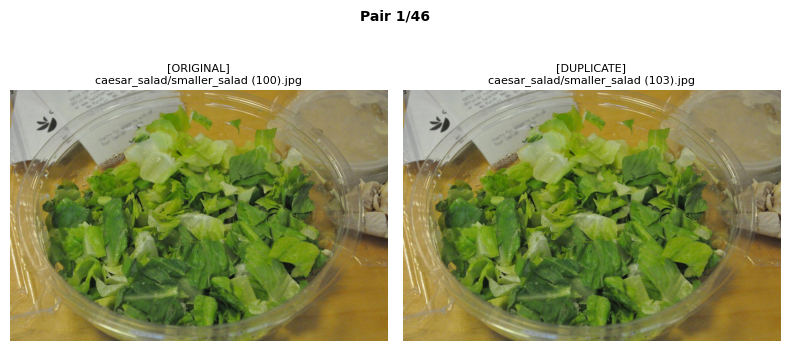

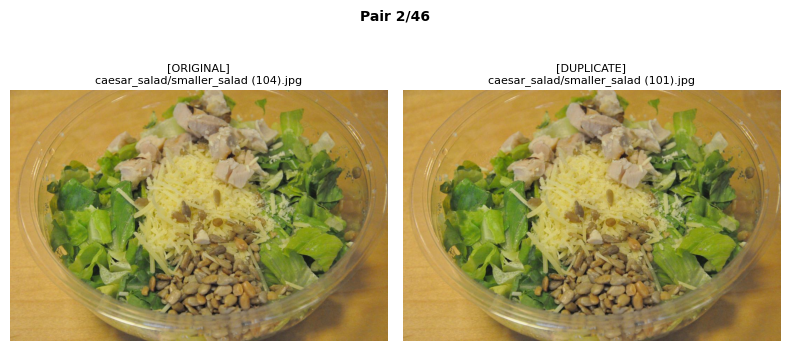

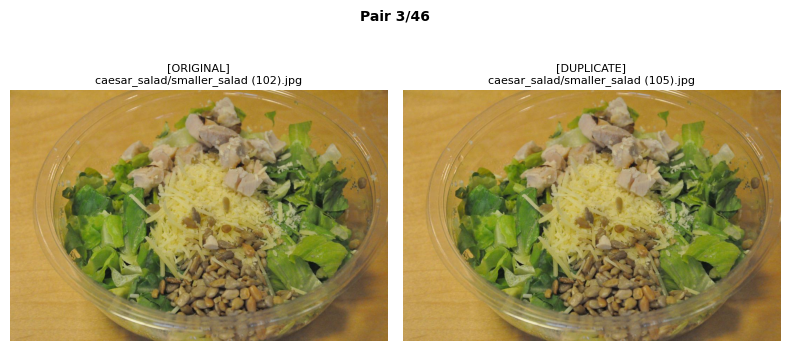

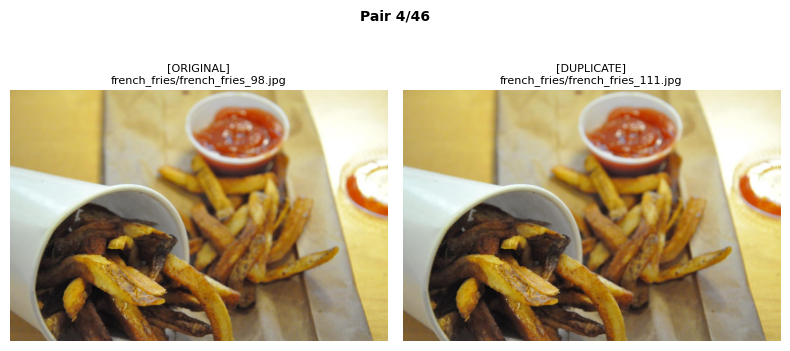

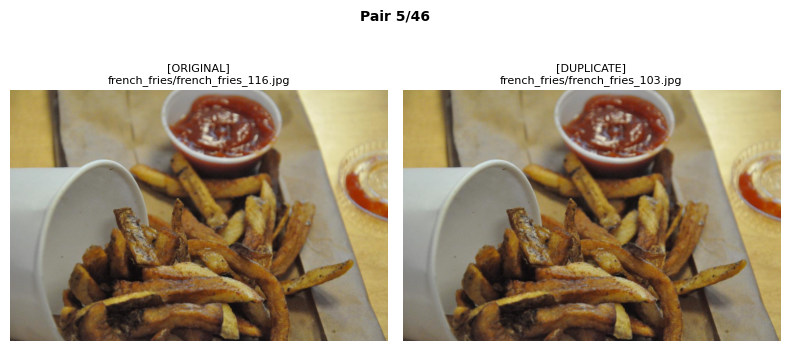

...

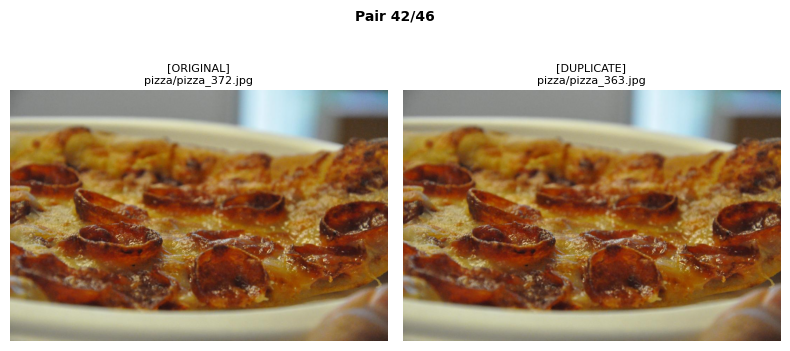

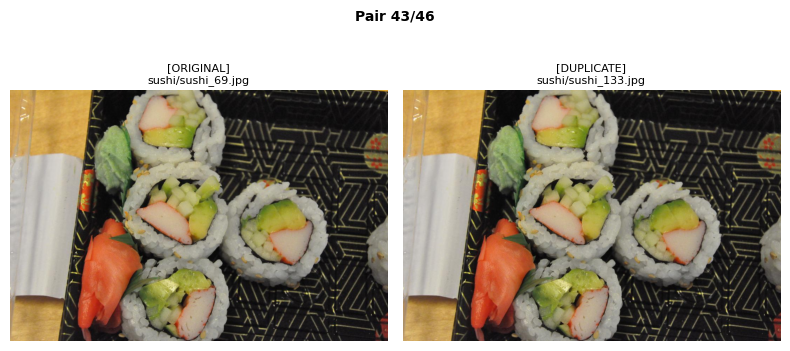

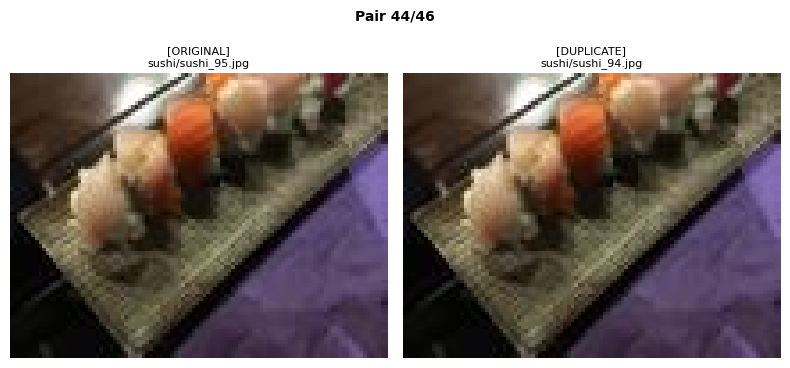

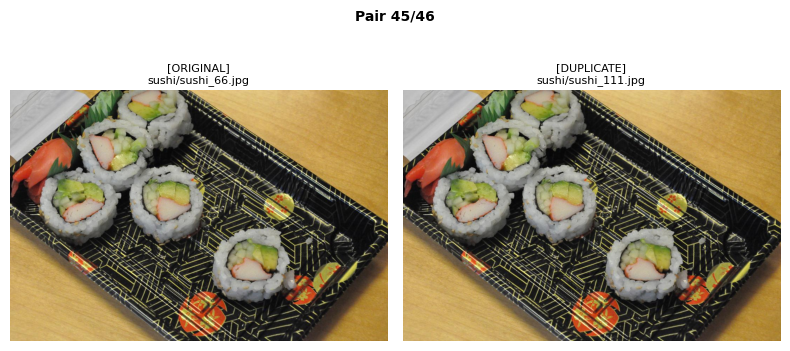

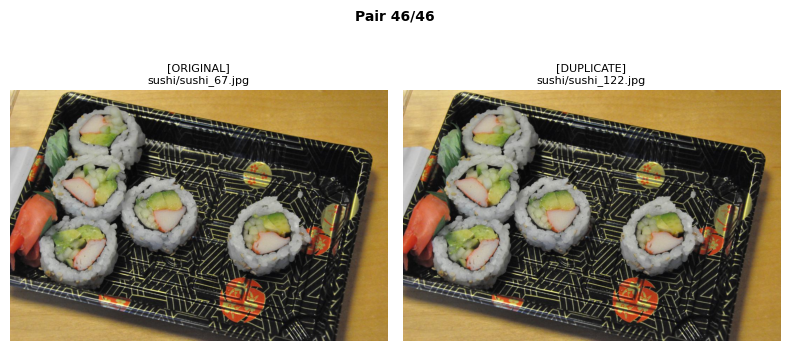

In [11]:
for i, (dup, original) in enumerate(duplicates):
    fig, axes = plt.subplots(1,2,figsize=(8,4))
    for ax, path, label in zip(axes, [original, dup], ["ORIGINAL","DUPLICATE"]):
        try: ax.imshow(mpimg.imread(path))
        except: ax.text(0.5, 0.5, "Read error", ha="center", va="center")
        ax.set_title(f"[{label}]\n{os.path.relpath(path, dataset_path)}", fontsize=8)
        ax.axis("off")
    plt.suptitle(f"Pair {i+1}/{len(duplicates)}", fontsize=10, fontweight="bold")
    plt.tight_layout(); plt.show()

### 3.6 Removing duplicates

Once visually confirmed that all flagged pairs were identical, we proceeded with
their deletion. The code iterates over the duplicates list and removes each
duplicate file using os.remove(), keeping the original copy intact. The
os.path.exists() check before each deletion is a safety measure to avoid errors
in case a file had already been removed in a previous run.

In [12]:
dup_files_removed = 0
for dup, _ in duplicates:
    if os.path.exists(dup): os.remove(dup); dup_files_removed += 1
print(f"{dup_files_removed} duplicates removed")

46 duplicates removed


### 3.7 Similar photo

After removing exact duplicates, we also checked for visually similar images. This step is different from duplicate detection: duplicates are identical files, while similar images are not exactly the same but may show the same food, the same plate, or a very similar scene from a slightly different angle.

To detect these cases, we used perceptual hashing (phash) with the imagehash library. For each image, a perceptual hash was computed. Then, pairs of images with a hash distance lower than or equal to a fixed threshold were considered visually similar. These images were grouped using a Union-Find structure, so that each group contained images that were connected by visual similarity.

Unlike exact duplicates, these similar images were not removed. Since the dataset is already small, deleting them would have reduced the amount of training data too much. Instead, the groups were kept and used later during the train-validation-test split.

This is important to avoid data leakage. If two very similar images ended up in different splits, for example one in the training set and one in the test set, the model could be evaluated on images that are almost the same as those seen during training. This would make the final performance look better than it really is.

For this reason, the similar-image groups were used in the group-aware split, ensuring that visually similar images always stay in the same subset.


In [13]:
!pip install imagehash -q
import imagehash
from PIL import Image
from collections import defaultdict

THRESHOLD = 14

print("Calculating the hash for all images...")
hashes = {}
classes_current = sorted([d for d in os.listdir(dataset_path)
                           if os.path.isdir(os.path.join(dataset_path, d))])
all_files = []
for cls in classes_current:
    cls_path = os.path.join(dataset_path, cls)
    for fname in sorted(os.listdir(cls_path)):
        if fname.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")):
            fpath = os.path.join(cls_path, fname)
            all_files.append((cls, fpath))
            hashes[fpath] = imagehash.phash(Image.open(fpath).convert("RGB"))

print(f"✓ {len(hashes)} hash calculated")

# Union-Find per raggruppare simili
parent = {fpath: fpath for _, fpath in all_files}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

def union(x, y):
    parent[find(x)] = find(y)

paths = [fpath for _, fpath in all_files]
for i in range(len(paths)):
    for j in range(i+1, len(paths)):
        if hashes[paths[i]] - hashes[paths[j]] <= THRESHOLD:
            union(paths[i], paths[j])

groups = defaultdict(list)
for cls, fpath in all_files:
    groups[find(fpath)].append((cls, fpath))

multi_groups = [g for g in groups.values() if len(g) > 1]
print(f"✓ Groups with similar images: {len(multi_groups)}")
print(f"✓ Individual images (no similar images): {len(groups) - len(multi_groups)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.1 MB/s eta 0:00:00
Calculating the hash for all images...
✓ 897 hash calculated
✓ Groups with similar images: 29
✓ Individual images (no similar images): 833


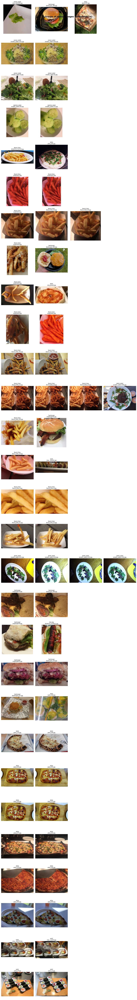

In [14]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

N_SHOW = len(multi_groups)
if N_SHOW == 0:
    print("✓ No similar groups found")
else:
    max_cols = max(len(g) for g in multi_groups[:N_SHOW])
    fig, axes = plt.subplots(N_SHOW, max_cols, figsize=(max_cols*3, N_SHOW*3))
    if N_SHOW == 1: axes = [axes]

    for row, group in enumerate(multi_groups[:N_SHOW]):
        for col in range(max_cols):
            ax = axes[row][col] if max_cols > 1 else axes[row]
            if col < len(group):
                cls, fpath = group[col]
                ax.imshow(mpimg.imread(fpath))
                ax.set_title(f"{cls}\n{os.path.basename(fpath)}", fontsize=7)
            ax.axis("off")

    plt.suptitle(f"Groups of similar images (threshold={THRESHOLD})",
                 fontweight="bold", fontsize=13)
    plt.tight_layout(); plt.show()

### 3.8 CLEANING SUMMARY

In [15]:
print("========== CLEANING SUMMARY ==========")
salad_classes = ["caesar_salad", "caprese_salad", "greek_salad"]

print(f"  Deleted           : {deleted}/{len(to_delete)}")
print(f"  Moved      : {moved}/{len(to_move)}")
# FIX ERRORE 15: stampa lo stato reale del merge invece di suggerire sempre il merge
print(f"  Salad merge         : DISABLED — classes kept separate: {salad_classes}")
print(f"  Duplicates removed   : {dup_files_removed}")
if not_deleted or not_moved:
    print("\n  ⚠ Files NOT found:")
    for cls, name in not_deleted: print(f"    [DELETE] {cls}/{name}")
    for cls, name in not_moved:   print(f"    [MOVE]   {cls}/{name}")
else:
    print("  ✓ All files processed successfully")

========== CLEANING SUMMARY ==========
  Deleted           : 35/35
  Moved      : 4/4
  Salad merge         : DISABLED — classes kept separate: ['caesar_salad', 'caprese_salad', 'greek_salad']
  Duplicates removed   : 46
  ✓ All files processed successfully


### 3.10 EDA post-pulizia

Once the cleaning phase was completed, a post-cleaning EDA was performed to
assess the impact of the operations carried out. The code recomputes the class
distribution on the cleaned dataset and produces a direct PRE/POST comparison
for each class, showing the delta in image count. The imbalance ratio is also
recomputed to verify whether the cleaning operations improved or worsened the
overall balance.

The post-cleaning EDA confirms that the cleaning pipeline removed a total of 81
images, bringing the dataset from 978 to 897 images. The most affected class
was hamburger (-47), due to the large number of duplicates and manually deleted
images, followed by french_fries (-16) and pizza (-10). Interestingly, sashimi
gained one image (+1) as a result of the reclassification step.

Regarding class imbalance, the cleaning had minimal impact: the imbalance ratio
dropped only slightly from 19.93x to 19.27x, meaning the dataset remains
strongly imbalanced. This was expected, since the cleaning operations targeted
incorrect and duplicate images rather than the imbalance itself. The three salad
classes remain the most underrepresented, with caprese_salad still at only 15
images, confirming that class imbalance will need to be addressed during
training through strategies such as class weighting.

=== PRE/POST Cleaning Comparison ===
Class                   PRE   POST  Delta
------------------------------------------
caesar_salad             26     23     -3
caprese_salad            15     15     +0
french_fries            181    165    -16
greek_salad              24     24     +0
hamburger               238    191    -47
hot_dog                  31     31     +0
pizza                   299    289    -10
sashimi                  40     40     +0
sushi                   124    119     -5
Total  PRE : 978  |  POST: 897  |  Delta: -81


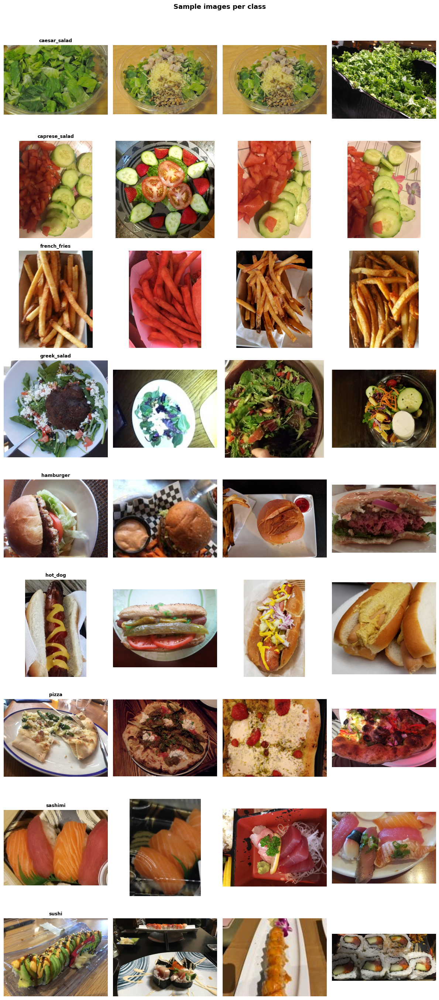

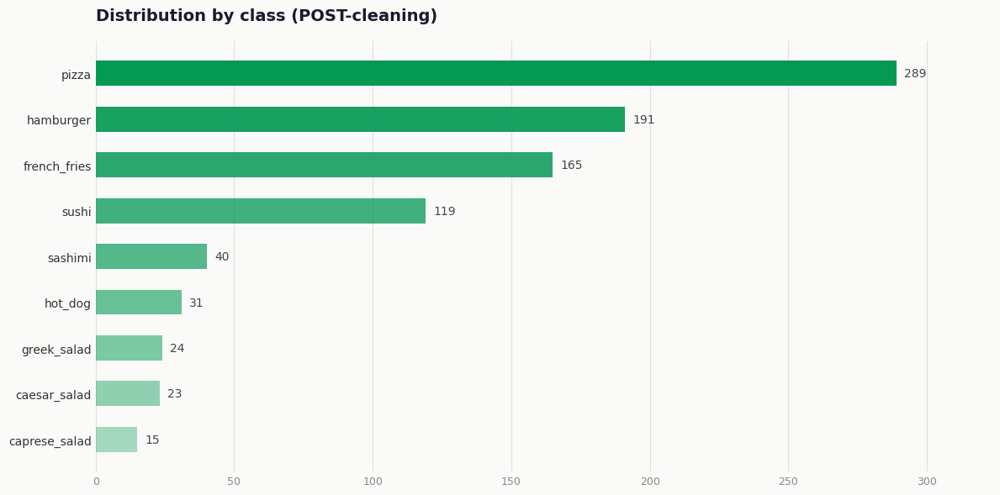

In [59]:
classes_clean = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
class_counts_clean = {}
for cls in classes_clean:
    imgs = [f for f in os.listdir(os.path.join(dataset_path, cls))
            if f.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp"))]
    class_counts_clean[cls] = len(imgs)
total_clean = sum(class_counts_clean.values())
sorted_clean = dict(sorted(class_counts_clean.items(), key=lambda x: x[1], reverse=True))
counts_clean = np.array(list(sorted_clean.values()))
mean_clean = counts_clean.mean()
imbalance_clean = counts_clean.max() / counts_clean.min()

print("=== PRE/POST Cleaning Comparison ===")
print(f"{'Class':<20} {'PRE':>6} {'POST':>6} {'Delta':>6}"); print("-"*42)
all_cls = sorted(set(list(class_counts.keys()) + list(class_counts_clean.keys())))
for cls in all_cls:
    pre = class_counts.get(cls, 0); post = class_counts_clean.get(cls, 0); delta = post - pre
    flag = " (new)" if pre == 0 else " (removed)" if post == 0 else ""
    print(f"{cls:<20} {pre:>6} {post:>6} {delta:>+6}{flag}")
print(f"Total  PRE : {total}  |  POST: {total_clean}  |  Delta: {total_clean-total:+d}")
show_samples(dataset_path, classes_clean, n_per_class=4)


fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#FAFAF8')
ax.set_facecolor('#FAFAF8')

classes = list(sorted_clean.keys())
counts = list(sorted_clean.values())
n = len(classes)

alphas = np.linspace(1.0, 0.35, n)
colors = [(4/255, 153/255, 85/255, a) for a in alphas]

bars = ax.barh(classes, counts, color=colors, height=0.55, zorder=3)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_width() + max(counts) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,}",
        va='center', ha='left',
        fontsize=10, color='#444444',
        fontfamily='DejaVu Sans'
    )

ax.xaxis.grid(True, color='#E0E0DC', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis='y', length=0, labelsize=10, colors='#333333')
ax.tick_params(axis='x', length=0, labelsize=9, colors='#888888')
ax.set_xlim(0, max(counts) * 1.12)
ax.invert_yaxis()

ax.set_title("Distribution by class (POST-cleaning)", fontsize=14, fontweight='bold',
             color='#1A1A2E', pad=18, loc='left')

plt.tight_layout()
plt.savefig("class_distribution_post.png", dpi=180, bbox_inches='tight', facecolor='#FAFAF8')
plt.show()

## **4. Train — Validation — Test Split, taking similar items in account**

After completing the data cleaning phase, the next step was to split the dataset
into three subsets: training set (70%), validation set (15%), and test set (15%).

This subdivision is fundamental for several reasons. The training set is the
portion of data the model actually learns from. The validation set is used
during training to monitor performance and tune hyperparameters, without ever
influencing the learning process directly. The test set is kept completely
untouched until the very end, and is used only once to evaluate the final model
on truly unseen data, providing an unbiased estimate of its real-world
performance.

The 70/15/15 split is a standard and widely used choice: it reserves enough data
for training while still having meaningful validation and test sets. Given the
small size of our dataset (897 images), this ratio represents a reasonable
trade-off.

A particularly important aspect of this split is that it is both stratified and
group-aware. Stratification ensures that each subset maintains the same class
distribution as the original dataset, which is especially important given the
strong class imbalance. The group-aware strategy goes one step further: images
that are visually similar (near-duplicates detected via perceptual hashing) are
always assigned to the same split, preventing a subtle form of data leakage
where slightly different versions of the same image could end up in both the
training and test set, artificially inflating the model's performance.

The output confirms that the split was performed correctly. Global proportions
are very close to the target ratios. The small deviations from the exact
70/15/15 target are expected and due to the group-aware constraint, which forces
entire groups of similar images to stay together.

Looking at the per-class stratification, the distribution is well maintained
across all classes, with only minor deviations for the smallest classes
(caesar_salad, caprese_salad, greek_salad), where the low total number of
images makes a perfectly proportional split inherently difficult. For example,
caprese_salad has only 15 images in total, resulting in just 2 images for both
val and test.

⚠ Rimossi 18 file non trovati dal df_split (eliminati in §3)
✓ Split caricato da Drive

Totale immagini: 879
  train      620  (70.5%)
  val        128  (14.6%)
  test       131  (14.9%)

=== Verifica stratificazione ===
  caesar_salad         total=  22  train= 15 (68%)  val=  4 (18%)  test=  3 (14%)
  caprese_salad        total=  15  train= 11 (73%)  val=  2 (13%)  test=  2 (13%)
  french_fries         total= 160  train=113 (71%)  val= 22 (14%)  test= 25 (16%)
  greek_salad          total=  24  train= 18 (75%)  val=  3 (12%)  test=  3 (12%)
  hamburger            total= 183  train=127 (69%)  val= 28 (15%)  test= 28 (15%)
  hot_dog              total=  31  train= 22 (71%)  val=  5 (16%)  test=  4 (13%)
  pizza                total= 288  train=204 (71%)  val= 42 (15%)  test= 42 (15%)
  sashimi              total=  40  train= 28 (70%)  val=  6 (15%)  test=  6 (15%)
  sushi                total= 116  train= 82 (71%)  val= 16 (14%)  test= 18 (16%)


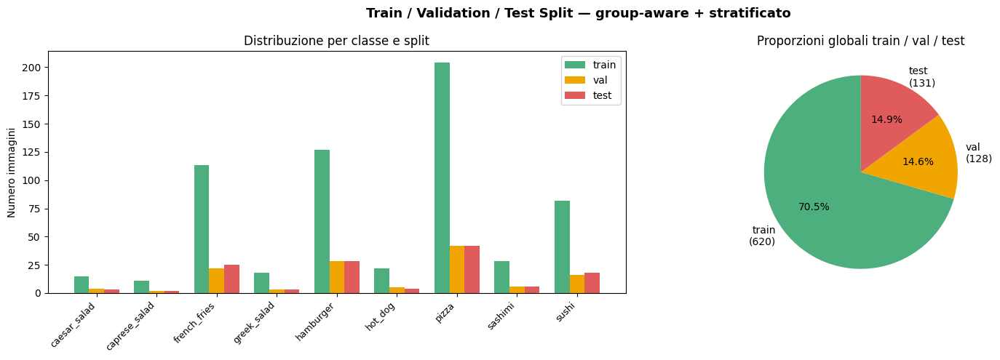

In [17]:
from sklearn.model_selection import train_test_split
from collections import defaultdict

SEED=42; TRAIN_RATIO=0.70; VAL_RATIO=0.15; TEST_RATIO=0.15
assert abs(TRAIN_RATIO+VAL_RATIO+TEST_RATIO-1.0) < 1e-9

_csv = os.path.join(SAVE_DIR, "split_index.csv")
if os.path.exists(_csv):
    df_split = pd.read_csv(_csv)
    df_split["src_path"] = df_split.apply(
        lambda r: os.path.join(dataset_path, r["class"], r["filename"])
                  if not os.path.exists(r["src_path"]) else r["src_path"],
        axis=1
    )
    before = len(df_split)
    df_split = df_split[df_split["src_path"].apply(os.path.exists)].reset_index(drop=True)
    removed = before - len(df_split)
    if removed > 0:
        print(f"⚠ Rimossi {removed} file non trovati dal df_split (eliminati in §3)")

    classes_split = sorted(df_split["class"].unique().tolist())
    split_totals  = df_split["split"].value_counts()
    print("✓ Split caricato da Drive")
else:
    # Fallback: se groups non è definito (§3.8 saltato), costruiscilo ora
    if "groups" not in dir() and "groups" not in globals():
        print("⚠ 'groups' non definito — ricostruzione dal filesystem...")
        try:
            import imagehash
        except ImportError:
            import subprocess; subprocess.run(["pip","install","imagehash","-q"])
            import imagehash
        from PIL import Image as _PIL_Image
        _THRESHOLD = 14
        _classes_now = sorted([d for d in os.listdir(dataset_path)
                                if os.path.isdir(os.path.join(dataset_path, d))])
        _all_files, _hashes = [], {}
        for _cls in _classes_now:
            for _fname in sorted(os.listdir(os.path.join(dataset_path, _cls))):
                if _fname.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")):
                    _fp = os.path.join(dataset_path, _cls, _fname)
                    if os.path.exists(_fp):
                        _all_files.append((_cls, _fp))
                        _hashes[_fp] = imagehash.phash(_PIL_Image.open(_fp).convert("RGB"))
        _parent = {fp: fp for _, fp in _all_files}
        def _find(x):
            while _parent[x] != x:
                _parent[x] = _parent[_parent[x]]; x = _parent[x]
            return x
        _paths = [fp for _, fp in _all_files]
        for _i in range(len(_paths)):
            for _j in range(_i+1, len(_paths)):
                if _hashes[_paths[_i]] - _hashes[_paths[_j]] <= _THRESHOLD:
                    _parent[_find(_paths[_i])] = _find(_paths[_j])
        groups = defaultdict(list)
        for _cls, _fp in _all_files:
            groups[_find(_fp)].append((_cls, _fp))
        print(f"✓ groups ricostruito: {len(groups)} gruppi")

    classes_split = sorted([d for d in os.listdir(dataset_path)
                            if os.path.isdir(os.path.join(dataset_path, d))])

    # Filtra i path che esistono ancora (in caso di pulizia parziale)
    group_list = [
        [(cls, fp) for cls, fp in g if os.path.exists(fp)]
        for g in groups.values()
    ]
    group_list = [g for g in group_list if len(g) > 0]
    group_labels = [g[0][0] for g in group_list]

    train_groups, temp_groups = train_test_split(
        group_list, test_size=1-TRAIN_RATIO,
        random_state=SEED, stratify=group_labels)
    temp_labels = [g[0][0] for g in temp_groups]
    val_groups, test_groups = train_test_split(
        temp_groups, test_size=TEST_RATIO/(VAL_RATIO+TEST_RATIO),
        random_state=SEED, stratify=temp_labels)

    records = []
    for split_name, grps in [("train", train_groups),
                              ("val",   val_groups),
                              ("test",  test_groups)]:
        for group in grps:
            for cls, fpath in group:
                records.append({"class": cls,
                                "filename": os.path.basename(fpath),
                                "src_path": fpath,
                                "split": split_name})

    df_split = pd.DataFrame(records)
    split_totals = df_split["split"].value_counts()
    df_split.to_csv(os.path.join(SAVE_DIR, "split_index.csv"), index=False)
    df_split.to_csv("split_index.csv", index=False)
    print("✓ Split group-aware salvato su Drive")

print(f"\nTotale immagini: {len(df_split)}")
for s in ["train","val","test"]:
    n = split_totals[s]; print(f"  {s:<8} {n:>5}  ({n/len(df_split)*100:.1f}%)")
print("\n=== Verifica stratificazione ===")
for cls in classes_split:
    sub = df_split[df_split["class"]==cls]; n = len(sub)
    tr=(sub["split"]=="train").sum(); va=(sub["split"]=="val").sum(); te=(sub["split"]=="test").sum()
    print(f"  {cls:<20} total={n:>4}  train={tr:>3} ({tr/n*100:.0f}%)  val={va:>3} ({va/n*100:.0f}%)  test={te:>3} ({te/n*100:.0f}%)")

split_order = ["train","val","test"]; split_colors = {"train":"#4caf7d","val":"#f0a500","test":"#e05c5c"}
fig, axes = plt.subplots(1,2,figsize=(16,5))
x = np.arange(len(classes_split)); width = 0.25
for i, split in enumerate(split_order):
    cnts = [df_split[(df_split["class"]==cls)&(df_split["split"]==split)].shape[0] for cls in classes_split]
    axes[0].bar(x+i*width, cnts, width, label=split, color=split_colors[split], edgecolor="none")
axes[0].set_xticks(x+width); axes[0].set_xticklabels(classes_split, rotation=45, ha="right", fontsize=9)
axes[0].set_ylabel("Numero immagini"); axes[0].set_title("Distribuzione per classe e split"); axes[0].legend()
totals = [split_totals[s] for s in split_order]
axes[1].pie(totals, labels=[f"{s}\n({n})" for s,n in zip(split_order,totals)],
            autopct="%1.1f%%", colors=[split_colors[s] for s in split_colors], startangle=90)
axes[1].set_title("Proporzioni globali train / val / test")
plt.suptitle("Train / Validation / Test Split — group-aware + stratificato", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## **5. Preprocessing**

### 5.1 Import and Configuration

The preprocessing phase begins with the import of the necessary libraries and
the definition of the main configuration parameters. The image size is set to
224x224 pixels, which is the standard input size required by the pretrained
backbone architectures used later (EfficientNetV2S, ResNet50, MobileNetV3Large).
The batch size is set to 32, a common choice that balances memory usage and
training stability. AUTOTUNE is set to allow TensorFlow to automatically
optimize the number of parallel calls in the data pipeline at runtime.

In [18]:
import os, time, pickle, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# 5.1 — Preprocessing parameters
IMG_SIZE = 224; BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
print(f"✓ IMG_SIZE={IMG_SIZE}  BATCH_SIZE={BATCH_SIZE}")

✓ IMG_SIZE=224  BATCH_SIZE=32


### 5.2 Loading raw dataset

The second preprocessing step consists of loading the dataset and building the
tf.data pipelines. The code reads the split_index.csv created in the previous
section, extracts the class names and assigns a numerical index to each one,
which is then converted to one-hot encoding.

Two functions are defined for image loading:
  1. load_and_decode: reads each image from disk, decodes it, resizes it to
     224x224 and converts it to float32.
  2. make_dataset: assembles the complete pipeline with automatic parallelism
     (AUTOTUNE), batching of 32 images and prefetch. Shuffle is applied
     exclusively to the training set, so that the model sees images in a
     random order at each epoch.

Class weights are also computed to compensate for class imbalance. Each class
is assigned a weight inversely proportional to its frequency: classes with fewer
images contribute more to the loss, preventing the model from ignoring them.
The weights are capped at 5.0x to avoid very small classes such as
caprese_salad from destabilizing the training.

The output confirms that the pipeline was built correctly. The batch shape
(32, 224, 224, 3) confirms that each batch consists of 32 images of 224x224
pixels with 3 color channels (RGB), while the label shape (32, 9) confirms
the one-hot encoding with 9 classes.

Looking at the class weights, the values reflect the imbalance observed during
the EDA: pizza (0.3410), hamburger (0.5230) and french_fries (0.6210) receive
weights below 1, meaning they contribute less to the loss. On the other hand,
caprese_salad hits the cap at 5.0x, caesar_salad (4.6370) and greek_salad
(4.0915) receive the highest weights, confirming that these are the most
underrepresented classes in the dataset.

In [19]:
class_names  = sorted(df_split["class"].unique().tolist())
NUM_CLASSES  = len(class_names)
cls_to_idx   = {c: i for i, c in enumerate(class_names)}
print(f"Classes ({NUM_CLASSES}): {class_names}")

def load_and_decode(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, label


def make_dataset(df_subset, shuffle=False, seed=42):
    filepaths  = df_subset["src_path"].tolist()
    labels_idx = [cls_to_idx[c] for c in df_subset["class"]]
    labels_oh  = keras.utils.to_categorical(labels_idx, NUM_CLASSES).astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels_oh))
    if shuffle:
        ds = ds.shuffle(len(filepaths), seed=seed, reshuffle_each_iteration=True)
    ds = (ds
          .map(load_and_decode, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))
    return ds

ds_train_raw = make_dataset(df_split[df_split["split"] == "train"], shuffle=True,  seed=SEED)
ds_val_raw   = make_dataset(df_split[df_split["split"] == "val"],   shuffle=False, seed=SEED)
ds_test_raw  = make_dataset(df_split[df_split["split"] == "test"],  shuffle=False, seed=SEED)

for images, labels in ds_train_raw.take(1):
    print(f"✓ Batch shape — images: {images.shape}  labels: {labels.shape}")
print("✓ Datasets ready from split_index.csv")

from sklearn.utils.class_weight import compute_class_weight
y_train_int = [cls_to_idx[c] for c in df_split[df_split['split']=='train']['class']]

cw_values_raw = compute_class_weight('balanced',
                                     classes=np.arange(NUM_CLASSES),
                                     y=y_train_int) #class_weight = total_count / (number_of_classes × number_of_images_per_class)

print('Original weights (before the cap):')
for i, cn in enumerate(class_names):
    print(f'  {cn:<22} {cw_values_raw[i]:.4f}')

cw_values = np.clip(cw_values_raw, a_min=None, a_max=5.0)

# The cap of 5.0 was chosen to prevent excessively high weights from destabilizing the training. In our case, this affects only one class (caprese_salad, 6.38 → 5.0), with a marginal impact on the overall balance

print('\nWeights after chapter 5.0×:')
for i, cn in enumerate(class_names):
    changed = " ← captured" if cw_values_raw[i] > 5.0 else ""
    print(f'  {cn:<22} {cw_values[i]:.4f}{changed}')

class_weight_dict = {i: float(cw_values[i]) for i in range(NUM_CLASSES)}

Classes (9): ['caesar_salad', 'caprese_salad', 'french_fries', 'greek_salad', 'hamburger', 'hot_dog', 'pizza', 'sashimi', 'sushi']
✓ Batch shape — images: (32, 224, 224, 3)  labels: (32, 9)
✓ Datasets ready from split_index.csv
Original weights (before the cap):
  caesar_salad           4.5926
  caprese_salad          6.2626
  french_fries           0.6096
  greek_salad            3.8272
  hamburger              0.5424
  hot_dog                3.1313
  pizza                  0.3377
  sashimi                2.4603
  sushi                  0.8401

Weights after chapter 5.0×:
  caesar_salad           4.5926
  caprese_salad          5.0000 ← captured
  french_fries           0.6096
  greek_salad            3.8272
  hamburger              0.5424
  hot_dog                3.1313
  pizza                  0.3377
  sashimi                2.4603
  sushi                  0.8401


### 5.3 Augmentation

The third preprocessing step consists of defining the data augmentation pipeline. Since the dataset is small, data augmentation is useful to increase the variety of the training images and reduce overfitting.

We used a conservative and food-appropriate augmentation strategy. The transformations include horizontal flip, small rotations and zooms of ±10%, and brightness and contrast changes of ±15%. These choices simulate realistic variations in food images, such as different camera angles and lighting conditions.

Hue and saturation changes were not applied because color is an important feature in food classification. For example, changing the color of pizza, french fries or salads could make the image less realistic and confuse the model.


The augmentation choices were intentionally conservative and tailored for food
images:
  - Horizontal flip: a pizza or a hamburger looks the same mirrored, while
    vertical flip is excluded because an upside-down food image would be
    unrealistic.
  - Rotation and zoom: limited to ±10% to simulate slightly different shooting
    angles without distorting the subject too much.
  - Brightness and contrast: varied by ±15% to account for different lighting
    conditions.
  - Hue and saturation adjustments were deliberately excluded, since color is a
    highly discriminative feature for food classification. For example, the
    golden color of french fries or the red of a pizza sauce should not be
    altered.

The visualization grid shows 8 original images in the top row and their
augmented versions in the bottom row, allowing a quick visual sanity check to
confirm that the transformations are realistic and do not distort the images
beyond recognition.

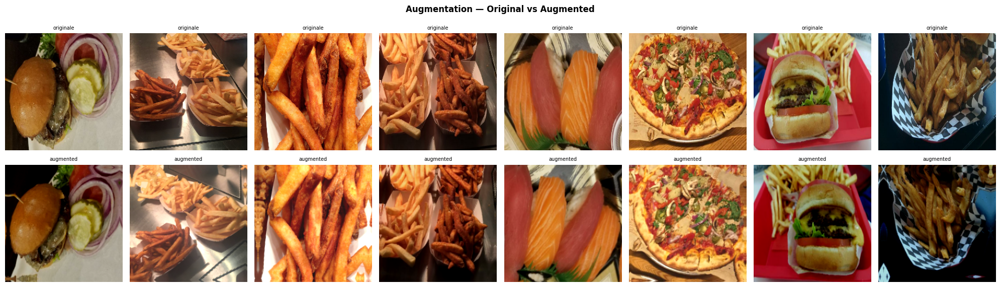

In [20]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=0.10),
    layers.RandomZoom(height_factor=(-0.10, 0.10)),
    layers.RandomContrast(factor=0.15),
    layers.RandomBrightness(factor=0.15),
], name="data_augmentation")
sample_batch, _ = next(iter(ds_train_raw))
augmented_batch  = data_augmentation(sample_batch, training=True)
fig, axes = plt.subplots(2,8,figsize=(20,6))
for i in range(8):
    axes[0,i].imshow(sample_batch[i].numpy().astype("uint8")); axes[0,i].set_title("originale",fontsize=7); axes[0,i].axis("off")
    axes[1,i].imshow(augmented_batch[i].numpy().astype("uint8")); axes[1,i].set_title("augmented",fontsize=7); axes[1,i].axis("off")
plt.suptitle("Augmentation — Original vs Augmented",fontweight="bold"); plt.tight_layout(); plt.show()

### 5.4 Preprocessing pipeline for the backbone & CNN

The final preprocessing step consists of building backbone-specific input pipelines. Each pretrained architecture was originally trained on ImageNet using a particular normalization strategy and therefore expects inputs to be provided in the same format. Using an inconsistent preprocessing would introduce a distribution shift and can significantly reduce performance.

For this reason, separate preprocessing pipelines are defined for each model:

- **EfficientNetV2S** uses `keras.applications.efficientnet_v2.preprocess_input`, which rescales pixel values from `[0, 255]` to `[-1, 1]`

- **ResNet50** uses `keras.applications.resnet50.preprocess_input` following the original Caffe convention. Images are internally converted from RGB to BGR format and the ImageNet channel means `(103.939, 116.779, 123.68)` are subtracted from the B, G and R channels respectively, producing approximately zero-centered inputs.

- **MobileNetV3Large** uses its dedicated `preprocess_input`, which also rescales pixel values to the `[-1, 1]`

- The **CNN trained from scratch** has no pretrained weights to match, therefore a simple normalization is applied by dividing pixel values by 255, resulting in inputs in the `[0, 1]` range.

For each backbone, two versions of the pipeline are defined: one with data augmentation (used only for the training set) and one without augmentation (used for validation and test sets). Augmentation is intentionally excluded from validation and test data because these sets must represent unseen real-world samples and provide an unbiased estimate of model performance.

The `tf.clip_by_value()` operation applied before backbone-specific preprocessing acts as a safety measure. Some augmentation operations, such as brightness and contrast transformations, may generate pixel values outside the valid `[0, 255]` range. Clipping ensures that all augmented images remain valid before being passed to the corresponding preprocessing function.

An additional training pipeline without augmentation (`ds_train_eff_noaug`) is also defined for EfficientNetV2S and is used during fine-tuning and ablation experiments.

In [21]:
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input as effnet_preprocess
from tensorflow.keras.applications.resnet50        import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v3    import preprocess_input as mobile_preprocess

def augment_eff(image, label):
    aug = tf.clip_by_value(tf.cast(data_augmentation(image, training=True), tf.float32), 0.0, 255.0)
    return effnet_preprocess(aug), label
def preprocess_eff(image, label): return effnet_preprocess(tf.cast(image, tf.float32)), label
def augment_res(image, label):
    aug = tf.clip_by_value(tf.cast(data_augmentation(image, training=True), tf.float32), 0.0, 255.0)
    return resnet_preprocess(aug), label
def preprocess_res(image, label): return resnet_preprocess(tf.cast(image, tf.float32)), label
def augment_mob(image, label):
    aug = tf.clip_by_value(tf.cast(data_augmentation(image, training=True), tf.float32), 0.0, 255.0)
    return mobile_preprocess(aug), label
def preprocess_mob(image, label): return mobile_preprocess(tf.cast(image, tf.float32)), label

ds_train_eff = ds_train_raw.map(augment_eff,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_val_eff   = ds_val_raw.map(preprocess_eff,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_test_eff  = ds_test_raw.map(preprocess_eff, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_train_res = ds_train_raw.map(augment_res,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_val_res   = ds_val_raw.map(preprocess_res,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_test_res  = ds_test_raw.map(preprocess_res, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_train_mob = ds_train_raw.map(augment_mob,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_val_mob   = ds_val_raw.map(preprocess_mob,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_test_mob  = ds_test_raw.map(preprocess_mob, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("✓ Pipeline ready (eff / res / mob)")

# Pipeline CNN scratch — normalizzazione [0,1]
def augment_cnn(image, label):
    aug = tf.clip_by_value(tf.cast(data_augmentation(image, training=True), tf.float32), 0.0, 255.0)
    return aug / 255.0, label
def normalize_cnn(image, label): return tf.cast(image, tf.float32) / 255.0, label


ds_train_cnn = ds_train_raw.map(augment_cnn,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_val_cnn   = ds_val_raw.map(normalize_cnn,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
ds_test_cnn  = ds_test_raw.map(normalize_cnn, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("✓ Pipeline CNN scratch ready [0,1]")

ds_train_eff_noaug = ds_train_raw.map(preprocess_eff, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("✓ Pipeline EfficientNetV2S no-aug ready")

✓ Pipeline ready (eff / res / mob)
✓ Pipeline CNN scratch ready [0,1]
✓ Pipeline EfficientNetV2S no-aug ready


## **6. Models**

### Training flag configuration
> Set `True` to train, `False` to load the checkpoint from Drive.

In [22]:
# ══════════════════════════════════════════════════════════
#  FLAG DI TRAINING
# ══════════════════════════════════════════════════════════
TRAIN_CNN     = False
TRAIN_EFFNET  = False
TRAIN_RESNET  = False
TRAIN_MOBILE  =  False
TRAIN_FEATURES= False
TRAIN_SVM     = False
TRAIN_RF      = False
TRAIN_XGB     = False
# ══════════════════════════════════════════════════════════
for name, flag in [("CNN scratch",TRAIN_CNN),("EfficientNetV2S",TRAIN_EFFNET),
                   ("ResNet50",TRAIN_RESNET),("MobileNetV3Large",TRAIN_MOBILE),
                   ("Deep Features",TRAIN_FEATURES),("SVM",TRAIN_SVM),
                   ("Random Forest",TRAIN_RF),("XGBoost",TRAIN_XGB)]:
    print(f"  {name:<20}: {'TRAIN' if flag else 'LOAD CHECKPOINT'}")

  CNN scratch         : LOAD CHECKPOINT
  EfficientNetV2S     : LOAD CHECKPOINT
  ResNet50            : LOAD CHECKPOINT
  MobileNetV3Large    : LOAD CHECKPOINT
  Deep Features       : LOAD CHECKPOINT
  SVM                 : LOAD CHECKPOINT
  Random Forest       : LOAD CHECKPOINT
  XGBoost             : LOAD CHECKPOINT


### Common functions

Before building the actual models, a set of common functions and hyperparameters
are defined that will be shared across all architectures.

Hyperparameters: 15 epochs for the Feature Extractor phase, 30 for Fine-tuning
and 60 for the CNN scratch, with a learning rate of 1e-3 for the Feature
Extractor and 1e-5 for Fine-tuning. This much lower value is necessary to avoid
destroying the pretrained weights during fine-tuning.

build_classifier_head: attaches the same classification head to every backbone:
a Global Average Pooling layer to flatten the feature maps, followed by
Dense(256) with Batch Normalization, ReLU activation and Dropout(0.4) to reduce
overfitting, and finally a softmax output layer with 9 neurons, one per class.

get_callbacks defines three callbacks used during training:
  - EarlyStopping: stops training if val_loss does not improve for 7 consecutive
    epochs.
  - ReduceLROnPlateau: halves the learning rate if val_loss stagnates for 3
    epochs.
  - ModelCheckpoint: saves the best model weights to Drive.

The remaining functions handle utility tasks: plot_history and
plot_confusion_matrix for visualization, get_predictions for computing
predictions on a dataset, and save/load functions for caching predictions,
histories and results to Drive — avoiding costly recomputations after session
crashes. Finally, compute_and_cache_metrics centralizes the evaluation of every
model, computing accuracy, top-3 accuracy, loss, F1 macro, F1 weighted,
inference time and parameter count, and saving everything to
results_checkpoint.pkl.

In [23]:
EPOCHS_FE=15; EPOCHS_FT=30; EPOCHS_CNN=100
LR_FE=1e-3;  LR_FT=1e-5
results = {}

def build_classifier_head(base_model, num_classes):
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.Dense(256, use_bias=False, name="dense1")(x)
    x = layers.BatchNormalization(name="bn_head")(x)
    x = layers.Activation("relu", name="relu_head")(x)
    x = layers.Dropout(0.4, name="dropout_head")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return keras.Model(inputs=base_model.input, outputs=outputs)

def get_callbacks(model_name):
    """Save the best checkpoint to SAVE_DIR."""
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=7,
                                restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                    patience=3, min_lr=1e-7, verbose=1),
        callbacks.ModelCheckpoint(filepath=f"{SAVE_DIR}/best_{model_name}.keras",
                                  monitor="val_loss", save_best_only=True, verbose=1),
    ]

def plot_history(history_dict, title):
    """It accepts both History objects and dict (from pickle)."""
    h = history_dict.history if hasattr(history_dict, "history") else history_dict
    fig, axes = plt.subplots(1,2,figsize=(14,4))
    axes[0].plot(h["loss"],       label="train loss", color="#4caf7d")
    axes[0].plot(h["val_loss"],   label="val loss",   color="#e05c5c")
    axes[0].set_title(f"{title} — Loss"); axes[0].set_xlabel("Epochs")
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(h["accuracy"],     label="train acc",  color="#4caf7d")
    axes[1].plot(h["val_accuracy"], label="val acc",    color="#e05c5c")
    axes[1].set_title(f"{title} — Accuracy"); axes[1].set_xlabel("Epochs")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.suptitle(title, fontweight="bold", fontsize=13); plt.tight_layout(); plt.show()

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(10,8))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"Confusion Matrix — {title}", fontweight="bold")
    plt.tight_layout(); plt.show()

def get_predictions(model, ds):
    y_true, y_pred = [], []
    for images, labels in ds:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))
    return np.array(y_true), np.array(y_pred)

def save_predictions(tag, y_true, y_pred):
    """Save predictions to Drive to avoid recalculations."""
    np.save(f"{SAVE_DIR}/preds_{tag}_true.npy", y_true)
    np.save(f"{SAVE_DIR}/preds_{tag}_pred.npy", y_pred)

def load_predictions(tag):
    """Load predictions from Drive. Return (None, None) if they do not exist."""
    pt = f"{SAVE_DIR}/preds_{tag}_true.npy"
    pp = f"{SAVE_DIR}/preds_{tag}_pred.npy"
    if os.path.exists(pt) and os.path.exists(pp):
        return np.load(pt), np.load(pp)
    return None, None

def save_history(tag, history):
    """Save history to Drive."""
    h = history.history if hasattr(history, "history") else history
    if h is not None:
        with open(f"{SAVE_DIR}/history_{tag}.pkl", "wb") as f:
            pickle.dump(h, f)

def load_history(tag):
    """Load history from Drive. Returns “None” if it does not exist."""
    p = f"{SAVE_DIR}/history_{tag}.pkl"
    if os.path.exists(p):
        with open(p, "rb") as f: return pickle.load(f)
    return None

def evaluate_inference_time(model, ds):
    t = time.time(); n = 0
    for images, _ in ds:
        model.predict(images, verbose=0); n += images.shape[0]
    return (time.time() - t) / n * 1000

def compute_and_cache_metrics(model, ds, ds_tag, model_name, train_time,
                               history_fe, history_ft):
    """
    Calculate metrics (with cached predictions), populate results[model_name],
    update results_checkpoint.pkl.
    """
    y_true, y_pred = load_predictions(ds_tag)
    if y_true is None:
        print(f"  Calculating predictions {ds_tag}...")
        y_true, y_pred = get_predictions(model, ds)
        save_predictions(ds_tag, y_true, y_pred)
    else:
        print(f"  ✓ Predictions {ds_tag} loaded from cache")

    _eval = model.evaluate(ds, verbose=0)
    val_loss = _eval[0]
    val_acc  = _eval[1] if len(_eval) > 1 else 0.0
    val_top3 = _eval[2] if len(_eval) > 2 else None
    f1_mac = f1_score(y_true, y_pred, average="macro")
    f1_wei = f1_score(y_true, y_pred, average="weighted")
    inf_ms = evaluate_inference_time(model, ds)
    try:
        gpu_info = subprocess.check_output(
            ["nvidia-smi","--query-gpu=memory.used,memory.total",
             "--format=csv,noheader,nounits"], encoding="utf-8").strip()
        gpu_used, gpu_total = [int(x.strip()) for x in gpu_info.split(",")]
    except Exception:
        gpu_used, gpu_total = None, None

    h_fe = history_fe.history if hasattr(history_fe,"history") else history_fe
    h_ft = history_ft.history if hasattr(history_ft,"history") else history_ft

    results[model_name] = {
        "val_accuracy": val_acc, "val_top3_accuracy": val_top3, "val_loss": val_loss,
        "f1_macro": f1_mac, "f1_weighted": f1_wei,
        "train_time_s": train_time, "inference_ms": inf_ms,
        "params": model.count_params(),
        "gpu_memory_used_mb": gpu_used, "gpu_memory_total_mb": gpu_total,
        "history_fe": h_fe, "history_ft": h_ft,
    }
    # Save on drive
    with open(f"{SAVE_DIR}/results_checkpoint.pkl", "wb") as f:
        pickle.dump(results, f)

    print(f"\n{'='*45}")
    print(f"  METRICS — {model_name.upper()}")
    print(f"{'='*45}")
    print(f"  Val Accuracy  : {val_acc:.4f}  ({val_acc*100:.2f}%)")
    # FIX ERROR 2: Check val_top3 before formatting
    if val_top3 is not None:
        print(f"  Val Top-3     : {val_top3:.4f}  ({val_top3*100:.2f}%)")
    else:
        print(f"  Val Top-3     : N/A")
    print(f"  Val Loss      : {val_loss:.4f}")
    print(f"  F1 Macro      : {f1_mac:.4f}")
    print(f"  F1 Weighted   : {f1_wei:.4f}")
    if train_time: print(f"  Training time : {train_time:.1f}s ({train_time/60:.1f} min)")
    print(f"  Inferenza/img : {inf_ms:.2f} ms")
    print(f"  Parametri     : {model.count_params():,}")
    print(f"{'='*45}")
    print(f"✓ results['{model_name}'] e results_checkpoint.pkl aggiornati")
    return y_true, y_pred

print("✓ Defined common functions")

✓ Defined common functions


### 6.1 CNN from scratch (Baseline)

#### 6.1.1 Architecture

The first model is a CNN trained from scratch, used as a baseline. This model does not use any pretrained weights, so it learns all visual features directly from our dataset.

The architecture consists of 4 convolutional blocks with increasing filters: 16, 32, 64 and 128. Each block follows the same structure:

1. Conv2D with a 3x3 kernel to extract visual features from the image.
2. Batch Normalization to make training more stable.
3. LeakyReLU activation with negative slope 0.1.
4. MaxPooling2D to reduce the spatial dimensions.
5. SpatialDropout2D with rate 0.2 to reduce overfitting by dropping entire feature maps.

LeakyReLU was used instead of the standard ReLU because it allows a small negative output when the input is below zero. This helps reduce the risk of “dead neurons”, where some neurons stop updating during training.

The number of filters increases at each block because the first layers learn simple patterns such as edges and textures, while deeper layers can learn more complex visual structures.

After the convolutional blocks, a Global Average Pooling layer converts the feature maps into a single vector. This is followed by a Dense layer with 128 units, Batch Normalization, LeakyReLU and Dropout(0.5). The final layer is a Dense layer with softmax activation and 9 output neurons, one for each class.


In [24]:
def build_cnn(num_classes, img_size=224):
    inputs = keras.Input(shape=(img_size, img_size, 3), name="input")
    x = inputs
    for filters, name in [(16,"1"), (32,"2"), (64,"3"), (128,"4")]:
        x = layers.Conv2D(filters, (3,3), padding="same", use_bias=False, name=f"conv{name}")(x)
        x = layers.BatchNormalization(name=f"bn{name}")(x)
        x = layers.LeakyReLU(negative_slope=0.1, name=f"lrelu{name}")(x)
        x = layers.MaxPooling2D((2,2), name=f"pool{name}")(x)
        x = layers.SpatialDropout2D(0.2, name=f"drop{name}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, use_bias=False, name="dense1")(x)
    x = layers.BatchNormalization(name="bn5")(x)
    x = layers.LeakyReLU(negative_slope=0.1, name="lrelu5")(x)
    x = layers.Dropout(0.5, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return keras.Model(inputs, outputs, name="CNN_scratch_v4")

cnn_model = build_cnn(NUM_CLASSES)
cnn_model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
)
cnn_model.summary()

Model: "CNN_scratch_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrelu1 (LeakyReLU)              │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (SpatialDropout2D)        │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrelu2 (LeakyReLU)              │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (SpatialDropout2D)        │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrelu3 (LeakyReLU)              │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (SpatialDropout2D)        │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrelu4 (LeakyReLU)              │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop4 (SpatialDropout2D)        │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrelu5 (LeakyReLU)              │ (None, 128)            │             

 Total params: 116,217 (453.97 KB)

 Trainable params: 115,481 (451.10 KB)

 Non-trainable params: 736 (2.88 KB)

#### 6.1.2 Compilation

Once the architecture is defined, the model is compiled by configuring three
fundamental elements:
  1. Optimizer: Adam with a learning rate of 1e-4. This value is lower than the one used for the feature extractor phase, because the CNN is trained from scratch on a small dataset and a more cautious learning rate helps make training more stable.
  2. Loss function: CategoricalCrossentropy with label_smoothing=0.1, the
     standard choice for multi-class classification with one-hot encoded labels.
     Label smoothing slightly softens the targets, acting as a regularizer that
     prevents the model from becoming overconfident.
  3. Metrics: accuracy and top-3 accuracy. The latter considers a prediction
     correct if the true class appears among the top 3 most probable classes,
     which is particularly useful given the strong class imbalance and the
     visual similarity between certain classes such as the three salad
     categories.

In [25]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
)
print("✓ CNN compiled")

✓ CNN compiled


#### 6.1.3 Training / Checkpoint loading

This cell manages the training of the CNN scratch through a TRAIN_CNN flag.
  - If True: the model is trained from scratch with model.fit(), passing the
    training set, validation set, number of epochs, callbacks and class
    weights to handle class imbalance. At the end, the model, history and
    training time are saved to Drive.
  - If False: the model is loaded directly from the checkpoint previously saved
    on Drive, avoiding the need to retrain.

This structure is particularly useful in Google Colab, where the session can
disconnect or crash at any time. Saving everything to Drive allows the work to
be resumed exactly where it was left off.

In [26]:
if TRAIN_CNN:
    print("▶ TRAIN_CNN = True — Training a CNN from scratch...")
    t0 = time.time()
    history_cnn = cnn_model.fit(
    ds_train_cnn, validation_data=ds_val_cnn,
    epochs=EPOCHS_CNN, callbacks=get_callbacks("cnn_scratch"), verbose=1, class_weight=class_weight_dict,)
    cnn_train_time = time.time() - t0
    print(f"\n{cnn_train_time:.1f}s ({cnn_train_time/60:.1f} min)")
    cnn_model.save(f"{SAVE_DIR}/checkpoint_cnn_scratch.keras")
    save_history("cnn_scratch", history_cnn)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except:
        _tt = {}
    _tt["CNN scratch"] = cnn_train_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    print("✓ Checkpoint + history + train_time saved to Drive")
else:
    print("⏭ TRAIN_CNN = False — Upload from Drive...")
    cnn_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_cnn_scratch.keras")
    history_cnn = load_history("cnn_scratch")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        cnn_train_time = _tt.get("CNN scratch", None)
    except:
        cnn_train_time = None
    print("✓ CNN scratch uploaded from checkpoint")

⏭ TRAIN_CNN = False — Upload from Drive...
✓ CNN scratch uploaded from checkpoint


#### 6.1.4 Training curves

The training curves show that the CNN trained from scratch is able to learn something from the dataset, but its performance remains limited.

The training loss decreases during the epochs, and the validation loss also follows a decreasing trend.

However, the accuracy remains low. Both training and validation accuracy stay around 30–35%, which shows that the model has difficulty learning strong visual representations from such a small and imbalanced dataset.

This result is expected: since the CNN starts from random weights, it has to learn all features directly from fewer than 1,000 images. For this reason, the scratch CNN is useful as a baseline, but it is not expected to be the best model.

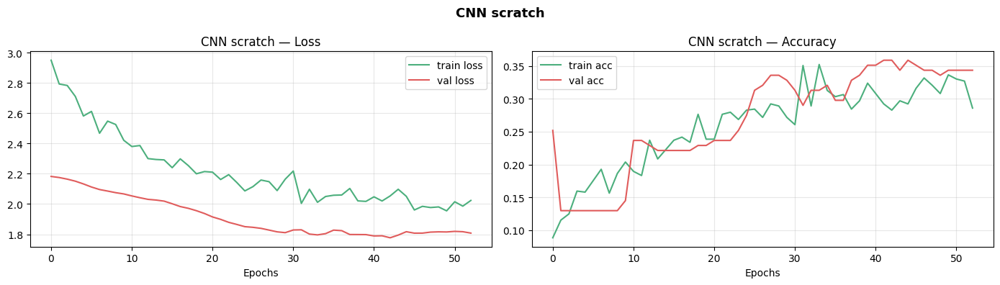

In [27]:
if history_cnn is not None:
    plot_history(history_cnn, "CNN scratch")
else:
    print("(History not available)")

#### 6.1.5 Evaluation and metrics



The CNN scratch model reaches a validation accuracy of 39% and a top-3 accuracy of 75%. The difference between these two values shows that the correct class is often among the three most probable predictions, but the model frequently fails to rank it as the first choice.

The F1 macro score is 0.2188, while the F1 weighted score is 0.3444. The low F1 macro confirms that the model performs poorly on several minority classes. This is important because macro F1 gives the same importance to all classes, regardless of how many images they contain.

The classification report shows that the model mainly learns the larger or visually easier classes, such as hamburger, french_fries and pizza, while it fails on several smaller classes such as caprese_salad, greek_salad, hot_dog and sashimi. Some of these classes have precision, recall and F1 equal to zero, meaning that the model never predicts them correctly.

The confusion matrix confirms this behavior. Many images are incorrectly classified as hamburger, showing that the model is biased toward one of the most represented classes. This is a typical problem when training a CNN from scratch on a small and imbalanced dataset.

Overall, the CNN scratch provides a useful baseline, but its results confirm that training a deep model from zero is not enough in this setting. This motivates the use of transfer learning in the next section.


  ✓ Predictions cnn_scratch loaded from cache

  METRICS — CNN SCRATCH
  Val Accuracy  : 0.3906  (39.06%)
  Val Top-3     : 0.7500  (75.00%)
  Val Loss      : 1.7772
  F1 Macro      : 0.2188
  F1 Weighted   : 0.3444
  Inferenza/img : 20.28 ms
  Parametri     : 116,217
✓ results['CNN scratch'] e results_checkpoint.pkl aggiornati
               precision    recall  f1-score   support

 caesar_salad       0.29      1.00      0.44         4
caprese_salad       0.00      0.00      0.00         2
 french_fries       0.39      0.39      0.39        23
  greek_salad       0.00      0.00      0.00         3
    hamburger       0.33      0.72      0.45        29
      hot_dog       0.00      0.00      0.00         5
        pizza       0.73      0.26      0.39        42
      sashimi       0.00      0.00      0.00         6
        sushi       0.40      0.24      0.30        17

     accuracy                           0.37       131
    macro avg       0.24      0.29      0.22       131
 weighte

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


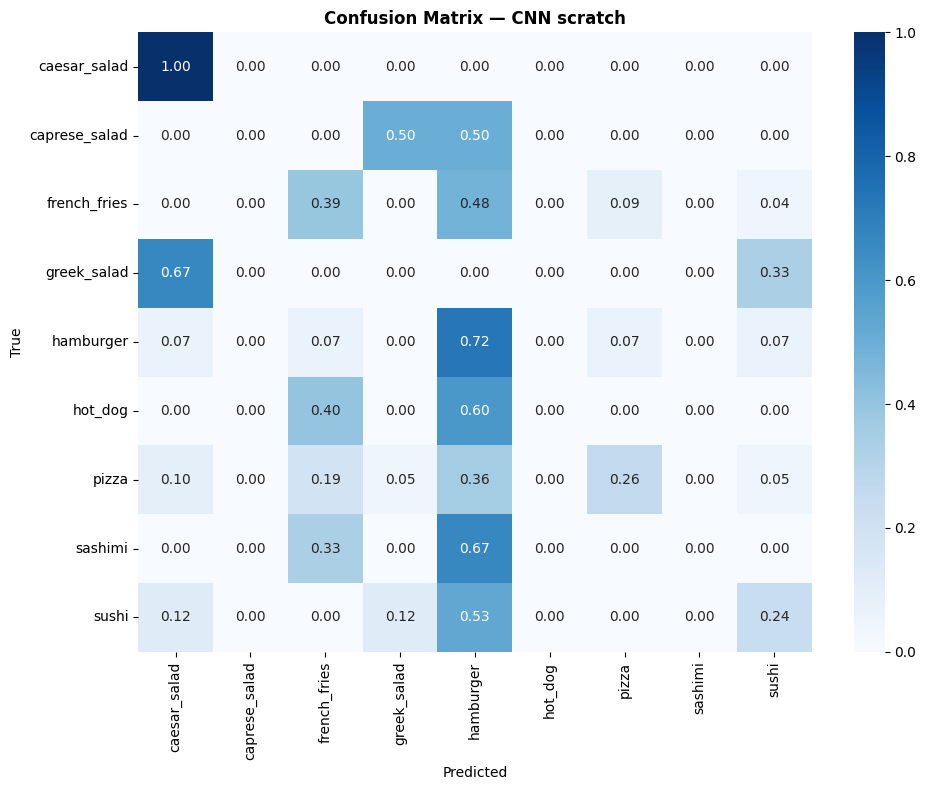

In [28]:
y_true_cnn, y_pred_cnn = compute_and_cache_metrics(
    cnn_model, ds_val_cnn, "cnn_scratch", "CNN scratch",
    cnn_train_time, history_cnn, None
)
print(classification_report(y_true_cnn, y_pred_cnn, target_names=class_names))
plot_confusion_matrix(y_true_cnn, y_pred_cnn, "CNN scratch")

### 6.2 Transfer Learning

Transfer learning consists of reusing a model already trained on a very large dataset as a starting point for a new task. In our case, the backbones were pre-trained on ImageNet, so they have already learned general visual features such as edges, textures and shapes. These features can then be adapted to our food classification problem.

This approach is particularly suitable here because the training set is very small, with only 626 images. As shown by the CNN trained from scratch, learning all features from zero with so little data leads to limited performance.

Transfer learning is applied in two phases:

* Feature Extractor: the pretrained backbone is frozen and only the classification head is trained.
* Fine-tuning: the last layers of the backbone are unfrozen and trained with a very low learning rate (`1e-5`), so that the model can adapt to the food domain without changing the pretrained weights too aggressively.

In this project, no learning rate warm-up was used during fine-tuning. This choice is reasonable because the fine-tuning learning rate is already very conservative, and the callbacks `EarlyStopping` and `ReduceLROnPlateau` help control unstable training. A warm-up strategy could still be useful in larger projects or with deeper backbones, but it was not necessary in this setting.

Three backbones with different characteristics were chosen:

1. EfficientNetV2S — a modern and efficient architecture.
2. ResNet50 — a classic reference model based on residual connections.
3. MobileNetV3Large — a lightweight model designed for devices with limited resources.


#### 6.2.1 EfficientNetV2S

6.2.1 EfficientNetV2S

EfficientNetV2S is a modern and efficient architecture for image classification, pre-trained on ImageNet. In this project, it is used as the first transfer learning model because it usually provides strong visual features while keeping a reasonable computational cost.

The backbone is loaded without the original classification top (`include_top=False`) and is initially frozen (`trainable=False`). A new classification head is added on top of it: Global Average Pooling, Dense(256), Batch Normalization, ReLU, Dropout and a final Softmax layer with 9 outputs.

In the Feature Extractor phase, only the classification head is trained. This means that the model does not update the ImageNet weights, but only learns how to use the extracted features for our food classes.

In [29]:
from tensorflow.keras.applications import EfficientNetV2S
base_effnet = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(IMG_SIZE,IMG_SIZE,3))
base_effnet.trainable = False
effnet_model = build_classifier_head(base_effnet, NUM_CLASSES)
effnet_model.compile(
    optimizer=keras.optimizers.Adam(LR_FE), loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
)
print(f"Layer backbone: {len(base_effnet.layers)}  |  Params (head only): {sum(p.numpy().size for p in effnet_model.trainable_weights):,}")

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Layer backbone: 513  |  Params (head only): 330,505


##### Step 1 — Feature Extractor

The `TRAIN_EFFNET` flag controls whether the model is trained or loaded from Drive. If the flag is set to `True`, the model is trained using the EfficientNetV2S preprocessing pipeline, callbacks and class weights. If it is set to `False`, the saved checkpoint is loaded directly.




⏭ Loading FE from the Drive...


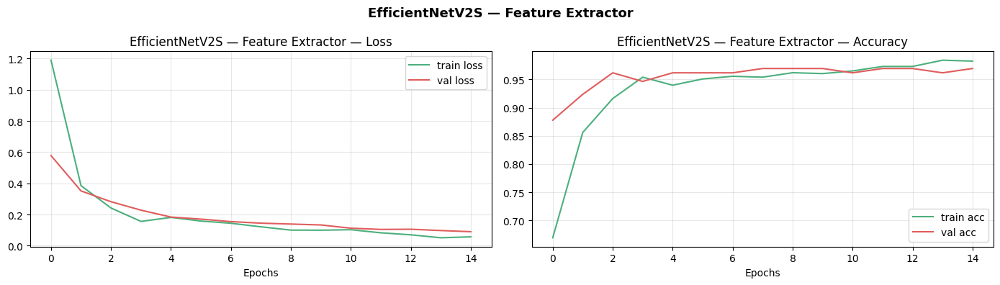

✓ EfficientNetV2S FE loaded


In [30]:
if TRAIN_EFFNET:
    print("▶ Step 1: Feature Extractor EfficientNetV2S...")
    t0 = time.time()
    history_effnet_fe = effnet_model.fit(
        ds_train_eff, validation_data=ds_val_eff,
        epochs=EPOCHS_FE, callbacks=get_callbacks("effnet_fe"), verbose=1,
        class_weight=class_weight_dict,
    )
    effnet_fe_time = time.time() - t0
    effnet_model.save(f"{SAVE_DIR}/checkpoint_effnet_fe_only.keras")
    save_history("effnet_fe", history_effnet_fe)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception):  _tt = {}
    _tt["effnet_fe"] = effnet_fe_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    print("✓ checkpoint_effnet_fe_only.keras + history + train_time salvati")
    plot_history(history_effnet_fe, "EfficientNetV2S — Feature Extractor")
else:
    print("⏭ Loading FE from the Drive...")
    effnet_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_effnet_fe_only.keras")
    history_effnet_fe = load_history("effnet_fe")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        effnet_fe_time = _tt.get("effnet_fe", 0)
    except (FileNotFoundError, Exception):  effnet_fe_time = 0
    if history_effnet_fe: plot_history(history_effnet_fe, "EfficientNetV2S — Feature Extractor")
    print("✓ EfficientNetV2S FE loaded")

##### Metrics after the feature extractor

The output shows that EfficientNetV2S performs very well already in the frozen phase. It reaches a validation accuracy of 97.66%, a top-3 accuracy of 99.22% and an F1 macro of 0.9461. These results are much higher than the CNN trained from scratch, confirming that the pretrained ImageNet features are very useful for this small dataset.

✓ FE predictions loaded from cache
  EfficientNetV2S FE → Acc: 97.66%  F1: 0.9461
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       0.60      1.00      0.75         3
    hamburger       1.00      0.97      0.98        29
      hot_dog       1.00      1.00      1.00         5
        pizza       1.00      0.98      0.99        42
      sashimi       0.75      1.00      0.86         6
        sushi       1.00      0.88      0.94        17

     accuracy                           0.97       131
    macro avg       0.93      0.98      0.95       131
 weighted avg       0.98      0.97      0.97       131



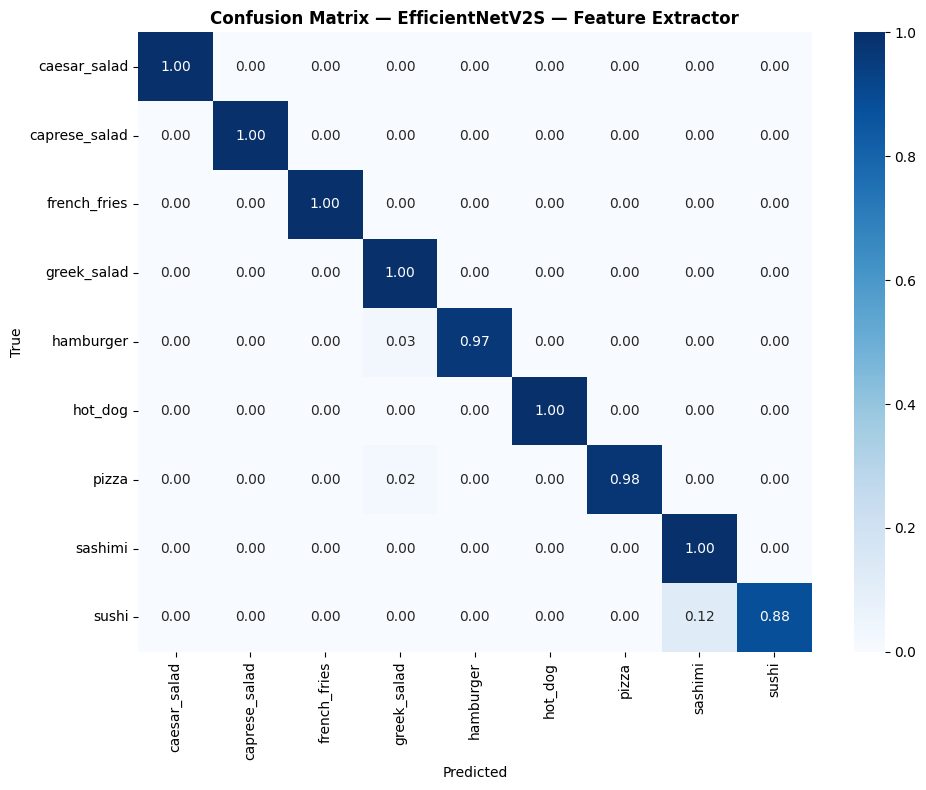

In [31]:
# FE Metrics — with cached predictions
y_true_eff_fe, y_pred_eff_fe = load_predictions("effnet_fe")
if y_true_eff_fe is None:
    print("Calculation of FE predictions...")
    y_true_eff_fe, y_pred_eff_fe = get_predictions(effnet_model, ds_val_eff)
    save_predictions("effnet_fe", y_true_eff_fe, y_pred_eff_fe)
else:
    print("✓ FE predictions loaded from cache")

_, val_acc_fe, val_top3_fe = effnet_model.evaluate(ds_val_eff, verbose=0)
f1_mac_fe = f1_score(y_true_eff_fe, y_pred_eff_fe, average="macro")
f1_wei_fe = f1_score(y_true_eff_fe, y_pred_eff_fe, average="weighted")
# Save FE metrics to disk (used for comparing FE and FT in 7.5)
with open(f"{SAVE_DIR}/fe_metrics.pkl", "wb") as _f:
    pickle.dump({"effnet": (val_acc_fe, val_top3_fe, f1_mac_fe)}, _f)
print(f"  EfficientNetV2S FE → Acc: {val_acc_fe*100:.2f}%  F1: {f1_mac_fe:.4f}")
print(classification_report(y_true_eff_fe, y_pred_eff_fe, target_names=class_names))
plot_confusion_matrix(y_true_eff_fe, y_pred_eff_fe, "EfficientNetV2S — Feature Extractor")

##### Step 2 — Fine-tuning (last 100 layer)

In this second phase, the last 100 layers out of 527 total (~19% of the
backbone) are unfrozen. The first layers — which have learned very general
features such as edges and textures — remain frozen. Only the later layers,
which encode more ImageNet-specific features, are adapted to our food domain.

The model is recompiled with a much lower learning rate (1e-5 instead of 1e-3).
This is essential: updating pretrained weights with a high learning rate would
destroy them, nullifying all the advantages of transfer learning. The training
runs for 30 epochs, more than double compared to the Feature Extractor phase,
since many more parameters are now being updated.

⏭ Loading FT from the Drive...


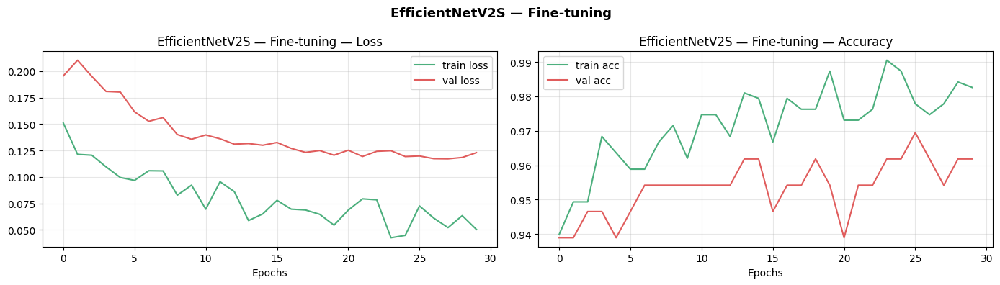

✓ EfficientNetV2S FT loaded


In [32]:
if TRAIN_EFFNET:
    print("▶ Step 2: Fine-tuning EfficientNetV2S (last 100 layers)...")
    base_effnet.trainable = True
    for layer in base_effnet.layers[:-100]: layer.trainable = False
    print(f"  Layer trainable: {sum(1 for l in base_effnet.layers if l.trainable)}/{len(base_effnet.layers)}")
    effnet_model.compile(
        optimizer=keras.optimizers.Adam(LR_FT), loss="categorical_crossentropy",
        metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
    )
    t0 = time.time()
    history_effnet_ft = effnet_model.fit(
        ds_train_eff, validation_data=ds_val_eff,
        epochs=EPOCHS_FT, callbacks=get_callbacks("effnet_ft"), verbose=1, class_weight=class_weight_dict,
    )
    effnet_ft_time = time.time() - t0
    effnet_model.save(f"{SAVE_DIR}/checkpoint_effnet.keras")
    save_history("effnet_ft", history_effnet_ft)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception): _tt = {}
    _tt["effnet_ft"] = effnet_ft_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    print("✓ checkpoint_effnet.keras + history + train_time saved")
    plot_history(history_effnet_ft, "EfficientNetV2S — Fine-tuning")
else:
    print("⏭ Loading FT from the Drive...")
    effnet_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_effnet.keras")
    history_effnet_ft = load_history("effnet_ft")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        effnet_ft_time = _tt.get("effnet_ft", 0)
    except (FileNotFoundError, Exception): effnet_ft_time = 0
    if history_effnet_ft: plot_history(history_effnet_ft, "EfficientNetV2S — Fine-tuning")
    print("✓ EfficientNetV2S FT loaded")

##### Metrics after Fine-Tuning + FE vs. FT Comparison

After fine-tuning, EfficientNetV2S still achieves very strong results on the validation set, with 96.88% accuracy, 100% top-3 accuracy and 0.9313 F1 macro.

The confusion matrix shows that most classes are classified almost perfectly. Classes such as caesar_salad, caprese_salad, french_fries, greek_salad, hot_dog and sashimi reach a normalized score of 1.00 on the diagonal, meaning that all validation samples of these classes are correctly classified. The main remaining errors are limited to a few confusions involving hamburger, pizza and sushi.

However, the comparison between Feature Extractor and Fine-tuning shows that fine-tuning does not really improve the model. Validation accuracy decreases slightly from 97.66% to 96.88%, and F1 macro decreases from 0.9461 to 0.9313. The only improvement is top-3 accuracy, which increases from 99.22% to 100%.

Overall, these results suggest that the frozen EfficientNetV2S backbone was already strong enough for this dataset. Fine-tuning adds complexity, but does not bring a clear benefit. For this reason, the Feature Extractor version remains preferable.

  ✓ Predictions effnet_ft loaded from cache

  METRICS — EFFICIENTNETV2S FT
  Val Accuracy  : 0.9688  (96.88%)
  Val Top-3     : 1.0000  (100.00%)
  Val Loss      : 0.0937
  F1 Macro      : 0.9313
  F1 Weighted   : 0.9567
  Training time : 832.3s (13.9 min)
  Inferenza/img : 6.19 ms
  Parametri     : 20,662,377
✓ results['EfficientNetV2S FT'] e results_checkpoint.pkl aggiornati
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       0.60      1.00      0.75         3
    hamburger       1.00      0.93      0.96        29
      hot_dog       0.83      1.00      0.91         5
        pizza       0.98      0.95      0.96        42
      sashimi       0.75      1.00      0.86         6
        sushi       1.00      0.88      0.94        17

     accuracy                           0.95       131
    macro av

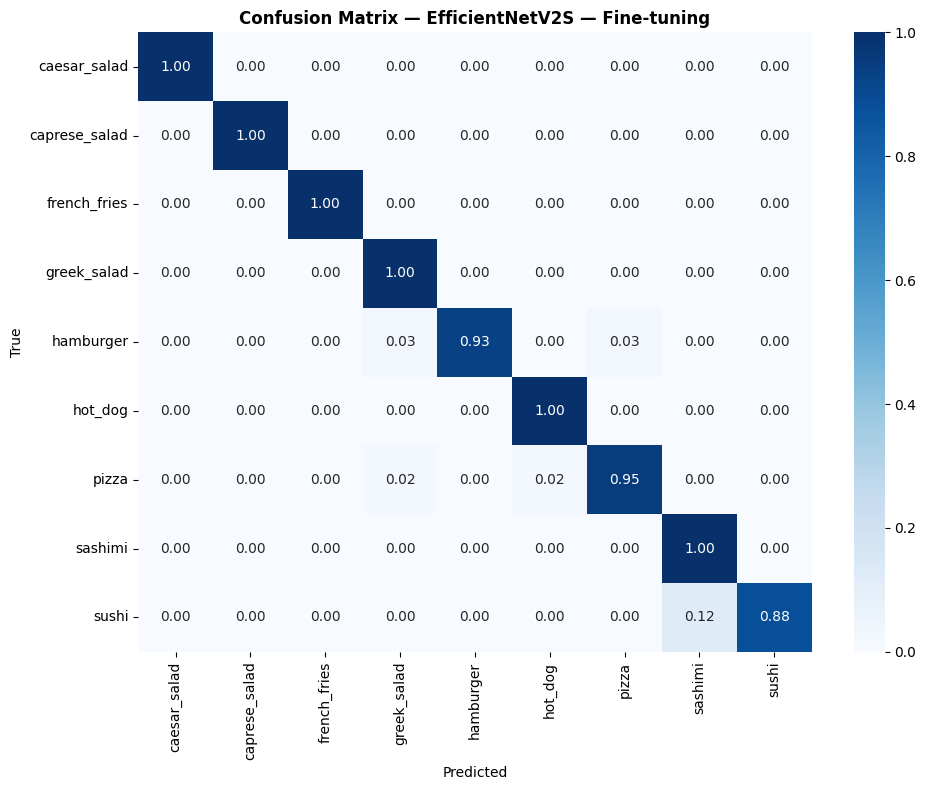


=== EFFECT OF FINE-TUNING — EfficientNetV2S ===
Metrics                 Feature Extractor     Fine-tuning      Delta
--------------------------------------------------------------------
Val Accuracy                       97.66%          96.88%     -0.78%
Val Top-3                          99.22%         100.00%     +0.78%
F1 Macro                           0.9461          0.9313    -0.0148


In [33]:
inf_ms_fe = evaluate_inference_time(effnet_model, ds_val_eff)
results["EfficientNetV2S FE"] = {
    "val_accuracy": val_acc_fe, "val_top3_accuracy": val_top3_fe, "val_loss": None,
    "f1_macro": f1_mac_fe, "f1_weighted": f1_score(y_true_eff_fe, y_pred_eff_fe, average="weighted"),
    "train_time_s": effnet_fe_time if effnet_fe_time else None,
    "inference_ms": inf_ms_fe, "params": None,
    "gpu_memory_used_mb": None, "gpu_memory_total_mb": None,
    "history_fe": None, "history_ft": None,
}

y_true_eff, y_pred_eff = compute_and_cache_metrics(
    effnet_model, ds_val_eff, "effnet_ft", "EfficientNetV2S FT",
    (effnet_fe_time or 0) + (effnet_ft_time or 0), history_effnet_fe, history_effnet_ft
)
print(classification_report(y_true_eff, y_pred_eff, target_names=class_names))
plot_confusion_matrix(y_true_eff, y_pred_eff, "EfficientNetV2S — Fine-tuning")

val_acc_ft  = results["EfficientNetV2S FT"]["val_accuracy"]
val_top3_ft = results["EfficientNetV2S FT"]["val_top3_accuracy"]
f1_mac_ft   = results["EfficientNetV2S FT"]["f1_macro"]
print("\n=== EFFECT OF FINE-TUNING — EfficientNetV2S ===")
print(f"{'Metrics':<20} {'Feature Extractor':>20} {'Fine-tuning':>15} {'Delta':>10}")
print("-"*68)
print(f"{'Val Accuracy':<20} {val_acc_fe*100:>19.2f}% {val_acc_ft*100:>14.2f}% {(val_acc_ft-val_acc_fe)*100:>+9.2f}%")
print(f"{'Val Top-3':<20} {val_top3_fe*100:>19.2f}% {val_top3_ft*100:>14.2f}% {(val_top3_ft-val_top3_fe)*100:>+9.2f}%")
print(f"{'F1 Macro':<20} {f1_mac_fe:>20.4f} {f1_mac_ft:>15.4f} {f1_mac_ft-f1_mac_fe:>+10.4f}")

#### 6.2.2 ResNet50

ResNet50 is a classic architecture developed by Microsoft Research, pre-trained
on ImageNet. Its main innovation is the introduction of residual connections:
shortcuts that allow the gradient to flow directly through the network, solving
the vanishing gradient problem that made training very deep networks extremely
difficult. The "50" refers to the number of layers with learnable weights, while
the total number of layers counted by Keras is 175, as it includes layers
without weights such as BatchNormalization, ReLU and pooling. Although older
than EfficientNetV2S, ResNet50 remains a reliable and widely used reference in
the computer vision community.

In [34]:
from tensorflow.keras.applications import ResNet50
base_resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE,IMG_SIZE,3))
base_resnet.trainable = False
resnet_model = build_classifier_head(base_resnet, NUM_CLASSES)
resnet_model.compile(
    optimizer=keras.optimizers.Adam(LR_FE), loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
)
print(f"Layer backbone: {len(base_resnet.layers)}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Layer backbone: 175


##### Step 1 — Feature Extractor

⏭ Loading FE ResNet50 from the Drive...


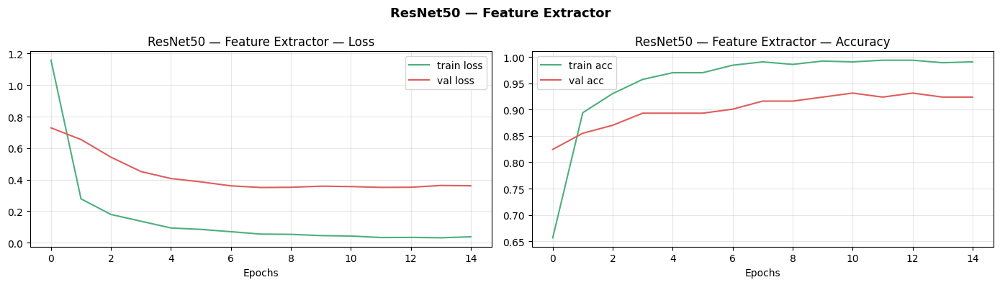

✓ ResNet50 FE loaded


In [35]:
if TRAIN_RESNET:
    print("▶ Step 1: Feature Extractor ResNet50...")
    t0 = time.time()
    history_resnet_fe = resnet_model.fit(
        ds_train_res, validation_data=ds_val_res,
        epochs=EPOCHS_FE, callbacks=get_callbacks("resnet_fe"), verbose=1, class_weight=class_weight_dict,
    )
    resnet_fe_time = time.time() - t0
    resnet_model.save(f"{SAVE_DIR}/checkpoint_resnet_fe_only.keras")
    save_history("resnet_fe", history_resnet_fe)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception): _tt = {}
    _tt["resnet_fe"] = resnet_fe_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    plot_history(history_resnet_fe, "ResNet50 — Feature Extractor")
    print("✓ checkpoint_resnet_fe_only.keras + train_time saved")
else:
    print("⏭ Loading FE ResNet50 from the Drive...")
    resnet_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_resnet_fe_only.keras")
    history_resnet_fe = load_history("resnet_fe")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        resnet_fe_time = _tt.get("resnet_fe", 0)
    except (FileNotFoundError, Exception): resnet_fe_time = 0
    if history_resnet_fe: plot_history(history_resnet_fe, "ResNet50 — Feature Extractor")
    print("✓ ResNet50 FE loaded")

##### Metrics after the Feature Extractor

Metrics after Feature Extractor

The training curves show that ResNet50 learns quickly during the Feature Extractor phase. The training loss decreases strongly, while the training accuracy reaches almost 100%. The validation accuracy also improves during the first epochs and then stabilizes around 92–93%.

However, the gap between training and validation performance suggests some overfitting. This is expected because the dataset is small, and only the classification head is being trained on top of a large pretrained backbone.

On the validation set, ResNet50 Feature Extractor reaches 92.97% accuracy and an F1 macro of 0.8750. This confirms that transfer learning works much better than the CNN trained from scratch, but ResNet50 is still weaker than EfficientNetV2S.

The classification report and the confusion matrix show that the model performs very well on several classes, especially caesar_salad, caprese_salad, french_fries and hot_dog, which are classified correctly in this validation split. Pizza, hamburger and sushi also obtain good results.

The main weakness is on the smallest or visually similar classes. Greek_salad has low recall, with only one third of its validation samples correctly classified, while sashimi is sometimes confused with hamburger or hot_dog. These errors are understandable because these classes have very few examples, and some food categories are visually close to each other.

Overall, ResNet50 Feature Extractor provides strong results and confirms the usefulness of transfer learning, but its performance is less balanced than EfficientNetV2S, especially on minority classes.


✓ Predictions ResNet50 FE from cache
  ResNet50 FE → Acc: 92.97%  F1: 0.8750
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       1.00      0.33      0.50         3
    hamburger       0.87      0.90      0.88        29
      hot_dog       0.83      1.00      0.91         5
        pizza       0.89      0.95      0.92        42
      sashimi       0.80      0.67      0.73         6
        sushi       1.00      0.88      0.94        17

     accuracy                           0.92       131
    macro avg       0.93      0.86      0.87       131
 weighted avg       0.92      0.92      0.91       131



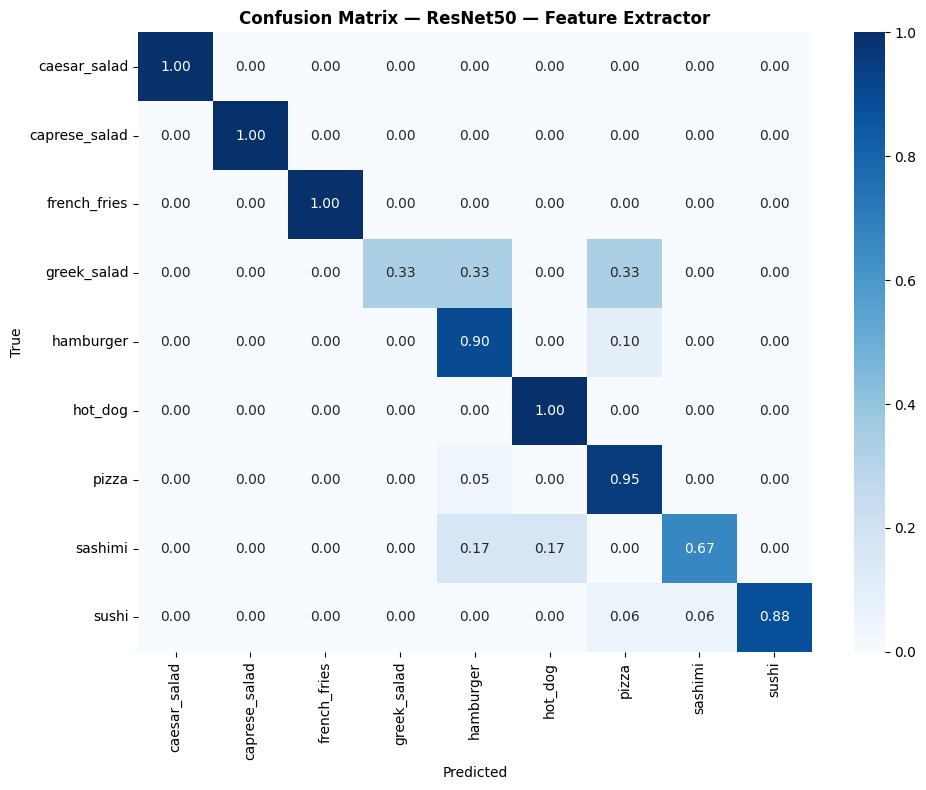

In [36]:
y_true_res_fe, y_pred_res_fe = load_predictions("resnet_fe")
if y_true_res_fe is None:
    y_true_res_fe, y_pred_res_fe = get_predictions(resnet_model, ds_val_res)
    save_predictions("resnet_fe", y_true_res_fe, y_pred_res_fe)
else:
    print("✓ Predictions ResNet50 FE from cache")
_, val_acc_res_fe, val_top3_res_fe = resnet_model.evaluate(ds_val_res, verbose=0)
f1_mac_res_fe = f1_score(y_true_res_fe, y_pred_res_fe, average="macro")
try:
    with open(f"{SAVE_DIR}/fe_metrics.pkl","rb") as _f: _fe = pickle.load(_f)
except (FileNotFoundError, Exception): _fe = {}
_fe["resnet"] = (val_acc_res_fe, val_top3_res_fe, f1_mac_res_fe)
with open(f"{SAVE_DIR}/fe_metrics.pkl","wb") as _f: pickle.dump(_fe, _f)
print(f"  ResNet50 FE → Acc: {val_acc_res_fe*100:.2f}%  F1: {f1_mac_res_fe:.4f}")
print(classification_report(y_true_res_fe, y_pred_res_fe, target_names=class_names))
plot_confusion_matrix(y_true_res_fe, y_pred_res_fe, "ResNet50 — Feature Extractor")

##### Step 2 — Fine-tuning (last 30 layer)

⏭ Loading FT ResNet50 from the Drive...


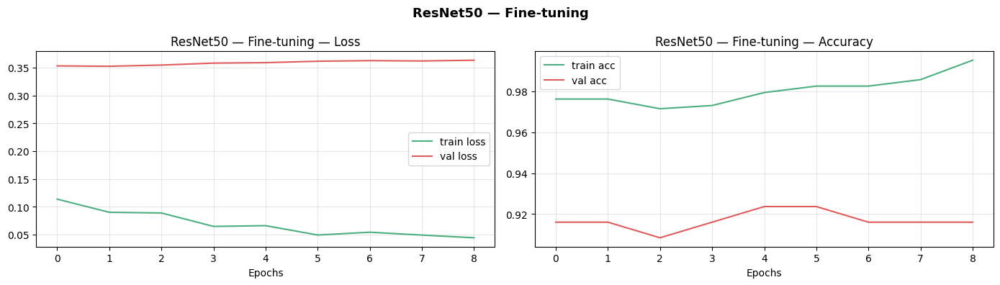

✓ ResNet50 FT loaded


In [37]:
if TRAIN_RESNET:
    print("▶ Step 2: Fine-tuning ResNet50 (last 30 layer)...")
    base_resnet.trainable = True
    for layer in base_resnet.layers[:-30]: layer.trainable = False
    resnet_model.compile(
        optimizer=keras.optimizers.Adam(LR_FT), loss="categorical_crossentropy",
        metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
    )
    t0 = time.time()
    history_resnet_ft = resnet_model.fit(
        ds_train_res, validation_data=ds_val_res,
        epochs=EPOCHS_FT, callbacks=get_callbacks("resnet_ft"), verbose=1, class_weight=class_weight_dict,
    )
    resnet_ft_time = time.time() - t0
    resnet_model.save(f"{SAVE_DIR}/checkpoint_resnet.keras")
    save_history("resnet_ft", history_resnet_ft)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception):  _tt = {}
    _tt["resnet_ft"] = resnet_ft_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    plot_history(history_resnet_ft, "ResNet50 — Fine-tuning")
    print("✓ checkpoint_resnet.keras + train_time saved")
else:
    print("⏭ Loading FT ResNet50 from the Drive...")
    resnet_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_resnet.keras")
    history_resnet_ft = load_history("resnet_ft")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        resnet_ft_time = _tt.get("resnet_ft", 0)
    except (FileNotFoundError, Exception):  resnet_ft_time = 0
    if history_resnet_ft: plot_history(history_resnet_ft, "ResNet50 — Fine-tuning")
    print("✓ ResNet50 FT loaded")

##### Metrics after Fine-Tuning + Comparison

The fine-tuning curves show that ResNet50 remains stable after unfreezing the last layers. The training loss continues to decrease, while the training accuracy becomes very high. The validation accuracy stays around 92%, with only small fluctuations across epochs.

This suggests that fine-tuning does not create instability, but it also does not produce a clear improvement in validation accuracy. The validation loss remains almost flat, while the gap between training and validation performance is still visible.

On the validation set, ResNet50 Fine-tuning reaches 92.19% accuracy, 96.88% top-3 accuracy and 0.9069 F1 macro. Compared to the Feature Extractor version, the accuracy remains almost the same, but the F1 macro improves. This means that fine-tuning helps the model become slightly more balanced across classes, even if the total number of correct predictions does not increase.

The classification report and confusion matrix confirm this behavior. Several classes are classified perfectly, such as caesar_salad, caprese_salad, french_fries and hot_dog. The model also performs well on hamburger, pizza and sushi.

The most important improvement is on greek_salad, whose recall increases compared to the Feature Extractor phase. However, sashimi remains difficult, with some confusion due to its visual similarity with other classes and the small number of validation examples.

Overall, ResNet50 Fine-tuning gives a small improvement in class balance, but not in overall accuracy. Therefore, fine-tuning is useful for ResNet50 only to a limited extent, and the model still remains below EfficientNetV2S in performance.

  ✓ Predictions resnet_ft loaded from cache

  METRICS — RESNET50 FT
  Val Accuracy  : 0.9219  (92.19%)
  Val Top-3     : 0.9688  (96.88%)
  Val Loss      : 0.3150
  F1 Macro      : 0.9069
  F1 Weighted   : 0.9153
  Training time : 404.0s (6.7 min)
  Inferenza/img : 7.54 ms
  Parametri     : 24,115,337
✓ results['ResNet50 FT'] e results_checkpoint.pkl aggiornati
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       1.00      0.67      0.80         3
    hamburger       0.87      0.90      0.88        29
      hot_dog       0.83      1.00      0.91         5
        pizza       0.89      0.93      0.91        42
      sashimi       0.80      0.67      0.73         6
        sushi       1.00      0.88      0.94        17

     accuracy                           0.92       131
    macro avg       0.93    

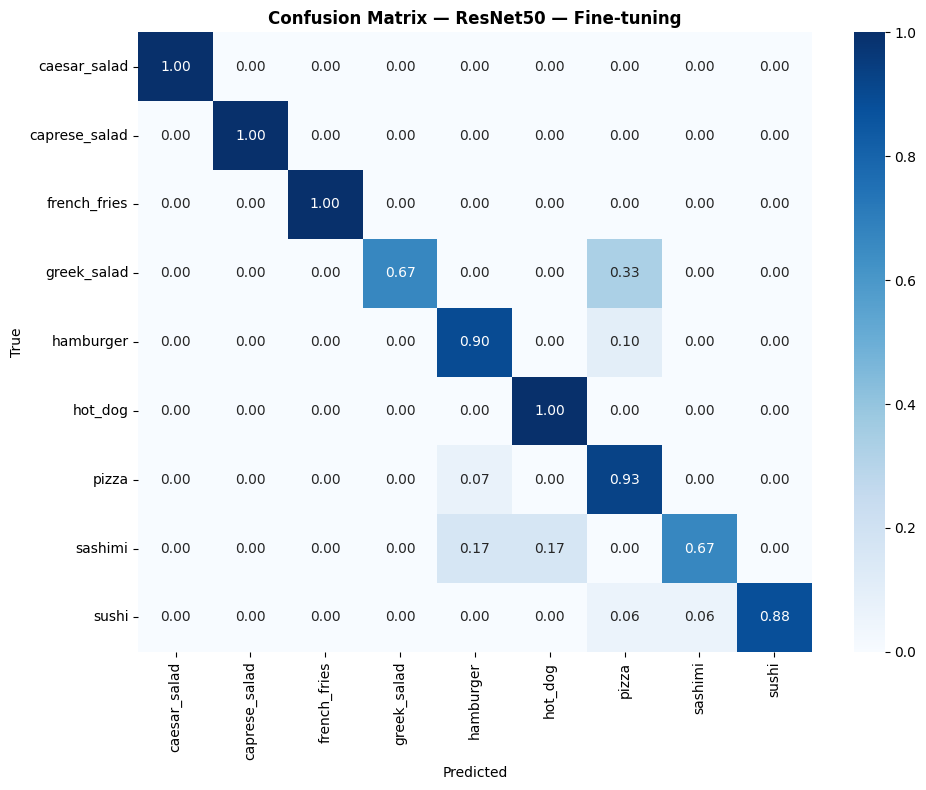


  ResNet50  FE: 92.97%  FT: 92.19%  Delta: -0.78%


In [38]:
inf_ms_res_fe = evaluate_inference_time(resnet_model, ds_val_res)
results["ResNet50 FE"] = {
    "val_accuracy": val_acc_res_fe, "val_top3_accuracy": val_top3_res_fe, "val_loss": None,
    "f1_macro": f1_mac_res_fe, "f1_weighted": f1_score(y_true_res_fe, y_pred_res_fe, average="weighted"),
    "train_time_s": resnet_fe_time if resnet_fe_time else None,
    "inference_ms": inf_ms_res_fe, "params": None,
    "gpu_memory_used_mb": None, "gpu_memory_total_mb": None,
    "history_fe": None, "history_ft": None,
}

y_true_res, y_pred_res = compute_and_cache_metrics(
    resnet_model, ds_val_res, "resnet_ft", "ResNet50 FT",
    (resnet_fe_time or 0) + (resnet_ft_time or 0), history_resnet_fe, history_resnet_ft
)
print(classification_report(y_true_res, y_pred_res, target_names=class_names))
plot_confusion_matrix(y_true_res, y_pred_res, "ResNet50 — Fine-tuning")
val_acc_res_ft = results["ResNet50 FT"]["val_accuracy"]
print(f"\n  ResNet50  FE: {val_acc_res_fe*100:.2f}%  FT: {val_acc_res_ft*100:.2f}%  Delta: {(val_acc_res_ft-val_acc_res_fe)*100:>+.2f}%")

#### 6.2.3 MobileNetV3Large

In [39]:
from tensorflow.keras.applications import MobileNetV3Large
base_mobile = MobileNetV3Large(weights="imagenet", include_top=False, input_shape=(IMG_SIZE,IMG_SIZE,3))
base_mobile.trainable = False
mobile_model = build_classifier_head(base_mobile, NUM_CLASSES)
mobile_model.compile(
    optimizer=keras.optimizers.Adam(LR_FE), loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
)
print(f"Layer backbone: {len(base_mobile.layers)}")

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Layer backbone: 187


##### Step 1 — Feature Extractor

⏭ Loading FE MobileNetV3Large from the Drive...


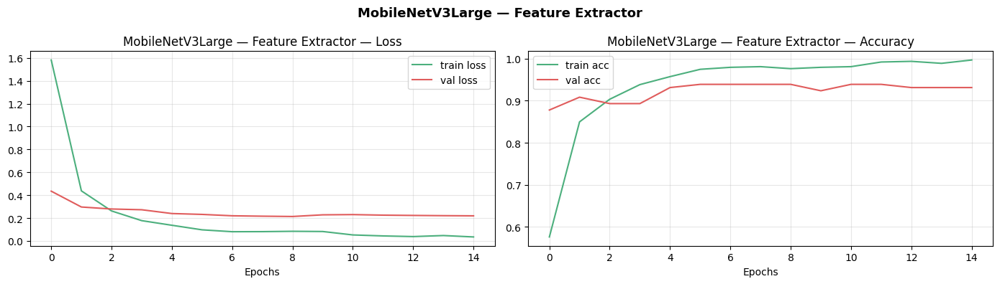

✓ MobileNetV3Large FE loaded


In [40]:
if TRAIN_MOBILE:
    print("▶ Step 1: Feature Extractor MobileNetV3Large...")
    t0 = time.time()
    history_mobile_fe = mobile_model.fit(
        ds_train_mob, validation_data=ds_val_mob,
        epochs=EPOCHS_FE, callbacks=get_callbacks("mobile_fe"), verbose=1, class_weight=class_weight_dict,
    )
    mobile_fe_time = time.time() - t0
    mobile_model.save(f"{SAVE_DIR}/checkpoint_mobile_fe_only.keras")
    save_history("mobile_fe", history_mobile_fe)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception): _tt = {}
    _tt["mobile_fe"] = mobile_fe_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    plot_history(history_mobile_fe, "MobileNetV3Large — Feature Extractor")
    print("✓ checkpoint_mobile_fe_only.keras + train_time saved")
else:
    print("⏭ Loading FE MobileNetV3Large from the Drive...")
    mobile_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_mobile_fe_only.keras")
    history_mobile_fe = load_history("mobile_fe")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        mobile_fe_time = _tt.get("mobile_fe", 0)
    except (FileNotFoundError, Exception): mobile_fe_time = 0
    if history_mobile_fe: plot_history(history_mobile_fe, "MobileNetV3Large — Feature Extractor")
    print("✓ MobileNetV3Large FE loaded")

##### Metrics after the Feature Extractor

The MobileNetV3Large Feature Extractor shows strong and stable performance. From the training curves, the model learns very quickly: the training loss decreases sharply in the first epochs, while the validation loss also decreases and then stabilizes. The validation accuracy remains high, around 94–95%, with only small variations after the first epochs.

On the validation set, MobileNetV3Large FE reaches 94.53% accuracy and an F1 macro of 0.9199. This is a strong result, especially considering that MobileNetV3Large is a lightweight architecture designed to reduce computational cost.

The classification report and confusion matrix show that most classes are classified correctly. Classes such as caprese_salad, french_fries and hot_dog reach perfect recall, while hamburger, pizza and sushi also obtain good results.

The main remaining errors involve the smaller or more visually similar classes. For example, greek_salad is sometimes confused with sushi, and sashimi has a few errors, probably due to its similarity with other food categories and the limited number of examples.

Overall, MobileNetV3Large Feature Extractor provides a good balance between accuracy and efficiency. It performs slightly below EfficientNetV2S, but it is still much stronger than the CNN trained from scratch.


✓ Predictions MobileNetV3Large FE from the cache
  MobileNetV3Large FE → Acc: 94.53%  F1: 0.9199
               precision    recall  f1-score   support

 caesar_salad       0.80      1.00      0.89         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       1.00      0.67      0.80         3
    hamburger       0.96      0.93      0.95        29
      hot_dog       1.00      1.00      1.00         5
        pizza       0.95      0.95      0.95        42
      sashimi       0.83      0.83      0.83         6
        sushi       0.83      0.88      0.86        17

     accuracy                           0.94       131
    macro avg       0.93      0.92      0.92       131
 weighted avg       0.94      0.94      0.94       131



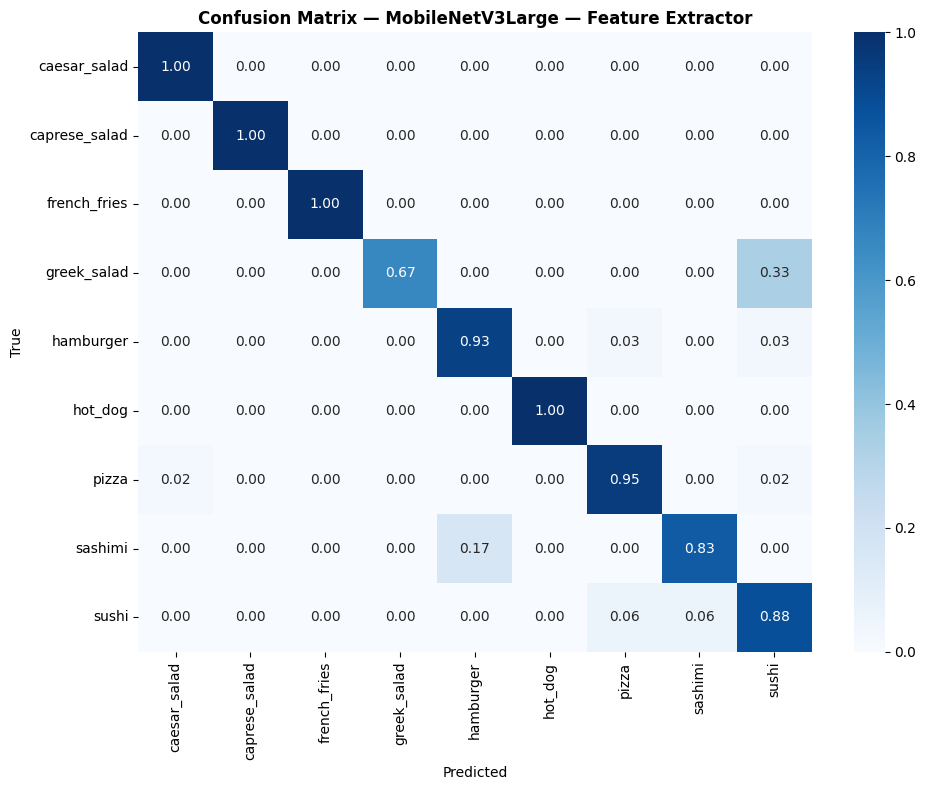

In [41]:
y_true_mob_fe, y_pred_mob_fe = load_predictions("mobile_fe")
if y_true_mob_fe is None:
    y_true_mob_fe, y_pred_mob_fe = get_predictions(mobile_model, ds_val_mob)
    save_predictions("mobile_fe", y_true_mob_fe, y_pred_mob_fe)
else:
    print("✓ Predictions MobileNetV3Large FE from the cache")
_, val_acc_mob_fe, val_top3_mob_fe = mobile_model.evaluate(ds_val_mob, verbose=0)
f1_mac_mob_fe = f1_score(y_true_mob_fe, y_pred_mob_fe, average="macro")
try:
    with open(f"{SAVE_DIR}/fe_metrics.pkl","rb") as _f: _fe = pickle.load(_f)
except (FileNotFoundError, Exception): _fe = {}
_fe["mobile"] = (val_acc_mob_fe, val_top3_mob_fe, f1_mac_mob_fe)
with open(f"{SAVE_DIR}/fe_metrics.pkl","wb") as _f: pickle.dump(_fe, _f)
print(f"  MobileNetV3Large FE → Acc: {val_acc_mob_fe*100:.2f}%  F1: {f1_mac_mob_fe:.4f}")
print(classification_report(y_true_mob_fe, y_pred_mob_fe, target_names=class_names))
plot_confusion_matrix(y_true_mob_fe, y_pred_mob_fe, "MobileNetV3Large — Feature Extractor")

##### Step 2 — Fine-tuning (last 50 layer)

⏭ Loading FT MobileNetV3Large from the Drive...


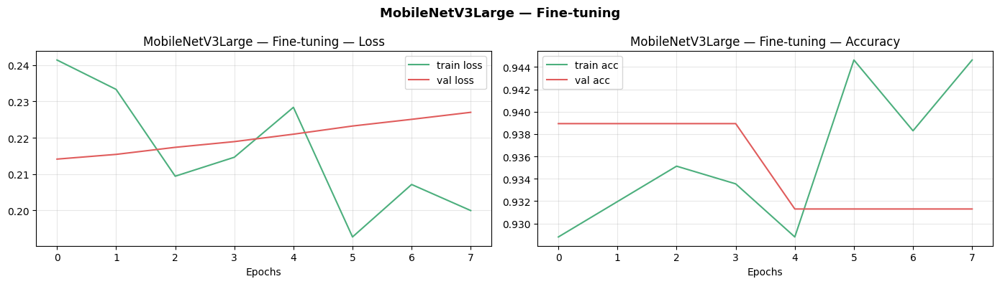

✓ MobileNetV3Large FT loaded


In [42]:
if TRAIN_MOBILE:
    print("▶ Step 2: Fine-tuning MobileNetV3Large (last 50 layer)...")
    base_mobile.trainable = True
    for layer in base_mobile.layers[:-50]: layer.trainable = False
    mobile_model.compile(
        optimizer=keras.optimizers.Adam(LR_FT), loss="categorical_crossentropy",
        metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")],
    )
    t0 = time.time()
    history_mobile_ft = mobile_model.fit(
        ds_train_mob, validation_data=ds_val_mob,
        epochs=EPOCHS_FT, callbacks=get_callbacks("mobile_ft"), verbose=1, class_weight=class_weight_dict,
    )
    mobile_ft_time = time.time() - t0
    mobile_model.save(f"{SAVE_DIR}/checkpoint_mobile.keras")
    save_history("mobile_ft", history_mobile_ft)
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
    except (FileNotFoundError, Exception): _tt = {}
    _tt["mobile_ft"] = mobile_ft_time
    with open(f"{SAVE_DIR}/train_times.pkl","wb") as _f: pickle.dump(_tt, _f)
    plot_history(history_mobile_ft, "MobileNetV3Large — Fine-tuning")
    print("✓ checkpoint_mobile.keras + train_time saved")
else:
    print("⏭ Loading FT MobileNetV3Large from the Drive...")
    mobile_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_mobile.keras")
    history_mobile_ft = load_history("mobile_ft")
    try:
        with open(f"{SAVE_DIR}/train_times.pkl","rb") as _f: _tt = pickle.load(_f)
        mobile_ft_time = _tt.get("mobile_ft", 0)
    except (FileNotFoundError, Exception): mobile_ft_time = 0
    if history_mobile_ft: plot_history(history_mobile_ft, "MobileNetV3Large — Fine-tuning")
    print("✓ MobileNetV3Large FT loaded")

##### Metrics after Fine-Tuning + Comparison

After fine-tuning, MobileNetV3Large reaches exactly the same validation accuracy as the Feature Extractor version: 94.53%. The F1 macro also remains unchanged at 0.9199, and the confusion matrix is practically identical.

The training curves show that fine-tuning does not bring a clear improvement. The training accuracy fluctuates slightly, while the validation accuracy stays almost flat and does not increase compared to the frozen model. The validation loss also remains stable, with only small changes.

This means that unfreezing the last layers of MobileNetV3Large does not add useful information in this setting. The pretrained frozen backbone was already able to extract good visual features for the food classes.

The comparison confirms this result: MobileNetV3Large FE reaches 94.53%, MobileNetV3Large FT also reaches 94.53%, with a delta of +0.00%. Therefore, fine-tuning does not improve the model and only adds extra training time and complexity.

For this reason, the Feature Extractor version is preferable for MobileNetV3Large, since it gives the same performance with a simpler and more efficient training process.


  ✓ Predictions mobile_ft loaded from cache

  METRICS — MOBILENETV3LARGE FT
  Val Accuracy  : 0.9453  (94.53%)
  Val Top-3     : 0.9844  (98.44%)
  Val Loss      : 0.1807
  F1 Macro      : 0.9199
  F1 Weighted   : 0.9389
  Training time : 316.7s (5.3 min)
  Inferenza/img : 4.92 ms
  Parametri     : 3,245,449
✓ results['MobileNetV3Large FT'] e results_checkpoint.pkl aggiornati
               precision    recall  f1-score   support

 caesar_salad       0.80      1.00      0.89         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       1.00      0.67      0.80         3
    hamburger       0.96      0.93      0.95        29
      hot_dog       1.00      1.00      1.00         5
        pizza       0.95      0.95      0.95        42
      sashimi       0.83      0.83      0.83         6
        sushi       0.83      0.88      0.86        17

     accuracy                           0.94       131
    macro avg

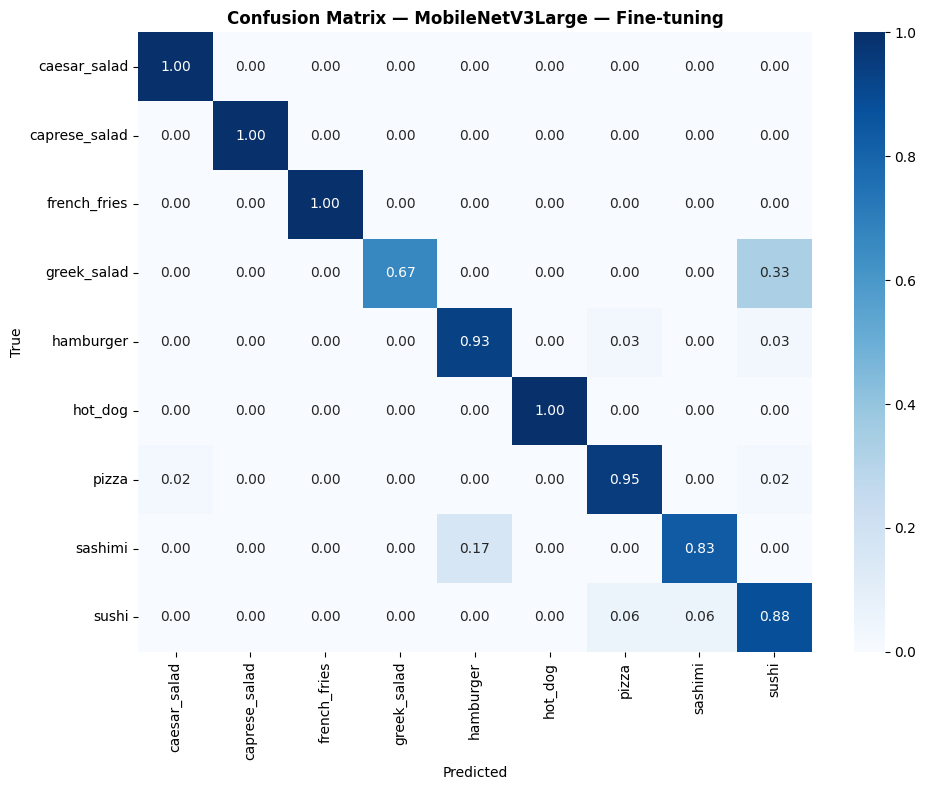


  MobileNetV3Large  FE: 94.53%  FT: 94.53%  Delta: +0.00%


In [43]:
inf_ms_mob_fe = evaluate_inference_time(mobile_model, ds_val_mob)
results["MobileNetV3Large FE"] = {
    "val_accuracy": val_acc_mob_fe, "val_top3_accuracy": val_top3_mob_fe, "val_loss": None,
    "f1_macro": f1_mac_mob_fe, "f1_weighted": f1_score(y_true_mob_fe, y_pred_mob_fe, average="weighted"),
    "train_time_s": mobile_fe_time if mobile_fe_time else None,
    "inference_ms": inf_ms_mob_fe, "params": None,
    "gpu_memory_used_mb": None, "gpu_memory_total_mb": None,
    "history_fe": None, "history_ft": None,
}

y_true_mob, y_pred_mob = compute_and_cache_metrics(
    mobile_model, ds_val_mob, "mobile_ft", "MobileNetV3Large FT",
    (mobile_fe_time or 0) + (mobile_ft_time or 0), history_mobile_fe, history_mobile_ft
)
print(classification_report(y_true_mob, y_pred_mob, target_names=class_names))
plot_confusion_matrix(y_true_mob, y_pred_mob, "MobileNetV3Large — Fine-tuning")
val_acc_mob_ft = results["MobileNetV3Large FT"]["val_accuracy"]
print(f"\n  MobileNetV3Large  FE: {val_acc_mob_fe*100:.2f}%  FT: {val_acc_mob_ft*100:.2f}%  Delta: {(val_acc_mob_ft-val_acc_mob_fe)*100:>+.2f}%")

### 6.3 Deep Feature Extraction + Classical Machine Learning Classifiers

The EfficientNetV2S Feature Extractor checkpoint is loaded and a new model is
created that stops at the GAP layer, producing a 1280-dimensional feature vector
for each image instead of a class probability.

Features are extracted for train, val and test using the extract_features
function, which iterates over all batches and collects the vectors produced by
the feature extractor. Note that the training set is extracted without
augmentation (ds_train_eff_noaug): unlike neural networks, classical classifiers
do not benefit from augmentation.

The extracted features are then normalized using StandardScaler, which is
essential for classifiers such as SVM that are sensitive to the scale of the
input values. Importantly, the scaler is fitted exclusively on the training set
and then applied to val and test — this avoids data leakage.

#### 6.3.1 Feature extraction (with the TRAIN_FEATURES flag)

In [44]:
# 6.3.1 — Deep Feature Extraction with EfficientNetV2S FE
effnet_fe_model = keras.models.load_model(f"{SAVE_DIR}/checkpoint_effnet_fe_only.keras")
feature_extractor = keras.Model(
    inputs=effnet_fe_model.input,
    outputs=effnet_fe_model.get_layer("gap").output,
    name="feature_extractor"
)
feature_extractor.trainable = False
print(f"✓ Feature extractor — output shape: {feature_extractor.output_shape}")

def extract_features(dataset):
    all_features, all_labels = [], []
    for batch_imgs, batch_lbls in dataset:
        feats = feature_extractor(batch_imgs, training=False).numpy()
        lbls  = np.argmax(batch_lbls.numpy(), axis=1)
        all_features.append(feats)
        all_labels.append(lbls)
    return np.concatenate(all_features, axis=0), np.concatenate(all_labels, axis=0)

import pickle as _pkl
from sklearn.preprocessing import StandardScaler

if TRAIN_FEATURES:
    print("Feature extraction for the training set (no augmentation)...")
    X_train_feat, y_train_feat = extract_features(ds_train_eff_noaug)
    print("Feature extraction for the validation set...")
    X_val_feat,   y_val_feat   = extract_features(ds_val_eff)
    print("Featue extraction for the test set...")
    X_test_feat,  y_test_feat  = extract_features(ds_test_eff)

    np.save(f"{SAVE_DIR}/X_train_feat.npy", X_train_feat)
    np.save(f"{SAVE_DIR}/y_train_feat.npy", y_train_feat)
    np.save(f"{SAVE_DIR}/X_val_feat.npy",   X_val_feat)
    np.save(f"{SAVE_DIR}/y_val_feat.npy",   y_val_feat)
    np.save(f"{SAVE_DIR}/X_test_feat.npy",  X_test_feat)
    np.save(f"{SAVE_DIR}/y_test_feat.npy",  y_test_feat)
    print(f"✓ Features salvate — train: {X_train_feat.shape}, val: {X_val_feat.shape}, test: {X_test_feat.shape}")

    # Fit scaler e save on the Drive
    scaler = StandardScaler()
    X_train_feat_sc = scaler.fit_transform(X_train_feat)
    X_val_feat_sc   = scaler.transform(X_val_feat)
    X_test_feat_sc  = scaler.transform(X_test_feat) if X_test_feat is not None else None
    with open(f"{SAVE_DIR}/scaler.pkl", "wb") as _sf: _pkl.dump(scaler, _sf)
    print("✓ StandardScaler configured and saved to Drive")

else:
    print("⏭ TRAIN_FEATURES = False — uploading features from Drive...")
    X_train_feat = np.load(f"{SAVE_DIR}/X_train_feat.npy")
    y_train_feat = np.load(f"{SAVE_DIR}/y_train_feat.npy")
    X_val_feat   = np.load(f"{SAVE_DIR}/X_val_feat.npy")
    y_val_feat   = np.load(f"{SAVE_DIR}/y_val_feat.npy")
    X_test_feat  = np.load(f"{SAVE_DIR}/X_test_feat.npy") if os.path.exists(f"{SAVE_DIR}/X_test_feat.npy") else None
    y_test_feat  = np.load(f"{SAVE_DIR}/y_test_feat.npy") if os.path.exists(f"{SAVE_DIR}/y_test_feat.npy") else None
    print(f"✓ Features loaded — train: {X_train_feat.shape}, val: {X_val_feat.shape}")


    try:
        with open(f"{SAVE_DIR}/scaler.pkl", "rb") as _sf: scaler = _pkl.load(_sf)
        X_train_feat_sc = scaler.transform(X_train_feat)
        X_val_feat_sc   = scaler.transform(X_val_feat)
        X_test_feat_sc  = scaler.transform(X_test_feat) if X_test_feat is not None else None
        print("✓ StandardScaler loaded from the Drive")
    except FileNotFoundError:
        print("⚠ scaler.pkl not found — rifitting (val/test may differ from the original training)")
        scaler = StandardScaler()
        X_train_feat_sc = scaler.fit_transform(X_train_feat)
        X_val_feat_sc   = scaler.transform(X_val_feat)
        X_test_feat_sc  = scaler.transform(X_test_feat) if X_test_feat is not None else None

✓ Feature extractor — output shape: (None, 1280)
⏭ TRAIN_FEATURES = False — uploading features from Drive...
✓ Features loaded — train: (632, 1280), val: (131, 1280)
✓ StandardScaler loaded from the Drive


#### 6.3.2 PCA

In [45]:
# Colors by class (alphabetical order = order of class_names)
# caesar_salad, caprese_salad, french_fries, greek_salad,
# hamburger, hot_dog, pizza, sashimi, sushi
CLASS_COLORS = {
    "caesar_salad":  "#a5d6a7",   # light green
    "caprese_salad": "#4caf50",   # medium green
    "greek_salad":   "#1b5e20",   # dark green
    "french_fries":  "#fdd835",   # yellow
    "hamburger":     "#6d4c41",   # brown
    "hot_dog":       "#bf6a3f",   # brown sausage
    "pizza":         "#c62828",   # pizza red
    "sashimi":       "#fa8072",   # salmon
    "sushi":         "#5c6bc0",   # indigo
}

After extracting the deep features from EfficientNetV2S, PCA is applied to better understand the structure of the feature space. Each image is represented by a 1280-dimensional vector, so PCA helps us check whether all these dimensions are really needed or if the information can be compressed into fewer components.

The cumulative explained variance plot shows that 241 components are needed to explain 95% of the total variance. This means that the extracted features contain rich information, but also that many dimensions are partially redundant: the representation can be reduced from 1280 to 241 components while keeping most of the variance.

This result is useful because it confirms that the deep features are not random or unstructured. A large part of the information is concentrated in a smaller subspace, which makes dimensionality reduction meaningful.

The second plot shows the first two PCA components. Some classes appear quite well separated, especially pizza on the right side and french_fries on the left side. Other classes, such as hamburger, sushi, sashimi and the salad categories, are more mixed in the central area. This suggests that the feature extractor captures useful visual differences, but some classes remain harder to separate in only two linear dimensions.

For this reason, PCA is useful as a first linear analysis, but it is not enough to fully visualize the feature space. In the next step, t-SNE is applied because it is a non-linear method and can better show local clusters and relationships between similar images.


Components accounting for 95% of the variance: 241 / 1280


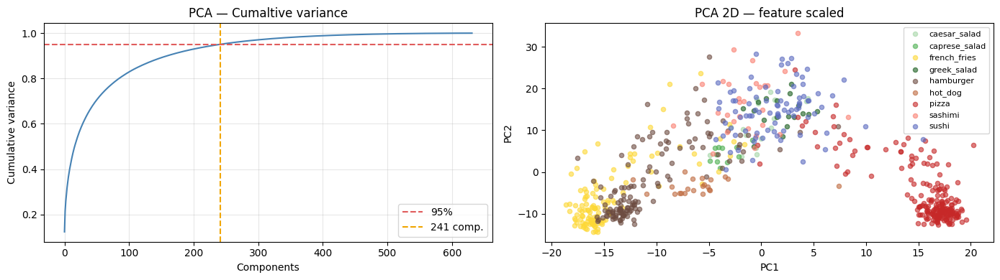

In [46]:
from sklearn.decomposition import PCA

# PCA on SCALED features — correct: PCA is scale-sensitive,
# working with uncentered/unscaled data distorts the principal components.
# Consistent with SVM/RF/XGBoost, which take X_train_feat_sc as input.
pca_full = PCA().fit(X_train_feat_sc)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cumvar >= 0.95) + 1
print(f"Components accounting for 95% of the variance: {n_components_95} / {X_train_feat_sc.shape[1]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(cumvar, color="steelblue")
axes[0].axhline(0.95, color="#e05c5c", linestyle="--", label="95%")
axes[0].axvline(n_components_95, color="#f0a500", linestyle="--", label=f"{n_components_95} comp.")
axes[0].set_xlabel("Components"); axes[0].set_ylabel("Cumulative variance")
axes[0].set_title("PCA — Cumaltive variance"); axes[0].legend(); axes[0].grid(alpha=0.3)

pca_2d = PCA(n_components=2).fit_transform(X_train_feat_sc)
for idx, name in enumerate(class_names):
    mask = y_train_feat == idx
    axes[1].scatter(pca_2d[mask, 0], pca_2d[mask, 1],
                    label=name, alpha=0.6, s=20,
                    color=CLASS_COLORS[name])
axes[1].set_title("PCA 2D — feature scaled")
axes[1].legend(fontsize=8)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout(); plt.show()

#### 6.3.3 t-SNE — visualizzazione 2D

After PCA, t-SNE is used to obtain a non-linear 2D visualization of the deep features extracted by EfficientNetV2S. While PCA is useful for understanding the variance structure, t-SNE is better at showing local relationships between images and possible class clusters.

Before applying t-SNE, the feature space is first reduced to 50 components with PCA. This makes the computation lighter while keeping most of the relevant information.

The t-SNE plot shows a clearer separation between several classes compared to the PCA 2D plot. For example, french_fries forms a very compact cluster on the left, pizza is mostly grouped on the right, and hamburger appears in a separated area at the top. This suggests that the features extracted by EfficientNetV2S already contain useful information for distinguishing these classes.

Some overlap is still visible in the central area, especially between visually similar or smaller classes such as sushi, sashimi and the salad categories. This is expected because these classes have fewer examples and can share similar visual patterns.

Overall, the t-SNE visualization confirms that the deep features are meaningful and reasonably well organized by class. This result motivated the use of classical classifiers on top of these features, such as SVM, Random Forest and XGBoost. Since several classes already form clear clusters, we can expect these classifiers to achieve good results

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


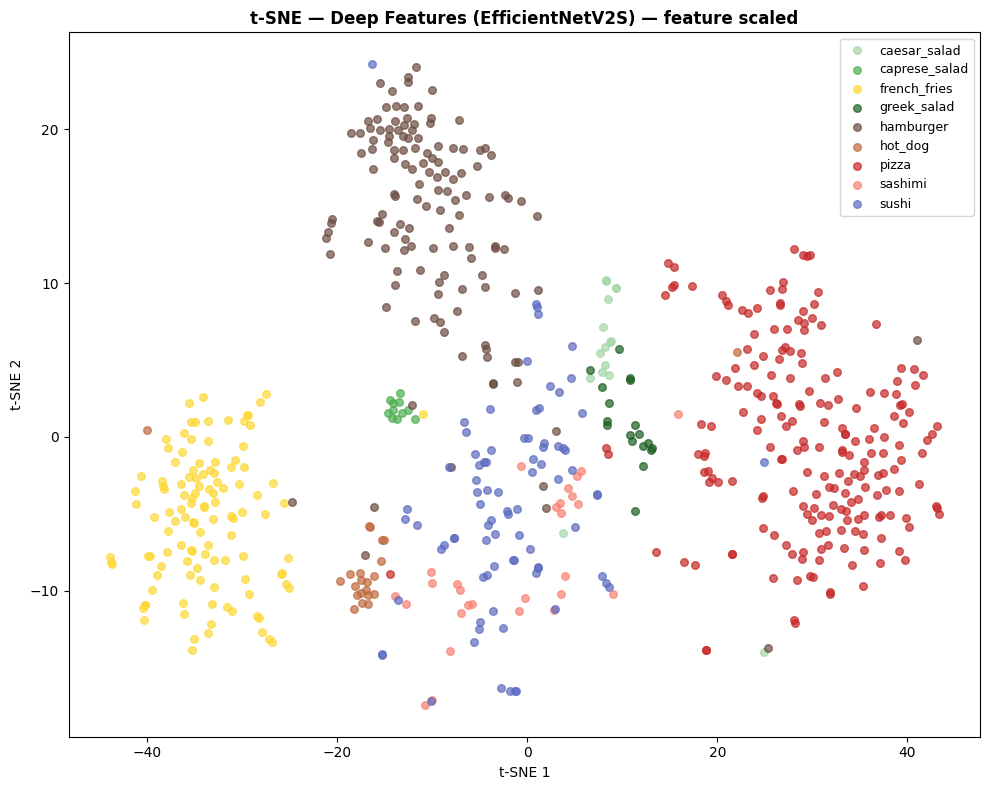

In [47]:
from sklearn.manifold import TSNE

pca_50 = PCA(n_components=50).fit_transform(X_train_feat_sc)
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, n_iter=1000)
X_tsne = tsne.fit_transform(pca_50)

fig, ax = plt.subplots(figsize=(10, 8))
for idx, name in enumerate(class_names):
    mask = y_train_feat == idx
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               label=name, alpha=0.7, s=30,
               color=CLASS_COLORS[name])
ax.set_title("t-SNE — Deep Features (EfficientNetV2S) — feature scaled", fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

#### 6.3.4 SVM + Grid Search

The first classical classifier applied to the deep features is the Support
Vector Machine (SVM). SVM seeks the hyperplane that separates the classes in
the feature space with the maximum margin. The RBF (Radial Basis Function)
kernel is used, which handles classes that are not linearly separable by
implicitly mapping the data into a higher-dimensional space.

A GridSearchCV is performed over all combinations of two key hyperparameters:
  - C (0.1, 1, 10, 100): controls the trade-off between maximizing the margin
    and minimizing classification errors.
  - gamma (scale, auto, 0.001, 0.01): controls how far the influence of each
    training point reaches.
For each combination, a 5-fold cross validation is performed on the training
set, and the combination with the highest mean accuracy is selected.

The best model is then evaluated on the validation set, and results (accuracy,
F1 macro, F1 weighted) are saved to the results dictionary and to Drive. A
classification report and confusion matrix are also printed.

⏭ Loading SVM from the Drive...
✓ SVM loaded
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       0.50      0.33      0.40         3
    hamburger       1.00      0.93      0.96        29
      hot_dog       1.00      1.00      1.00         5
        pizza       1.00      0.98      0.99        42
      sashimi       1.00      0.17      0.29         6
        sushi       0.65      1.00      0.79        17

     accuracy                           0.92       131
    macro avg       0.91      0.82      0.83       131
 weighted avg       0.94      0.92      0.91       131



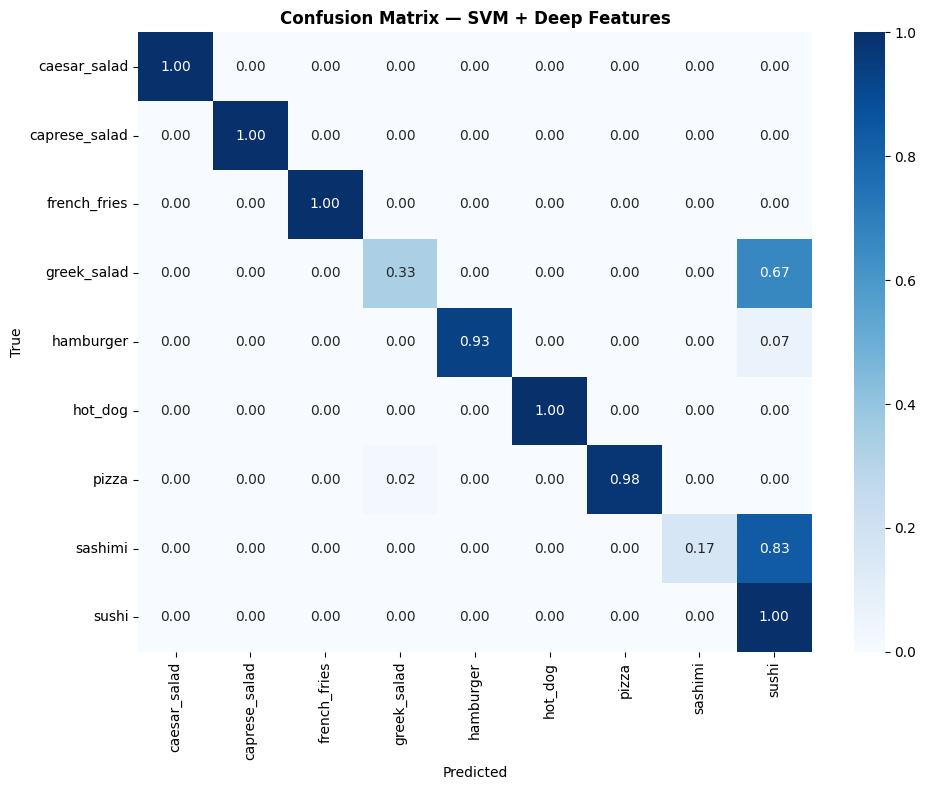

✓ results updated


In [48]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

if TRAIN_SVM:
    print("▶ TRAIN_SVM = True — Grid Search SVM...")
    svm_gs = GridSearchCV(
        SVC(kernel="rbf", probability=True, random_state=SEED),
        {"C":[0.1,1,10,100], "gamma":["scale","auto",0.001,0.01]},
        cv=5, scoring="accuracy", n_jobs=-1, verbose=1
    )
    svm_gs.fit(X_train_feat_sc, y_train_feat)
    svm_best = svm_gs.best_estimator_
    print(f"\n✓ Best params: {svm_gs.best_params_}  CV acc: {svm_gs.best_score_:.4f}")
    with open(f"{SAVE_DIR}/checkpoint_svm.pkl","wb") as _f: pickle.dump(svm_best, _f)
    print("✓ checkpoint_svm.pkl salvato")
else:
    print("⏭ Loading SVM from the Drive...")
    with open(f"{SAVE_DIR}/checkpoint_svm.pkl","rb") as _f: svm_best = pickle.load(_f)
    print("✓ SVM loaded")

y_true_svm, y_pred_svm = load_predictions("svm")
if y_true_svm is None:
    y_pred_svm = svm_best.predict(X_val_feat_sc)
    y_true_svm = y_val_feat
    save_predictions("svm", y_true_svm, y_pred_svm)
print(classification_report(y_true_svm, y_pred_svm, target_names=class_names))
plot_confusion_matrix(y_true_svm, y_pred_svm, "SVM + Deep Features")
results["SVM + Deep Features"] = {
    "val_accuracy": (y_pred_svm==y_true_svm).mean(), "val_top3_accuracy":None, "val_loss":None,
    "f1_macro": f1_score(y_true_svm,y_pred_svm,average="macro"),
    "f1_weighted": f1_score(y_true_svm,y_pred_svm,average="weighted"),
    "train_time_s":None, "inference_ms":None, "params":None,
    "best_params": svm_best.get_params(), "history_fe":None, "history_ft":None,
}
with open(f"{SAVE_DIR}/results_checkpoint.pkl","wb") as _f: pickle.dump(results, _f)
print("✓ results updated")

#### 6.3.5 Random Forest + Grid Search

The second classical classifier applied to the deep features is the Random
Forest. Random Forest is an ensemble method that builds a large number of
decision trees and combines their predictions through majority voting. Each tree
is trained on a random subset of the training data and uses a random subset of
features at each split, making the model robust to overfitting and noise.

A GridSearchCV is performed over three key hyperparameters:
  - n_estimators (100, 200, 300): number of trees in the forest.
  - max_depth (None, 10, 20): limits the maximum depth of each tree.
  - min_samples_split (2, 5): minimum number of samples required to split a
    node.
A 5-fold cross validation is performed on the training set for each combination.

The best model is evaluated on the validation set, and results are saved to the
results dictionary and to Drive.

⏭ Loading RF from the Drive...
✓ Random Forest loaded
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       1.00      0.67      0.80         3
    hamburger       0.96      0.93      0.95        29
      hot_dog       1.00      0.80      0.89         5
        pizza       1.00      1.00      1.00        42
      sashimi       1.00      0.17      0.29         6
        sushi       0.68      1.00      0.81        17

     accuracy                           0.93       131
    macro avg       0.96      0.84      0.86       131
 weighted avg       0.95      0.93      0.92       131



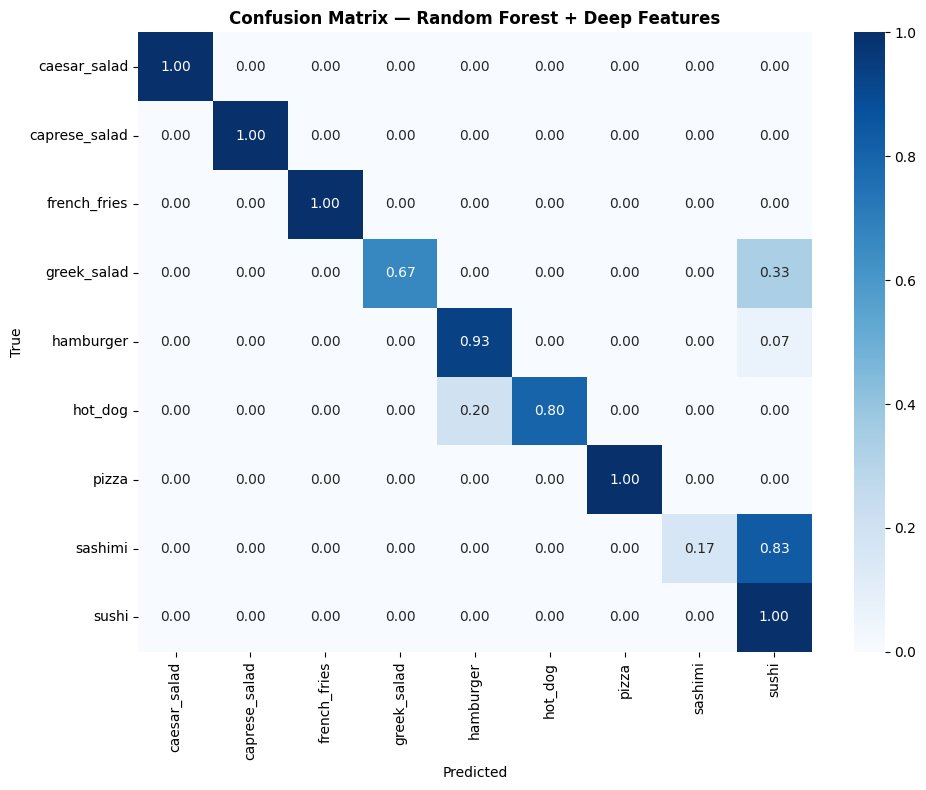

✓ results updated


In [49]:
from sklearn.ensemble import RandomForestClassifier

if TRAIN_RF:
    print("▶ TRAIN_RF = True — Grid Search Random Forest...")
    rf_gs = GridSearchCV(
        RandomForestClassifier(random_state=SEED,
                               class_weight="balanced"),
        {"n_estimators":[100,200,300],"max_depth":[None,10,20],"min_samples_split":[2,5]},
        cv=5, scoring="accuracy", n_jobs=-1, verbose=1
    )
    rf_gs.fit(X_train_feat_sc, y_train_feat)
    rf_best = rf_gs.best_estimator_
    print(f"\n✓ Best params: {rf_gs.best_params_}  CV acc: {rf_gs.best_score_:.4f}")
    with open(f"{SAVE_DIR}/checkpoint_rf.pkl","wb") as _f: pickle.dump(rf_best, _f)
    print("✓ checkpoint_rf.pkl saved")
else:
    print("⏭ Loading RF from the Drive...")
    with open(f"{SAVE_DIR}/checkpoint_rf.pkl","rb") as _f: rf_best = pickle.load(_f)
    print("✓ Random Forest loaded")

y_true_rf, y_pred_rf = load_predictions("rf")
if y_true_rf is None:
    y_pred_rf = rf_best.predict(X_val_feat_sc)
    y_true_rf = y_val_feat
    save_predictions("rf", y_true_rf, y_pred_rf)
print(classification_report(y_true_rf, y_pred_rf, target_names=class_names))
plot_confusion_matrix(y_true_rf, y_pred_rf, "Random Forest + Deep Features")
results["Random Forest + Deep Features"] = {
    "val_accuracy": (y_pred_rf==y_true_rf).mean(), "val_top3_accuracy":None, "val_loss":None,
    "f1_macro": f1_score(y_true_rf,y_pred_rf,average="macro"),
    "f1_weighted": f1_score(y_true_rf,y_pred_rf,average="weighted"),
    "train_time_s":None, "inference_ms":None, "params":None,
    "best_params": rf_best.get_params(), "history_fe":None, "history_ft":None,
}
with open(f"{SAVE_DIR}/results_checkpoint.pkl","wb") as _f: pickle.dump(results, _f)
print("✓ results updated")

#### 6.3.6 XGBoost + RandomizedSearchCV


The third classical classifier applied to the deep features is XGBoost (Extreme
Gradient Boosting). Unlike Random Forest, which builds trees in parallel and
combines them through voting, XGBoost is a boosting method that builds trees
sequentially — each tree focuses on correcting the errors made by the previous
ones. This makes it generally more accurate than Random Forest, at the cost of
being more sensitive to hyperparameter choices.

A RandomizedSearchCV is performed with 10 random iterations. Instead of
exhaustively testing all combinations, RandomizedSearch samples randomly from
the hyperparameter space — a more efficient approach when the search space is
large. The hyperparameters explored are:
  - n_estimators (100, 150, 200, 300): number of trees.
  - max_depth (3, 5, 7): complexity of each tree.
  - learning_rate (0.05, 0.1, 0.2, 0.3): contribution of each tree to the
    final prediction.
A 5-fold cross validation is performed for each sampled combination.

The best model is evaluated on the validation set, and results are saved to the
results dictionary and to Drive.

⏭ Loading XGBoost from the Drive...
✓ XGBoost loaded
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         4
caprese_salad       1.00      1.00      1.00         2
 french_fries       1.00      1.00      1.00        23
  greek_salad       0.75      1.00      0.86         3
    hamburger       0.96      0.90      0.93        29
      hot_dog       0.80      0.80      0.80         5
        pizza       1.00      0.98      0.99        42
      sashimi       0.80      0.67      0.73         6
        sushi       0.80      0.94      0.86        17

     accuracy                           0.94       131
    macro avg       0.90      0.92      0.91       131
 weighted avg       0.94      0.94      0.94       131



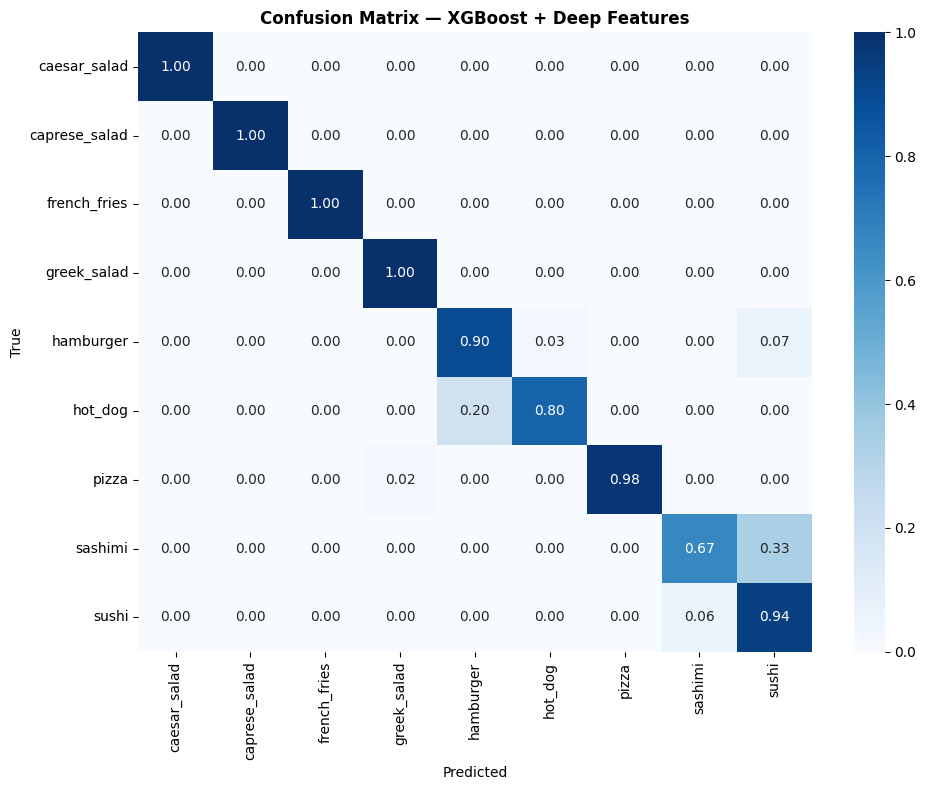

✓ results updated


In [50]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# FIX ERRORE 5: calcola sample_weight per XGBoost (non ha class_weight nativo multi-class)
from sklearn.utils.class_weight import compute_sample_weight
sample_weights = compute_sample_weight("balanced", y_train_feat)

if TRAIN_XGB:
    print("▶ TRAIN_XGB = True — RandomizedSearchCV XGBoost (10 iter)...")
    xgb_gs = RandomizedSearchCV(
        XGBClassifier(random_state=SEED, eval_metric="mlogloss"),
        {"n_estimators":[100,150,200,300],"max_depth":[3,5,7],"learning_rate":[0.05,0.1,0.2,0.3]},
        n_iter=10, cv=5, scoring="accuracy", n_jobs=-1, verbose=1, random_state=SEED,
    )
    xgb_gs.fit(X_train_feat_sc, y_train_feat,
               sample_weight=sample_weights)   # FIX ERRORE 5
    xgb_best = xgb_gs.best_estimator_
    print(f"\n✓ Best params: {xgb_gs.best_params_}  CV acc: {xgb_gs.best_score_:.4f}")
    with open(f"{SAVE_DIR}/checkpoint_xgb.pkl","wb") as _f: pickle.dump(xgb_best, _f)
    print("✓ checkpoint_xgb.pkl saved")
else:
    print("⏭ Loading XGBoost from the Drive...")
    with open(f"{SAVE_DIR}/checkpoint_xgb.pkl","rb") as _f: xgb_best = pickle.load(_f)
    print("✓ XGBoost loaded")

y_true_xgb, y_pred_xgb = load_predictions("xgb")
if y_true_xgb is None:
    y_pred_xgb = xgb_best.predict(X_val_feat_sc)
    y_true_xgb = y_val_feat
    save_predictions("xgb", y_true_xgb, y_pred_xgb)
print(classification_report(y_true_xgb, y_pred_xgb, target_names=class_names))
plot_confusion_matrix(y_true_xgb, y_pred_xgb, "XGBoost + Deep Features")
results["XGBoost + Deep Features"] = {
    "val_accuracy": (y_pred_xgb==y_true_xgb).mean(), "val_top3_accuracy":None, "val_loss":None,
    "f1_macro": f1_score(y_true_xgb,y_pred_xgb,average="macro"),
    "f1_weighted": f1_score(y_true_xgb,y_pred_xgb,average="weighted"),
    "train_time_s":None, "inference_ms":None, "params":None,
    "best_params": xgb_best.get_params(), "history_fe":None, "history_ft":None,
}
with open(f"{SAVE_DIR}/results_checkpoint.pkl","wb") as _f: pickle.dump(results, _f)
print("✓ results updated")

The three classical classifiers trained on EfficientNetV2S deep features obtain strong and similar results, with validation accuracy around 93%. This shows that the feature extraction step works well: EfficientNetV2S is able to transform the images into useful numerical representations, and even non-deep classifiers can separate most classes correctly.

This result is coherent with the PCA and t-SNE visualizations, where several classes already appeared as separated clusters. Since the feature space is already well structured, classifiers such as SVM, Random Forest and XGBoost can achieve good performance without training a full neural network.

However, these models do not outperform the best end-to-end transfer learning model. EfficientNetV2S used directly as a Feature Extractor with a neural classification head still achieves the best validation performance. The classical classifiers remain slightly lower, around 93% accuracy.

The confusion matrices show that the main errors are concentrated in visually similar classes, especially sushi and sashimi, and in some smaller classes. For example, XGBoost classifies most classes very well, but sashimi is still partly confused with sushi. This suggests that the remaining mistakes are not only due to the classifier, but also to the limited number of examples and the visual similarity between some food categories.

Overall, the hybrid approach works well and confirms the quality of the EfficientNetV2S features. However, since it does not improve over the neural Feature Extractor model, it is useful mainly as a comparison rather than as the final selected solution.

## **7. Model comparison**

 **Resume after crash**: the following cell automatically loads results_checkpoint.pkl if results is empty.

In [61]:
# Load results from Drive if the session has been reset
if not results:
    _path = f"{SAVE_DIR}/results_checkpoint.pkl"
    if os.path.exists(_path):
        with open(_path,"rb") as _f: results = pickle.load(_f)
        print(f"✓ results uploaded from Drive — models: {list(results.keys())}")
    else:
        print("⚠ No results_checkpoint.pkl found on Drive")

# Load fe_metrics if necessary (for 7.5)
if not os.path.exists(f"{SAVE_DIR}/fe_metrics.pkl"):
    print("⚠ fe_metrics.pkl not found — 7.5 may not work")
else:
    with open(f"{SAVE_DIR}/fe_metrics.pkl","rb") as _f: _fe = pickle.load(_f)
    val_acc_fe,     val_top3_fe,     f1_mac_fe     = _fe.get("effnet",  (None,None,None))
    val_acc_res_fe, val_top3_res_fe, f1_mac_res_fe = _fe.get("resnet",  (None,None,None))
    val_acc_mob_fe, val_top3_mob_fe, f1_mac_mob_fe = _fe.get("mobile",  (None,None,None))
    print("✓ fe_metrics loaded from the Drive")

✓ fe_metrics loaded from the Drive


### 7.1 Summary table

In [62]:
if not results:
    _path = f"{SAVE_DIR}/results_checkpoint.pkl"
    if os.path.exists(_path):
        with open(_path,"rb") as _f: results = pickle.load(_f)
        print(f"✓ results uploaded from Drive — models: {list(results.keys())}")
    else:
        print("⚠ No results_checkpoint.pkl found on Drive")
else:
    print(f"✓ results already in memory — models: {list(results.keys())}")

_tt_path = f"{SAVE_DIR}/train_times.pkl"
if os.path.exists(_tt_path):
    with open(_tt_path,"rb") as _f: _saved_tt = pickle.load(_f)
    _name_map = {
        "CNN scratch":       "CNN scratch",
        "effnet_fe":         "EfficientNetV2S FE",
        "effnet_ft":         "EfficientNetV2S FT",
        "resnet_fe":         "ResNet50 FE",
        "resnet_ft":         "ResNet50 FT",
        "mobile_fe":         "MobileNetV3Large FE",
        "mobile_ft":         "MobileNetV3Large FT",
    }
    for key, model_name in _name_map.items():
        if model_name in results and not results[model_name].get("train_time_s"):
            results[model_name]["train_time_s"] = _saved_tt.get(key)
    for backbone, fe_key, ft_key, ft_name in [
        ("effnet",  "effnet_fe",  "effnet_ft",  "EfficientNetV2S FT"),
        ("resnet",  "resnet_fe",  "resnet_ft",  "ResNet50 FT"),
        ("mobile",  "mobile_fe",  "mobile_ft",  "MobileNetV3Large FT"),
    ]:
        if ft_name in results and not results[ft_name].get("train_time_s"):
            fe_t = _saved_tt.get(fe_key, 0) or 0
            ft_t = _saved_tt.get(ft_key, 0) or 0
            if fe_t or ft_t: results[ft_name]["train_time_s"] = fe_t + ft_t
    print("✓ train_times uploaded from Drive and added to results")
else:
    print("⚠ train_times.pkl not found — training times will be None")

if os.path.exists(f"{SAVE_DIR}/fe_metrics.pkl"):
    with open(f"{SAVE_DIR}/fe_metrics.pkl","rb") as _f: _fe = pickle.load(_f)
    val_acc_fe,     val_top3_fe,     f1_mac_fe     = _fe.get("effnet",  (None,None,None))
    val_acc_res_fe, val_top3_res_fe, f1_mac_res_fe = _fe.get("resnet",  (None,None,None))
    val_acc_mob_fe, val_top3_mob_fe, f1_mac_mob_fe = _fe.get("mobile",  (None,None,None))
    print("✓ fe_metrics loaded from the Drive")
else:
    print("⚠ fe_metrics.pkl not found — 7.5 It might not work")

✓ results already in memory — models: ['CNN scratch', 'EfficientNetV2S FE', 'EfficientNetV2S FT', 'ResNet50 FE', 'ResNet50 FT', 'MobileNetV3Large FE', 'MobileNetV3Large FT', 'SVM + Deep Features', 'Random Forest + Deep Features', 'XGBoost + Deep Features']
✓ train_times uploaded from Drive and added to results
✓ fe_metrics loaded from the Drive


The validation comparison shows a clear difference between the CNN trained from scratch and all the transfer learning approaches. The CNN scratch reaches only 39.06% validation accuracy and 0.2188 F1 macro, confirming that training a CNN from zero is not suitable for this small and imbalanced dataset.

The best overall model is EfficientNetV2S Feature Extractor. It obtains the highest validation accuracy, 97.66%, and the highest F1 macro, 0.9461. This is important because F1 macro gives the same importance to all classes, including the minority ones. For this reason, EfficientNetV2S FE is the most balanced and reliable choice.

Fine-tuning EfficientNetV2S does not improve the result. Its validation accuracy is slightly lower, 96.88%, and the F1 macro decreases to 0.9313. This suggests that the frozen backbone was already strong enough and that fine-tuning adds complexity without a real benefit.

MobileNetV3Large also performs well, with 94.53% validation accuracy and 0.9199 F1 macro. It is an interesting alternative because it is lighter, but it does not reach the same performance as EfficientNetV2S FE.

The classical classifiers trained on deep features also achieve good results, around 92–94% accuracy. XGBoost is the best among them, with 93.89% accuracy and 0.9073 F1 macro. This confirms that the features extracted by EfficientNetV2S are useful, but the classical classifiers still remain below the neural classification head.

Overall, the model selected for the final test evaluation is EfficientNetV2S Feature Extractor. It gives the best validation performance and avoids the extra complexity of fine-tuning. The timing values are considered only as indicative, so the final choice is mainly based on validation accuracy and F1 macro.


In [66]:
rows = []
for name, r in results.items():
    rows.append({
        "Model"      : name,
        "Val Accuracy" : f"{r['val_accuracy']*100:.2f}%"      if r.get('val_accuracy')      else "N/A",
        "Val Top-3"    : f"{r['val_top3_accuracy']*100:.2f}%" if r.get('val_top3_accuracy') else "N/A",
        "F1 Macro"     : f"{r['f1_macro']:.4f}"               if r.get('f1_macro')          else "N/A",
        "F1 Weighted"  : f"{r['f1_weighted']:.4f}"            if r.get('f1_weighted')       else "N/A",
        "Train Time"   : f"{r['train_time_s']/60:.1f} min"    if r.get('train_time_s')      else "N/A",
        "Inf/img (ms)" : f"{r['inference_ms']:.2f}"           if r.get('inference_ms')      else "N/A",
        "Parametri"    : f"{r['params']:,}"                   if r.get('params')            else "N/A",
    })
df_results = pd.DataFrame(rows).set_index("Model")
print("=== MODEL COMPARISON (Validation Set) ===\n")
print(df_results.to_string())

=== MODEL COMPARISON (Validation Set) ===

                              Val Accuracy Val Top-3 F1 Macro F1 Weighted Train Time Inf/img (ms)   Parametri
Model                                                                                                        
CNN scratch                         39.06%    75.00%   0.2188      0.3444        N/A        20.28     116,217
EfficientNetV2S FE                  97.66%    99.22%   0.9461      0.9719    5.3 min        83.99         N/A
EfficientNetV2S FT                  96.88%   100.00%   0.9313      0.9567   13.9 min         6.19  20,662,377
ResNet50 FE                         92.97%    96.88%   0.8750      0.9124    4.0 min        38.89         N/A
ResNet50 FT                         92.19%    96.88%   0.9069      0.9153    6.7 min         7.54  24,115,337
MobileNetV3Large FE                 94.53%    98.44%   0.9199      0.9389    3.2 min        43.13         N/A
MobileNetV3Large FT                 94.53%    98.44%   0.9199      0.9389    

### 7.2 Accuracy vs F1

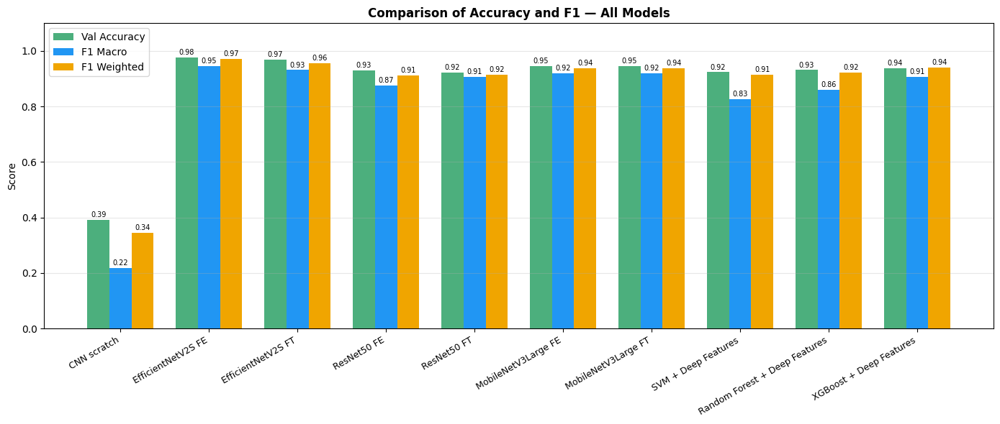

In [67]:
model_names  = list(results.keys())
val_accs     = [results[m]["val_accuracy"] or 0 for m in model_names]
f1_macros    = [results[m]["f1_macro"]     or 0 for m in model_names]
f1_weighteds = [results[m]["f1_weighted"]  or 0 for m in model_names]
x = np.arange(len(model_names)); width = 0.25
fig, ax = plt.subplots(figsize=(14,6))
b1 = ax.bar(x-width, val_accs,     width, label="Val Accuracy", color="#4caf7d", edgecolor="none")
b2 = ax.bar(x,       f1_macros,    width, label="F1 Macro",     color="#2196f3", edgecolor="none")
b3 = ax.bar(x+width, f1_weighteds, width, label="F1 Weighted",  color="#f0a500", edgecolor="none")
for bars in [b1,b2,b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2, h+0.005, f"{h:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Score"); ax.set_ylim(0,1.1)
ax.set_title("Comparison of Accuracy and F1 — All Models", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 7.3 Top-3 Accuracy

Top-3 accuracy is a classification metric that checks whether the correct class is included among the three most probable predictions of the model. Unlike standard accuracy, which only considers the top prediction, top-3 accuracy is more flexible: a prediction is counted as correct if the true label appears in the model’s first three choices.

This metric is useful in this project because some food classes are visually similar, such as sushi and sashimi or the different salad categories. In these cases, even if the model does not choose the correct class as its first prediction, it may still recognize it as one of the most likely options.

The chart shows that all transfer learning models reach very high top-3 accuracy. EfficientNetV2S FE obtains 99.2%, while EfficientNetV2S FT reaches 100%. ResNet50 and MobileNetV3Large also remain very high, around 96.9% and 98.4%.

The CNN trained from scratch reaches only 75.0%, confirming again that it is much weaker than the pretrained models. However, its top-3 accuracy is still higher than its standard accuracy, meaning that the correct class is sometimes present among the top predictions even when the first choice is wrong.

/tmp/ipykernel_1223/3403447702.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=30, ha="right", fontsize=9)


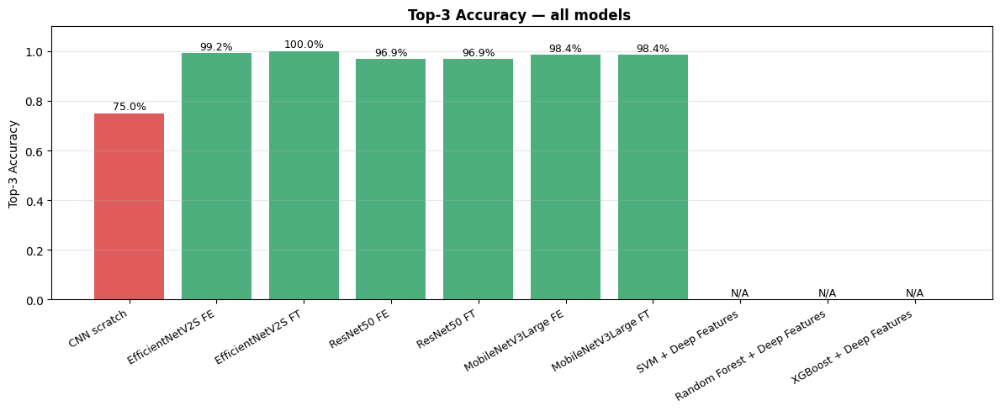

In [68]:
top3_vals = [results[m]["val_top3_accuracy"] or 0 for m in model_names]
colors_top3 = ["#4caf7d" if v>0.90 else "#f0a500" if v>0.80 else "#e05c5c" for v in top3_vals]
fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(model_names, top3_vals, color=colors_top3, edgecolor="none")
for bar, v in zip(bars, top3_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f"{v*100:.1f}%" if v else "N/A", ha="center", va="bottom", fontsize=9)
ax.set_xticklabels(model_names, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Top-3 Accuracy"); ax.set_ylim(0,1.1)
ax.set_title("Top-3 Accuracy — all models ", fontweight="bold")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 7.4 Effect of fine-tuning — all backbones

This section compares the validation accuracy obtained before and after fine-tuning for each pretrained backbone.

The plot shows that fine-tuning does not bring a clear improvement in this project. EfficientNetV2S decreases slightly from 97.66% to 96.88%, while ResNet50 also decreases from 92.97% to 92.19%. MobileNetV3Large remains exactly the same, with 94.53% accuracy both before and after fine-tuning.

These results suggest that the frozen pretrained features are already strong enough for this dataset. Since the dataset is small, unfreezing part of the backbone does not necessarily help: the model may start adapting too much to the limited training data instead of improving generalization.

This is especially clear for EfficientNetV2S, which already performs best in the Feature Extractor phase. Fine-tuning adds more trainable parameters and training time, but slightly reduces validation accuracy.

For ResNet50, the decrease in performances is small, and previous metrics showed a slight improvement in F1 macro. This means that fine-tuning may help class balance a little, but not enough to make it the best model.

Overall, the comparison supports the choice of using EfficientNetV2S Feature Extractor as the final model. It achieves the best validation performance while keeping the training process simpler and more stable.


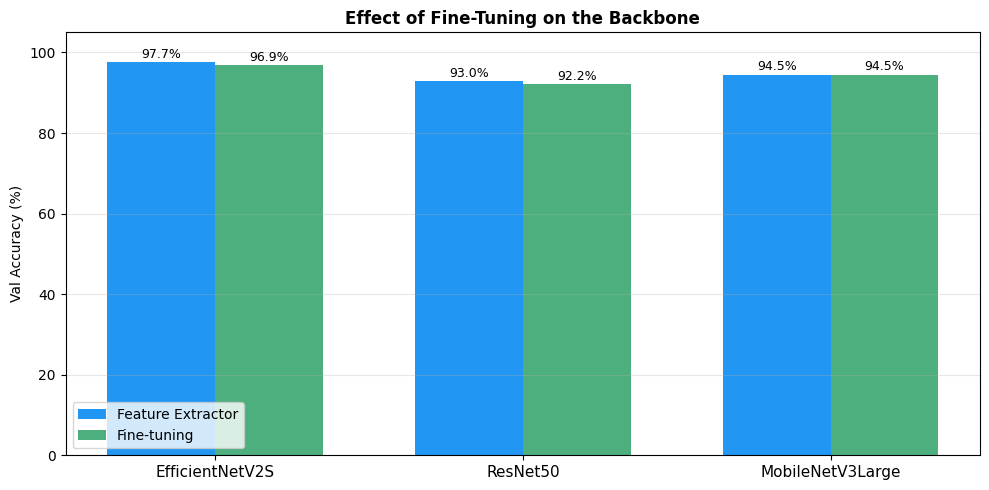


=== DELTA FINE-TUNING ===
  EfficientNetV2S       FE: 97.66%  FT: 96.88%  Delta: -0.78%
  ResNet50              FE: 92.97%  FT: 92.19%  Delta: -0.78%
  MobileNetV3Large      FE: 94.53%  FT: 94.53%  Delta: +0.00%


In [69]:
### 7.5 Effect of fine-tuning — all backbones
backbone_pairs = [
    ("EfficientNetV2S", "EfficientNetV2S FE", "EfficientNetV2S FT"),
    ("ResNet50",        "ResNet50 FE",        "ResNet50 FT"),
    ("MobileNetV3Large","MobileNetV3Large FE", "MobileNetV3Large FT"),
]
_fe_accs = [results[fe]["val_accuracy"] for _, fe, _ in backbone_pairs if fe in results]
_ft_accs = [results[ft]["val_accuracy"] for _, _, ft in backbone_pairs if ft in results]
_labels  = [name for name, fe, ft in backbone_pairs if fe in results and ft in results]

if len(_labels) < len(backbone_pairs):
    print("⚠ Some backbones are missing from the results—check the checkpoints")

if _labels:
    x = np.arange(len(_labels)); width = 0.35
    fig, ax = plt.subplots(figsize=(10,5))
    b1 = ax.bar(x-width/2, [v*100 for v in _fe_accs], width, label="Feature Extractor", color="#2196f3", edgecolor="none")
    b2 = ax.bar(x+width/2, [v*100 for v in _ft_accs], width, label="Fine-tuning",       color="#4caf7d", edgecolor="none")
    for bar, v in zip(list(b1)+list(b2), [v*100 for v in _fe_accs+_ft_accs]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(_labels, fontsize=11)
    ax.set_ylabel("Val Accuracy (%)"); ax.set_ylim(0,105)
    ax.set_title("Effect of Fine-Tuning on the Backbone", fontweight="bold")
    ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()
    print("\n=== DELTA FINE-TUNING ===")
    for name, fe, ft in zip(_labels, _fe_accs, _ft_accs):
        print(f"  {name:<20}  FE: {fe*100:.2f}%  FT: {ft*100:.2f}%  Delta: {(ft-fe)*100:>+.2f}%")

### 7.5 Selecting the Best Model


In [70]:
candidates = {
    "EfficientNetV2S FE": (f"{SAVE_DIR}/best_effnet_fe.keras",  ds_val_eff,  ds_test_eff),
    "EfficientNetV2S FT": (f"{SAVE_DIR}/best_effnet_ft.keras",  ds_val_eff,  ds_test_eff),
    "ResNet50 FE":        (f"{SAVE_DIR}/best_resnet_fe.keras",  ds_val_res,  ds_test_res),
    "ResNet50 FT":        (f"{SAVE_DIR}/best_resnet_ft.keras",  ds_val_res,  ds_test_res),
    "MobileNetV3Large FE":(f"{SAVE_DIR}/best_mobile_fe.keras",  ds_val_mob,  ds_test_mob),
    "MobileNetV3Large FT":(f"{SAVE_DIR}/best_mobile_ft.keras",  ds_val_mob,  ds_test_mob),
}

best_name    = None
best_f1_macro = -1.0   # criterio: max F1 Macro

print("=== MODEL COMPARISON (validation set) — criterion: F1 Macro ===")
print(f"{'Model':<25} {'F1 Macro':>10} {'Val Accuracy':>14} {'Val Loss':>10}")
print("-" * 62)

for name, (ckpt, ds_v, ds_t) in candidates.items():
    if name in results and os.path.exists(ckpt):
        va  = results[name].get("val_accuracy", 0.0) or 0.0
        vl  = results[name].get("val_loss",     None)
        f1  = results[name].get("f1_macro",     None)

        if f1 is None:
            print(f"  ⚠ {name}: f1_macro not in results")
            continue

        flag = "  ← BEST" if f1 > best_f1_macro else ""
        vl_str = f"{vl:.4f}" if vl is not None else "N/A"
        print(f"  {name:<23} {f1:>10.4f} {va*100:>13.2f}%  {vl_str:>10}{flag}")

        if f1 > best_f1_macro:
            best_f1_macro = f1
            best_name     = name

if best_name is None:
    best_name = "EfficientNetV2S FE"
    print(f"\n⚠ results empty — fallback a '{best_name}'.")

best_ckpt, best_ds_val, best_ds_test = candidates[best_name]
best_model = keras.models.load_model(best_ckpt)
print(f"\n✓ Winning model: {best_name}")
print(f"  (Criterion: max F1 Macro val = {best_f1_macro:.4f})")

val_loss_v, val_acc_v, val_top3_v = best_model.evaluate(best_ds_val, verbose=0)
print(f"  Val Loss     : {val_loss_v:.4f}")
print(f"  Val Accuracy : {val_acc_v*100:.2f}%")
print(f"  Val Top-3    : {val_top3_v*100:.2f}%")

=== MODEL COMPARISON (validation set) — criterion: F1 Macro ===
Model                       F1 Macro   Val Accuracy   Val Loss
--------------------------------------------------------------
  EfficientNetV2S FE          0.9461         97.66%         N/A  ← BEST
  EfficientNetV2S FT          0.9313         96.88%      0.0937
  ResNet50 FE                 0.8750         92.97%         N/A
  ResNet50 FT                 0.9069         92.19%      0.3150
  MobileNetV3Large FE         0.9199         94.53%         N/A
  MobileNetV3Large FT         0.9199         94.53%      0.1807

✓ Winning model: EfficientNetV2S FE
  (Criterion: max F1 Macro val = 0.9461)
  Val Loss     : 0.0759
  Val Accuracy : 97.66%
  Val Top-3    : 99.22%


### 7.6 Evaluation on the test set

After comparing all models on the validation set, the selected model is EfficientNetV2S Feature Extractor. This model was chosen because it achieved the best validation performance, with the highest validation accuracy and F1 macro.

Only after the model selection, the final model is evaluated on the test set. The test set was kept completely separate during training and validation, so the model had never seen these images before. For this reason, the test results provide the most realistic estimate of the model's generalization ability.

On the test set, EfficientNetV2S Feature Extractor reaches 96.27% accuracy, 98.51% top-3 accuracy, 0.8830 F1 macro and 0.9601 F1 weighted. These results confirm that the model generalizes well to unseen images.

The weighted F1 is very high, while the macro F1 is lower. This difference is mainly due to the strong class imbalance: some minority classes have very few test images, so even one or two mistakes can strongly reduce the macro average.

Overall, the test evaluation confirms that EfficientNetV2S Feature Extractor is a reliable final model for this project.


✓ Prediction tests loaded from cache
=== TEST SET RESULTS ===
  Test Accuracy  : 0.9627  (96.27%)
  Test Top-3     : 0.9851  (98.51%)
  Test Loss      : 0.1695
  F1 Macro       : 0.8830
  F1 Weighted    : 0.9601

=== Classification Report — Test Set ===
               precision    recall  f1-score   support

 caesar_salad       1.00      1.00      1.00         3
caprese_salad       0.67      1.00      0.80         2
 french_fries       1.00      0.96      0.98        25
  greek_salad       1.00      0.33      0.50         3
    hamburger       1.00      0.97      0.98        29
      hot_dog       0.80      1.00      0.89         4
        pizza       0.98      1.00      0.99        43
      sashimi       0.83      0.83      0.83         6
        sushi       0.95      1.00      0.97        19

     accuracy                           0.96       134
    macro avg       0.91      0.90      0.88       134
 weighted avg       0.97      0.96      0.96       134



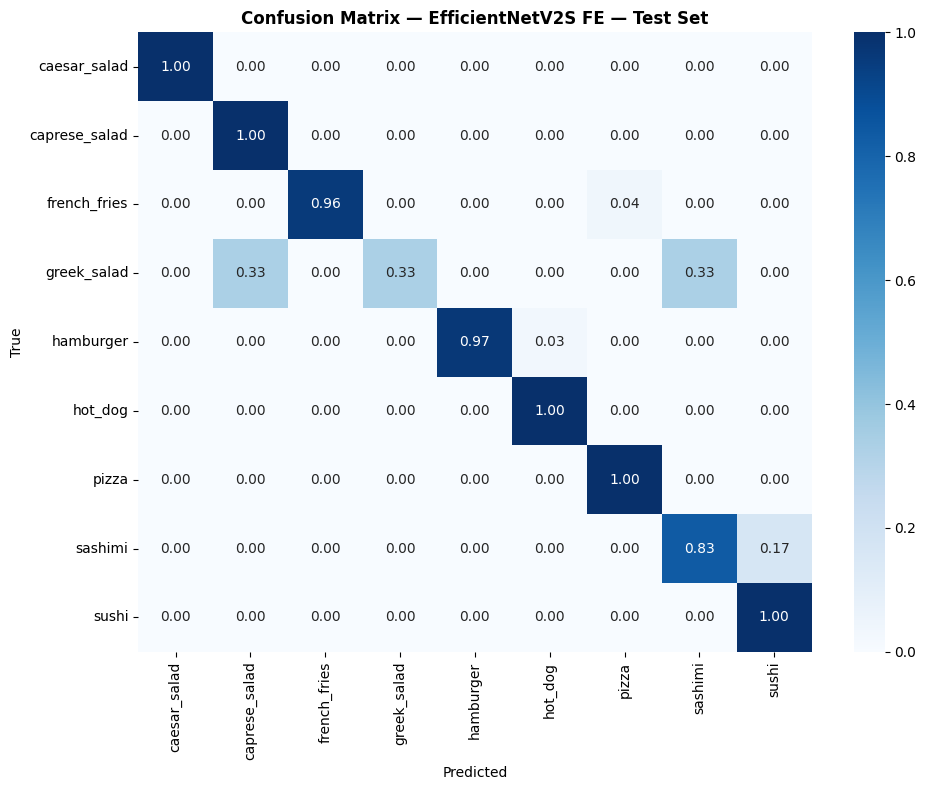

In [71]:
y_true_test, y_pred_test = load_predictions("best_model_test")
if y_true_test is None:
    print("Calculating test set predictions...")
    test_loss, test_acc, test_top3 = best_model.evaluate(best_ds_test, verbose=0)
    y_true_test, y_pred_test = get_predictions(best_model, best_ds_test)
    save_predictions("best_model_test", y_true_test, y_pred_test)
    # save test metrics
    with open(f"{SAVE_DIR}/test_metrics.pkl","wb") as _f:
        pickle.dump({"loss":test_loss,"acc":test_acc,"top3":test_top3}, _f)
else:
    print("✓ Prediction tests loaded from cache")
    with open(f"{SAVE_DIR}/test_metrics.pkl","rb") as _f: _tm = pickle.load(_f)
    test_loss, test_acc, test_top3 = _tm["loss"], _tm["acc"], _tm["top3"]

f1_mac_test = f1_score(y_true_test, y_pred_test, average="macro")
f1_wei_test = f1_score(y_true_test, y_pred_test, average="weighted")
print("=== TEST SET RESULTS ===")
print(f"  Test Accuracy  : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"  Test Top-3     : {test_top3:.4f}  ({test_top3*100:.2f}%)")
print(f"  Test Loss      : {test_loss:.4f}")
print(f"  F1 Macro       : {f1_mac_test:.4f}")
print(f"  F1 Weighted    : {f1_wei_test:.4f}")
print("\n=== Classification Report — Test Set ===")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))
plot_confusion_matrix(y_true_test, y_pred_test, f"{best_name} — Test Set")

The confusion matrices show the final performance of the selected model, EfficientNetV2S Feature Extractor, on the test set. The left matrix reports normalized proportions, while the right matrix reports the absolute number of images for each class.

Overall, the model performs very well on unseen data. Most classes are classified almost perfectly. In particular, caesar_salad, caprese_salad, hot_dog, pizza and sushi reach 100% correct predictions on the test set. Hamburger is also very strong, with 28 correct predictions out of 29, and french_fries has only one error out of 25 images.

The main weakness is greek_salad. This class has only 3 test images, and the model correctly classifies only 1 of them. The other two are confused with caprese_salad and sashimi. This explains why the macro F1 is lower than the weighted F1: minority classes have very few samples, so even one or two mistakes strongly affect their score.

Sashimi is another slightly difficult class. Out of 6 test images, 5 are correctly classified, while 1 is confused with sushi. This error is understandable because sashimi and sushi are visually similar and often share similar ingredients and presentation.

The absolute confusion matrix is important because it shows how small some classes are in the test set. For example, greek_salad has only 3 images and caprese_salad only 2. Therefore, the normalized matrix must be interpreted carefully: a value such as 0.33 may correspond to just one image.

Overall, the confusion matrices confirm that the model generalizes well, with only a few errors mainly concentrated in small or visually similar classes.


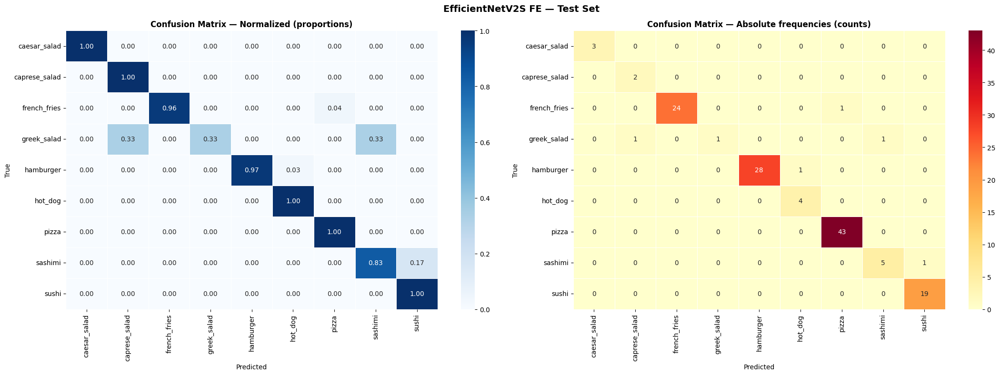


=== TOP 5 (Absolute) Confusions ===
  True: sashimi             Pred: sushi               N = 1
  True: hamburger           Pred: hot_dog             N = 1
  True: greek_salad         Pred: sashimi             N = 1
  True: greek_salad         Pred: caprese_salad       N = 1
  True: french_fries        Pred: pizza               N = 1


In [72]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_abs = confusion_matrix(y_true_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(22, 8))

# Normalization
cm_norm = cm_abs.astype(float) / cm_abs.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0],
            linewidths=0.5)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("Confusion Matrix — Normalized (proportions)", fontweight="bold")

# Absolute frequencies
sns.heatmap(cm_abs, annot=True, fmt="d", cmap="YlOrRd",
            xticklabels=class_names, yticklabels=class_names, ax=axes[1],
            linewidths=0.5)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].set_title("Confusion Matrix — Absolute frequencies (counts)", fontweight="bold")

plt.suptitle("EfficientNetV2S FE — Test Set", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.show()

# Riepilogo errori principali
print("\n=== TOP 5 (Absolute) Confusions ===")
_cm_flat = [(cm_abs[i,j], class_names[i], class_names[j])
            for i in range(len(class_names)) for j in range(len(class_names)) if i!=j]
for count, true_c, pred_c in sorted(_cm_flat, reverse=True)[:5]:
    print(f"  True: {true_c:<18}  Pred: {pred_c:<18}  N = {count}")

### 7.7 Confronto Validation vs Test

This section compares the validation and test performance of the selected model, EfficientNetV2S Feature Extractor.

The results are very consistent between validation and test. Accuracy decreases only slightly, from 97.7% on validation to 96.3% on test. Top-3 accuracy also remains very high, going from 99.2% to 98.5%. This shows that the model generalizes well and does not depend only on the validation set.

The weighted F1 score is also stable, decreasing from 0.972 to 0.960. This confirms that the model performs well on the dataset as a whole, especially on the classes with more images.

The main difference is in F1 macro, which decreases from 0.946 to 0.883. This is mainly due to the minority classes, especially greek_salad and sashimi. Since these classes have very few samples in the test set, even one or two wrong predictions have a strong impact on the macro average.

The test loss is higher than the validation loss, increasing from 0.0759 to 0.1695. This suggests that the model is slightly less confident or makes a few more costly mistakes on the test set. However, the main metrics remain high, so this does not indicate a serious generalization problem.

Overall, the comparison confirms that EfficientNetV2S Feature Extractor is a reliable final model. The small drop from validation to test is expected, and the model maintains strong performance on unseen images.


=== COMPARISON: VALIDATION VS TESTING ===
Metric                 Validation         Test      Delta
--------------------------------------------------------
  Accuracy                 0.9766       0.9627    -0.0139
  Top-3                    0.9922       0.9851    -0.0071
  F1 Macro                 0.9461       0.8830    -0.0631  --
  F1 Weighted              0.9719       0.9601    -0.0118
  Loss                     0.0759       0.1695    +0.0935


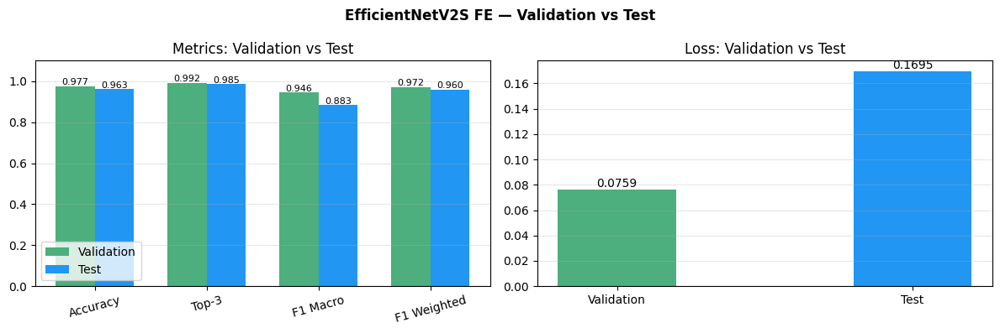

In [73]:
print("=== COMPARISON: VALIDATION VS TESTING ===")
print(f"{'Metric':<20} {'Validation':>12} {'Test':>12} {'Delta':>10}"); print("-"*56)

best_r = results.get(best_name, {})

metrics_compare = [
    ("Accuracy",    val_acc_v,                       test_acc),
    ("Top-3",       val_top3_v,                      test_top3),
    ("F1 Macro",    best_r.get("f1_macro",   None),  f1_mac_test),
    ("F1 Weighted", best_r.get("f1_weighted", None), f1_wei_test),
    ("Loss",        val_loss_v,                      test_loss),
]
for name, val, test in metrics_compare:
    if val is None:
        print(f"  {name:<18} {'N/A':>12} {test:>12.4f} {'N/A':>10}")
        continue
    delta = test - val
    flag = "  --" if delta < -0.05 else ""
    print(f"  {name:<18} {val:>12.4f} {test:>12.4f} {delta:>+10.4f}{flag}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metric_names = ["Accuracy", "Top-3", "F1 Macro", "F1 Weighted"]
val_vals  = [val_acc_v, val_top3_v,
             best_r.get("f1_macro", 0), best_r.get("f1_weighted", 0)]
test_vals = [test_acc, test_top3, f1_mac_test, f1_wei_test]
x = np.arange(len(metric_names)); w = 0.35
axes[0].bar(x-w/2, val_vals,  w, label="Validation", color="#4caf7d", edgecolor="none")
axes[0].bar(x+w/2, test_vals, w, label="Test",        color="#2196f3", edgecolor="none")
for i, (v, t) in enumerate(zip(val_vals, test_vals)):
    axes[0].text(i-w/2, v+0.005, f"{v:.3f}", ha="center", fontsize=8)
    axes[0].text(i+w/2, t+0.005, f"{t:.3f}", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(metric_names, rotation=15)
axes[0].set_ylim(0, 1.1); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("Metrics: Validation vs Test")
axes[1].bar(["Validation","Test"], [val_loss_v, test_loss],
            color=["#4caf7d","#2196f3"], edgecolor="none", width=0.4)
axes[1].text(0, val_loss_v+0.002, f"{val_loss_v:.4f}", ha="center", fontsize=10)
axes[1].text(1, test_loss +0.002, f"{test_loss:.4f}",  ha="center", fontsize=10)
axes[1].set_title("Loss: Validation vs Test"); axes[1].grid(axis="y", alpha=0.3)
plt.suptitle(f"{best_name} — Validation vs Test", fontweight="bold")
plt.tight_layout(); plt.show()

## **8. Explainable AI (XAI)**

The final section is dedicated to Explainable AI (XAI), a set of techniques
that allow us to understand and interpret the decisions made by a machine
learning model. The core question XAI tries to answer is: "why did the model
predict this class?"

Deep learning models, and CNNs in particular, are often considered black boxes:
they produce accurate predictions but their internal reasoning is difficult to
interpret. This is a significant limitation in many real-world scenarios. A
particularly important concern is that a model can achieve high accuracy for the
wrong reasons — for example, learning to recognize the background color or the
presence of a plate rather than the actual food. Without XAI tools, this kind
of spurious correlation would go completely unnoticed.

Two XAI techniques are applied to the best performing model:
  - Grad-CAM: produces a heatmap highlighting the regions of the image that
    most influenced the model's prediction.
  - LIME: generates a local explanation by perturbing the image and observing
    how the prediction changes.


### 8.1 Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping) produces a heatmap
highlighting the regions of the image that most influenced the model's
prediction. The underlying idea is intuitive: if the gradients of the predicted
class with respect to a certain convolutional layer are high in a specific
region, it means that region was important for the final decision.

The implementation uses two functions:
  - make_gradcam_heatmap: builds an intermediate model that exposes both the
    output of the last convolutional layer and the final prediction. Through
    GradientTape, the gradients of the predicted class with respect to the
    feature maps of that layer are computed. These gradients are spatially
    averaged (pooled_grads) to obtain a weight for each feature map, indicating
    how much each one contributed to the prediction. The heatmap is obtained by
    multiplying these weights by the feature maps and summing the result. A ReLU
    is applied to keep only positive activations, and the result is normalized
    to [0, 1].
  - overlay_gradcam: resizes the heatmap to match the image dimensions, applies
    the JET colormap (red = most important, blue = least relevant), and blends
    it with the original image with a transparency of 0.4.

The last convolutional layer of the best model is identified automatically:
first looking for "top_conv" (the name used by EfficientNetV2S), and if not
found, scanning the layers in reverse order until the last Conv2D is found.


In [74]:
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = keras.Model(inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output])
    img_tensor = tf.cast(img_array, tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor, training=False)
        if pred_index is None: pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img_orig, heatmap, alpha=0.4):
    heatmap_r = cv2.resize(heatmap, (img_orig.shape[1], img_orig.shape[0]))
    heatmap_c = cv2.applyColorMap(np.uint8(255*heatmap_r), cv2.COLORMAP_JET)
    heatmap_c = cv2.cvtColor(heatmap_c, cv2.COLOR_BGR2RGB)
    return np.uint8(img_orig*(1-alpha) + heatmap_c*alpha)

layer_names_in_model = {l.name for l in best_model.layers}

CANDIDATE_CONV_LAYERS = ["top_conv", "top_activation", "Conv_2", "block7b_project_conv"]
LAST_CONV_LAYER = None

for candidate in CANDIDATE_CONV_LAYERS:
    if candidate in layer_names_in_model:
        LAST_CONV_LAYER = candidate
        print(f"✓ Layer Grad-CAM found by name: {LAST_CONV_LAYER}")
        break

if LAST_CONV_LAYER is None:
    for l in reversed(best_model.layers):
        if isinstance(l, keras.layers.Conv2D):
            if l.name in layer_names_in_model:
                LAST_CONV_LAYER = l.name
                print(f"✓ Layer Grad-CAM found by type Conv2D: {LAST_CONV_LAYER}")
                break

if LAST_CONV_LAYER is None:
    for l in reversed(best_model.layers):
        if "conv" in l.name.lower() and l.name in layer_names_in_model:
            LAST_CONV_LAYER = l.name
            print(f"✓ Layer Grad-CAM found by partial name: {LAST_CONV_LAYER}")
            break

assert LAST_CONV_LAYER is not None, \
    "❌ No Conv layers found in the model — check the architecture using `best_model.summary()`"
print(f"✓ LAST_CONV_LAYER = '{LAST_CONV_LAYER}'")

✓ Layer Grad-CAM found by name: top_conv
✓ LAST_CONV_LAYER = 'top_conv'


#### 8.1.1 Grad-CAM

Grad-CAM is applied to two samples per class from the test set. For each image, the grid shows three elements: the original image, the raw heatmap and the heatmap overlaid on the original image. The title also reports the predicted class and the confidence score.

Overall, the results are positive. In many examples, the highlighted regions are located on the food itself, meaning that the model is using relevant visual information to make its prediction. This is visible, for example, in classes such as caesar_salad, caprese_salad, french_fries, hamburger and pizza, where the heatmap often focuses on the central food area.

The confidence scores are also generally high, often close to or equal to 100%. This is coherent with the strong test performance obtained by the selected model.

However, Grad-CAM also shows some limitations. In a few images, the model does not focus only on the food, but also on parts of the plate, the table or the background. This is especially visible when the food occupies only a small part of the image or when the image contains strong colors outside the food region. These cases suggest that the model may sometimes use contextual visual cues together with the actual food.

This visualization is useful because it confirms that the model usually looks at meaningful regions, but it also helps identify possible weaknesses. Even when the prediction is correct, Grad-CAM shows whether the decision is based mainly on the food or partly on irrelevant elements of the image.

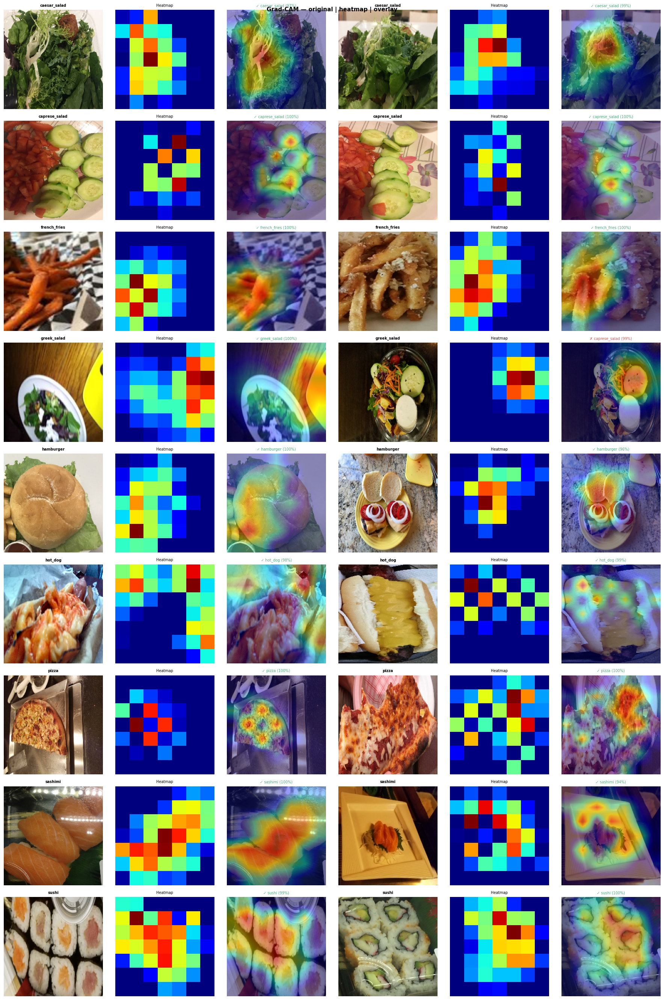

In [75]:
n_samples = 2
fig, axes = plt.subplots(len(class_names), n_samples*3, figsize=(n_samples*9, len(class_names)*3))
samples_per_class = {cls: [] for cls in range(len(class_names))}
for (batch_raw, labels_raw), (batch_prep, _) in zip(ds_test_raw, best_ds_test):
    preds = best_model.predict(batch_prep, verbose=0)
    for i in range(len(batch_raw)):
        true_cls = int(np.argmax(labels_raw[i])); pred_cls = int(np.argmax(preds[i]))
        if len(samples_per_class[true_cls]) < n_samples:
            samples_per_class[true_cls].append({
                "img_raw": batch_raw[i].numpy().astype("uint8"),
                "img_prep": batch_prep[i].numpy(), "true":true_cls, "pred":pred_cls,
                "conf": float(preds[i][pred_cls])})
    if all(len(v) >= n_samples for v in samples_per_class.values()): break
for row, cls_idx in enumerate(range(len(class_names))):
    for col_idx, s in enumerate(samples_per_class[cls_idx][:n_samples]):
        img_raw = s["img_raw"]; img_prep = np.expand_dims(s["img_prep"],0)
        pred_cls = s["pred"]; correct = s["true"] == pred_cls
        heatmap = make_gradcam_heatmap(img_prep, best_model, LAST_CONV_LAYER, pred_cls)
        overlay = overlay_gradcam(img_raw, heatmap)
        bc = col_idx*3
        axes[row,bc].imshow(img_raw); axes[row,bc].set_title(class_names[cls_idx],fontsize=7,fontweight="bold"); axes[row,bc].axis("off")
        axes[row,bc+1].imshow(heatmap,cmap="jet"); axes[row,bc+1].set_title("Heatmap",fontsize=7); axes[row,bc+1].axis("off")
        color = "#4caf7d" if correct else "#e05c5c"
        axes[row,bc+2].imshow(overlay)
        axes[row,bc+2].set_title(f"{'✓' if correct else '✗'} {class_names[pred_cls]} ({s['conf']*100:.0f}%)",fontsize=7,color=color)
        axes[row,bc+2].axis("off")
plt.suptitle("Grad-CAM — original | heatmap | overlay", fontweight="bold",fontsize=11)
plt.tight_layout(); plt.show()

#### 8.1.2 Grad-CAM focusing on prediction error

This cell focuses on the images that were misclassified by the model. For each error case, Grad-CAM is used to understand which image regions influenced the wrong prediction.

The first error is a greek_salad predicted as caprese_salad with very high confidence. Looking at the heatmap, the model focuses mainly on the cucumber and the round light ingredients. This can explain the mistake, because cucumber and similar round shapes appear often in salad images and may make the model confuse different salad categories.

The second error is a hamburger predicted as hot_dog. In this case, the mistake is understandable because the hamburger is photographed from a side view and has a long vertical shape. Visually, it looks closer to the typical structure of a hot dog than to a standard hamburger seen from the front. The heatmap also focuses on the central part of the sandwich, which is relevant, but the shape probably misled the model.

The third error is another greek_salad, predicted as sashimi. This image is more complex: it contains salad ingredients, but also elongated pieces of food on top that can visually resemble fish or sliced raw food. The heatmap focuses on this central area, so the model seems to base its prediction on the most misleading part of the image.

Overall, these errors are not random. Grad-CAM shows that the model usually focuses on meaningful regions, but in these cases the visual cues are ambiguous or similar to another class. This is especially relevant for small classes such as greek_salad, where the model has fewer examples to learn from. The analysis suggests that some errors could be reduced by adding more images for minority classes and by improving the balance between visually similar categories.

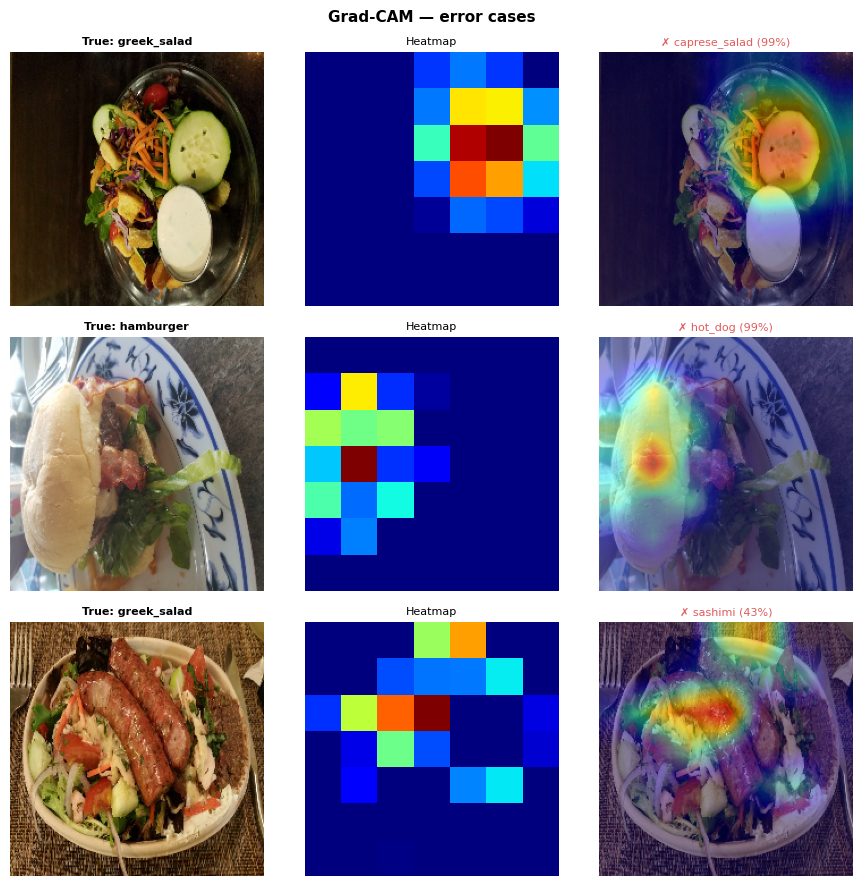

In [76]:
errors = []
for (batch_raw, labels_raw), (batch_prep, _) in zip(ds_test_raw, best_ds_test):
    preds = best_model.predict(batch_prep, verbose=0)
    for i in range(len(batch_raw)):
        true_cls=int(np.argmax(labels_raw[i])); pred_cls=int(np.argmax(preds[i]))
        if true_cls != pred_cls:
            errors.append({"img_raw":batch_raw[i].numpy().astype("uint8"),
                           "img_prep":batch_prep[i].numpy(), "true":true_cls,
                           "pred":pred_cls, "conf":float(preds[i][pred_cls])})
    if len(errors) >= 8: break

n_show = min(8, len(errors))
fig, axes = plt.subplots(n_show, 3, figsize=(9, n_show*3))
if n_show == 1: axes = [axes]
for i, err in enumerate(errors[:n_show]):
    img_raw=err["img_raw"]; img_prep=np.expand_dims(err["img_prep"],0); pred_cls=err["pred"]
    heatmap=make_gradcam_heatmap(img_prep,best_model,LAST_CONV_LAYER,pred_cls)
    overlay=overlay_gradcam(img_raw,heatmap)
    axes[i][0].imshow(img_raw); axes[i][0].set_title(f"True: {class_names[err['true']]}",fontsize=8,fontweight="bold"); axes[i][0].axis("off")
    axes[i][1].imshow(heatmap,cmap="jet"); axes[i][1].set_title("Heatmap",fontsize=8); axes[i][1].axis("off")
    axes[i][2].imshow(overlay); axes[i][2].set_title(f"✗ {class_names[pred_cls]} ({err['conf']*100:.0f}%)",fontsize=8,color="#e05c5c"); axes[i][2].axis("off")
plt.suptitle("Grad-CAM — error cases", fontweight="bold",fontsize=11); plt.tight_layout(); plt.show()

### 8.2 LIME

LIME is used as a second explainability method to analyze the predictions of the selected model. Unlike Grad-CAM, LIME does not look inside the neural network. Instead, it treats the model as a black box: it slightly modifies parts of the image, observes how the prediction changes, and identifies which regions were most important for each class.

In this project, LIME is applied especially to the error cases. The goal is to understand which parts of the image pushed the model toward the wrong prediction. For each image, LIME shows the explanations for the top-3 predicted classes, allowing us to compare why the model preferred one class over another.

For example, in the greek_salad image predicted as caprese_salad, LIME highlights mainly the cucumber and round light ingredients. These elements are visually important and may explain why the model confused the two salad categories.

In the hamburger image predicted as hot_dog, LIME highlights the bread and the elongated central structure of the sandwich. This supports the interpretation already suggested by Grad-CAM: the model probably associated the vertical and elongated shape with a hot dog rather than with a hamburger.

This analysis is useful because it shows that the model is not making errors completely at random. In many cases, the wrong prediction is linked to specific visual cues that are actually present in the image but are misleading. Therefore, LIME helps us better understand the model's decision process and confirms that some errors are caused by visual ambiguity, class similarity and the small number of examples for certain categories.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 11.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✓ LIME initialized

LIME — Incorrect cases

True: greek_salad | Pred: caprese_salad (0.992) ✗


  0%|          | 0/2000 [00:00<?, ?it/s]

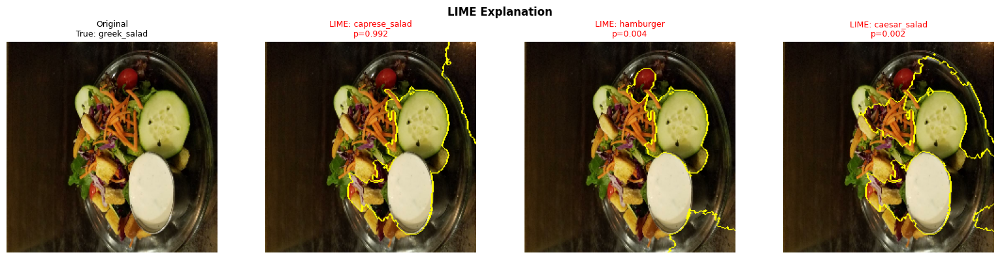


True: hamburger | Pred: hot_dog (0.994) ✗


  0%|          | 0/2000 [00:00<?, ?it/s]

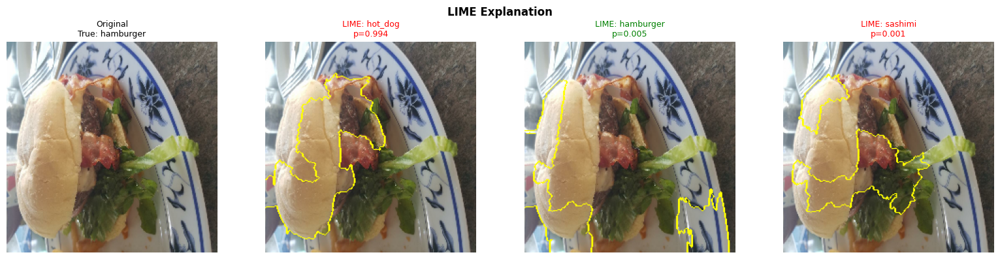


True: greek_salad | Pred: sashimi (0.432) ✗


  0%|          | 0/2000 [00:00<?, ?it/s]

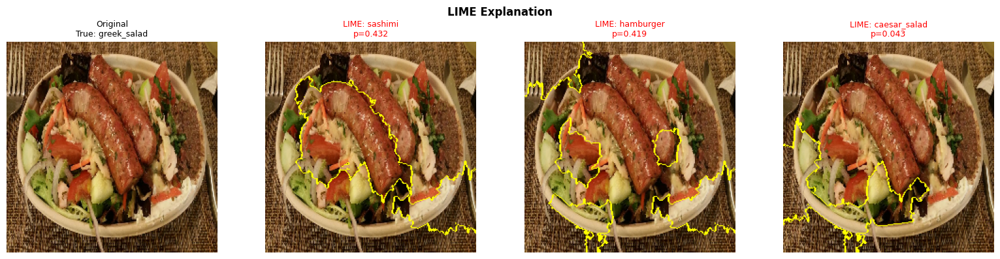


LIME — Correct case

True: pizza | Pred: pizza (1.000) ✓


  0%|          | 0/2000 [00:00<?, ?it/s]

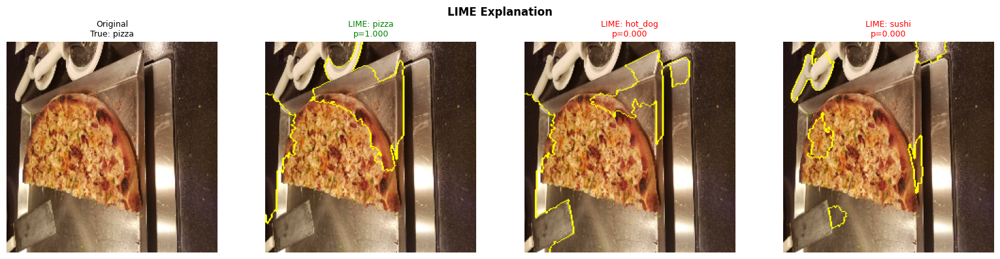


True: hamburger | Pred: hamburger (1.000) ✓


  0%|          | 0/2000 [00:00<?, ?it/s]

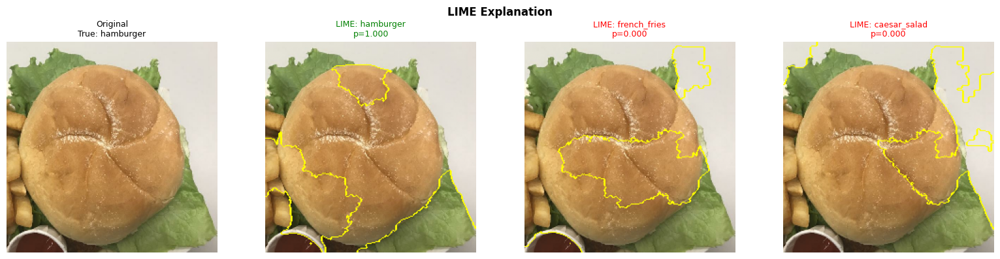

In [77]:
# ── Import LIME ───────────────────────────────────────────────────────────────
!pip install lime -q
from lime import lime_image
from skimage.segmentation import mark_boundaries
# ── LIME-compatible prediction function ───────────────────────────────
def predict_fn_lime(images):
    """LIME passes images as NumPy arrays (N, H, W, 3) with values ranging from 0 to 255"""
    batch = effnet_preprocess(tf.constant(images, dtype=tf.float32))
    probs = best_model(batch, training=False).numpy()
    return probs

explainer = lime_image.LimeImageExplainer()
print("✓ LIME initialized")

# ── Function show_lime ────────────────────────────────────────────────────────
def show_lime(img_np, true_label, num_samples=2000):
    """
    img_np      : numpy array uint8 (H, W, 3) 224x224
    true_label  : string containing the actual class name
    """
    # Originale prediction
    probs      = predict_fn_lime([img_np])
    pred_idx   = probs.argmax()
    pred_class = class_names[pred_idx]
    pred_prob  = probs[0, pred_idx]
    correct    = pred_class == true_label
    print(f"True: {true_label} | Pred: {pred_class} ({pred_prob:.3f}) "
          f"{'✓' if correct else '✗'}")

    # LIME Explanation
    explanation = explainer.explain_instance(
        img_np,
        predict_fn_lime,
        top_labels=3,
        hide_color=0,
        num_samples=num_samples,
        random_seed=42
    )

    # Display: original + top 3 classes
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(img_np)
    axes[0].set_title(f"Original\nTrue: {true_label}", fontsize=9)
    axes[0].axis("off")

    for i, label_idx in enumerate(explanation.top_labels[:3]):
        temp, mask = explanation.get_image_and_mask(
            label_idx,
            positive_only=True,
            num_features=5,
            hide_rest=False
        )
        axes[i + 1].imshow(mark_boundaries(temp / 255.0, mask))
        cls_name = class_names[label_idx]
        color    = "green" if cls_name == true_label else "red"
        axes[i + 1].set_title(
            f"LIME: {cls_name}\np={probs[0, label_idx]:.3f}",
            fontsize=9, color=color
        )
        axes[i + 1].axis("off")

    plt.suptitle("LIME Explanation", fontweight="bold", fontsize=12)
    plt.tight_layout()
    plt.show()

# ── Sample Collection: Incorrect + Correct ──────────────────────────────────────
wrong_imgs,   wrong_labels_list   = [], []
correct_imgs, correct_labels_list = [], []

for batch_raw, labels_raw in ds_test_raw:
    for i in range(len(batch_raw)):
        img_np    = batch_raw[i].numpy().astype("uint8")
        true_idx  = int(np.argmax(labels_raw[i]))
        true_name = class_names[true_idx]

        probs    = predict_fn_lime([img_np])
        pred_idx = probs.argmax()

        if pred_idx != true_idx and len(wrong_imgs) < 4:
            wrong_imgs.append(img_np)
            wrong_labels_list.append(true_name)

        elif pred_idx == true_idx and len(correct_imgs) < 2:
            correct_imgs.append(img_np)
            correct_labels_list.append(true_name)

    if len(wrong_imgs) >= 4 and len(correct_imgs) >= 2:
        break

# ── LIME on Incorrect Cases ──────────────────────────────────────────────────────
print("\n" + "="*50)
print("LIME — Incorrect cases")
print("="*50)
for img_np, true in zip(wrong_imgs, wrong_labels_list):
    print(f"\n{'='*50}")
    show_lime(img_np, true, num_samples=2000)

# ── LIME on 2 Correct case ────────────────────────────────────
print("\n" + "="*50)
print("LIME — Correct case")
print("="*50)
random.seed(42)
sample_correct = random.sample(list(zip(correct_imgs, correct_labels_list)),
                               min(2, len(correct_imgs)))
for img_np, true in sample_correct:
    print(f"\n{'='*50}")
    show_lime(img_np, true, num_samples=2000)

## **9. Live Interface — Gradio**

The final part of the project implements a simple live interface using Gradio The goal of this section is to make the trained model usable in a more practical way, without interacting directly with the notebook code.

Through the interface, the user can upload a food image and obtain two outputs: the top-3 predicted classes with their confidence scores, and a Grad-CAM heatmap showing which parts of the image influenced the prediction. This makes the model easier to test and also adds an explainability component to the final application.

The Gradio cell is designed as a standalone cell. This means that it can run independently, without re-running the whole notebook from the beginning. The cell loads everything it needs directly from Drive: the best saved model, the class names, the preprocessing function and the Grad-CAM utilities. This is useful because training all models again would be time-consuming, while the interface only needs the final selected model.

The prediction function first converts the uploaded image to RGB, resizes it to 224x224 pixels and applies the EfficientNetV2S preprocessing. Then, the model predicts the class probabilities and returns the top results. At the same time, Grad-CAM is computed on the predicted class and overlaid on the original image.

Finally, demo.launch(share=True) creates a temporary public link that allows the interface to be opened in a browser. In this way, the model can be tested interactively by uploading new food images, even outside the notebook environment.

In [79]:
# ═══════════════════════════════════════════════════════════════════════════════
# §9 — LIVE GRADIO INTERFACE  ✦  standalone cell
# This cell can run on its own without anything above having been executed.
# Loads from Drive: model, class_names, split_index.csv, preprocessing.
# ═══════════════════════════════════════════════════════════════════════════════

# ── 0. Imports ────────────────────────────────────────────────────────────────
import os, pickle
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

# ── 1. Drive ──────────────────────────────────────────────────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception as e:
    print(f"Drive already mounted or error: {e}")

SAVE_DIR = "/content/drive/MyDrive/FDL_project_Cesaratto_Porro/FDL_checkpoints"
assert os.path.isdir(SAVE_DIR), f"SAVE_DIR not found: {SAVE_DIR}"

# ── 2. Classes from split_index.csv ───────────────────────────────────────────
_split_path = f"{SAVE_DIR}/split_index.csv"
if os.path.exists(_split_path):
    df_split = pd.read_csv(_split_path)
    class_names = sorted(df_split["class"].unique().tolist())
else:
    class_names = [
        "caesar_salad", "caprese_salad", "french_fries",
        "greek_salad",  "hamburger",     "hot_dog",
        "pizza",        "sashimi",       "sushi"
    ]
    print("⚠ split_index.csv not found — using hardcoded class_names (9 classes)")
print(f"✓ classes ({len(class_names)}): {class_names}")

IMG_SIZE = 224

# ── 3. EfficientNetV2S preprocessing ───────────────────────────────────────────
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input as effnet_preprocess

# ── 4. Load model ──────────────────────────────────────────────────────────────
_model_path = f"{SAVE_DIR}/best_effnet_fe.keras"
assert os.path.exists(_model_path), f"Model not found: {_model_path}"
best_model = keras.models.load_model(_model_path)
print(f"✓ Model loaded: {_model_path}")

# ── 5. Grad-CAM helpers ────────────────────────────────────────────────────────
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = keras.Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None: pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img, heatmap, alpha=0.45):
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    jet = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    jet_rgb = cv2.cvtColor(jet, cv2.COLOR_BGR2RGB)
    return np.uint8(img * (1-alpha) + jet_rgb * alpha)

# Find the last conv layer of the EfficientNetV2S backbone
LAST_CONV_LAYER = None
for layer in reversed(best_model.layers):
    if isinstance(layer, keras.layers.Conv2D) or "conv" in layer.name.lower():
        LAST_CONV_LAYER = layer.name; break
if LAST_CONV_LAYER is None: LAST_CONV_LAYER = "top_conv"  # known fallback for EffNetV2S
print(f"✓ Last conv layer: {LAST_CONV_LAYER}")

# ── 6. Prediction function ────────────────────────────────────────────────────
!pip install gradio -q
import gradio as gr
from PIL import Image as PILImage

def predict_with_gradcam(image):
    # FIX: convert to RGB before resizing, to handle grayscale images
    # (shape HxW) or images with an alpha channel RGBA (shape HxWx4).
    image = image.convert("RGB")
    img_np = np.array(image.resize((IMG_SIZE, IMG_SIZE))).astype("float32")
    img_prep = effnet_preprocess(img_np)
    img_batch = np.expand_dims(img_prep, 0)
    preds = best_model.predict(img_batch, verbose=0)[0]
    pred_idx = int(np.argmax(preds))
    confidence = {class_names[i]: float(preds[i]) for i in range(len(class_names))}
    try:
        heatmap = make_gradcam_heatmap(img_batch, best_model, LAST_CONV_LAYER, pred_index=pred_idx)
        overlay = overlay_gradcam(img_np.astype("uint8"), heatmap, alpha=0.45)
        overlay_img = PILImage.fromarray(overlay)
    except Exception as e:
        print(f"⚠ Grad-CAM failed: {e}")
        overlay_img = image
    return confidence, overlay_img

# ── 7. Gradio interface ───────────────────────────────────────────────────────
with gr.Blocks(title="Food Classifier — FDL") as demo:
    gr.Markdown("# 🍕 Food Image Classifier")
    gr.Markdown("Upload a food image → predicted class + Grad-CAM heatmap")
    with gr.Row():
        with gr.Column():
            input_img = gr.Image(type="pil", label="Input image")
            btn = gr.Button("Classify", variant="primary")
        with gr.Column():
            output_conf    = gr.Label(num_top_classes=3, label="Top-3 Predictions")
            output_gradcam = gr.Image(label="Grad-CAM Heatmap")
    btn.click(fn=predict_with_gradcam, inputs=input_img, outputs=[output_conf, output_gradcam])

demo.launch(share=True, debug=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ classes (9): ['caesar_salad', 'caprese_salad', 'french_fries', 'greek_salad', 'hamburger', 'hot_dog', 'pizza', 'sashimi', 'sushi']
✓ Model loaded: /content/drive/MyDrive/FDL_project_Cesaratto_Porro/FDL_checkpoints/best_effnet_fe.keras
✓ Last conv layer: top_conv
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://83a6c62d51b59175d1.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
